# Fashion MNIST 모델 선택 및 평가 보고서

In [1]:
import json
from pathlib import Path
ROOT = Path("/home/link/link_dl")
BASE = ROOT / "_03_homeworks/homework_3/experiments"
print((BASE / "statistics.json").read_text())

{
  "mean": 0.2855656942074541,
  "std": 0.3527285864947437,
  "split_seed": 42,
  "train_samples": 55000,
  "validation_samples": 5000,
  "pixels": 43120000,
  "pixel_conversion": "CPU float32 / 255, statistics accumulated in float64"
}

## 모델 선택/튜닝 실행 결과

검증 loss로 저장된 체크포인트를 재평가한 검증 정확도를 사용한다. 모델 선택/튜닝에는 테스트 데이터를 사용하지 않았다.

In [2]:
results = [json.loads(p.read_text()) for p in BASE.glob("*/result.json")]
for r in results:
    print(r["configuration"]["id"], r["checkpoint_validation_accuracy"], r["wandb_url"])

baseline_cnn  89.58%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5jx5co3u
baseline_googlenet  90.02%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/d9yyna63
baseline_nin  91.40%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qww2imrf
baseline_resnet  90.52%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5nf4jdq4
baseline_vgg  91.88%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qzq04czt
batch_lr_nin_94d71663ef65  90.30%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/wxovq9ef
batch_lr_nin_fdd536e9adb7  91.18%  https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/lpjwncuy
batch_lr_nin_14071cd582f5  10.96%  https://wandb.ai/existenceo

In [3]:
final_result = json.loads((BASE / "input_normalization_vgg_pad/normalize_on/result.json").read_text())
print(json.dumps(final_result, indent=2, ensure_ascii=False))

{
  "status": "completed",
  "configuration": {
    "id": "normalize_on",
    "stage": "input_normalization_vgg_pad",
    "args": [
      "--model",
      "vgg",
      "--wandb",
      "-b",
      "256",
      "-e",
      "100",
      "-v",
      "1",
      "-p",
      "10",
      "-d",
      "0.00001",
      "-o",
      "3",
      "-r",
      "0.0003",
      "-w",
      "0.0001",
      "--split_seed",
      "42",
      "--mean",
      "0.2855656942074541",
      "--std",
      "0.3527285864947437",
      "-n",
      "1",
      "--augment",
      "--no-dropout",
      "--vgg_variant",
      "pad",
      "--seed",
      "42",
      "--normalize"
    ]
  },
  "args": {
    "wandb": true,
    "batch_size": 256,
    "epochs": 100,
    "learning_rate": 0.0003,
    "validation_intervals": 1,
    "early_stop_patience": 10,
    "early_stop_delta": 1e-05,
    "optimizer": 3,
    "weight_decay": 0.0001,
    "dropout": false,
    "normalization": 1,
    "augment": true,
    "model": "vgg",
    "v

## 선택한 VGG pad와 최적 하이퍼파라미터

VGG의 입력 크기 처리 방법 세 가지를 seed 42·43·44에서 비교했다. VGG pad가 체크포인트 검증 정확도 평균 **93.94%**로 가장 높았다. 이번 비교는 그 설정에서 입력 표준화 옵션만 바꿨다.

| 항목 | 선택 설정 |
| --- | --- |
| 모델 / 입력 | VGG / 28×28의 각 변에 0으로 2픽셀을 채워 32×32로 변환 |
| 옵티마이저 / 학습률 | Adam / 0.0003 |
| 배치 크기 | 256 |
| Weight decay | 0.0001 |
| Early Stopping | 검증 loss 기준, patience 10, min delta 1e-05, 최대 100 epoch |
| 모델 내부 정규화 | Batch Normalization 적용 |
| Dropout | 미적용, 유효 dropout rate 0.0 |
| 증강 | 학습에만 RandomCrop(32, padding=2), RandomHorizontalFlip 적용 |
| 기준 입력 표준화 | 평균 0.2855656942, 표준편차 0.3527285865 |
| 이번 비교의 학습 / 분할 seed | 42 / 42 |

입력 표준화를 적용한 VGG pad의 seed 42 체크포인트를 최종 모델로 선택했다. 문제 3·4는 이 체크포인트를 사용한다.


## 문제 1 · VGG pad 입력 정규화 적용/미적용

같은 VGG pad 설정에서 두 모델을 새로 학습했다. 적용 조건은 학습 데이터 55,000장에서 구한 평균과 표준편차로 입력을 표준화했고, 미적용 조건은 0~1 범위로 변환된 픽셀을 사용했다. 모델 내부 BatchNorm은 양쪽 모두 적용했다.

학습·검증 인덱스, 초기 모델 상태, 셔플 생성기의 초기 상태, 학습 코드의 해시가 일치한다. 데이터 분할(55,000 / 5,000), 모델 구조, 학습 증강과 Early Stopping 규칙도 같다. 검증 loss 기준으로 저장된 체크포인트를 복원해 정확도를 측정했다.


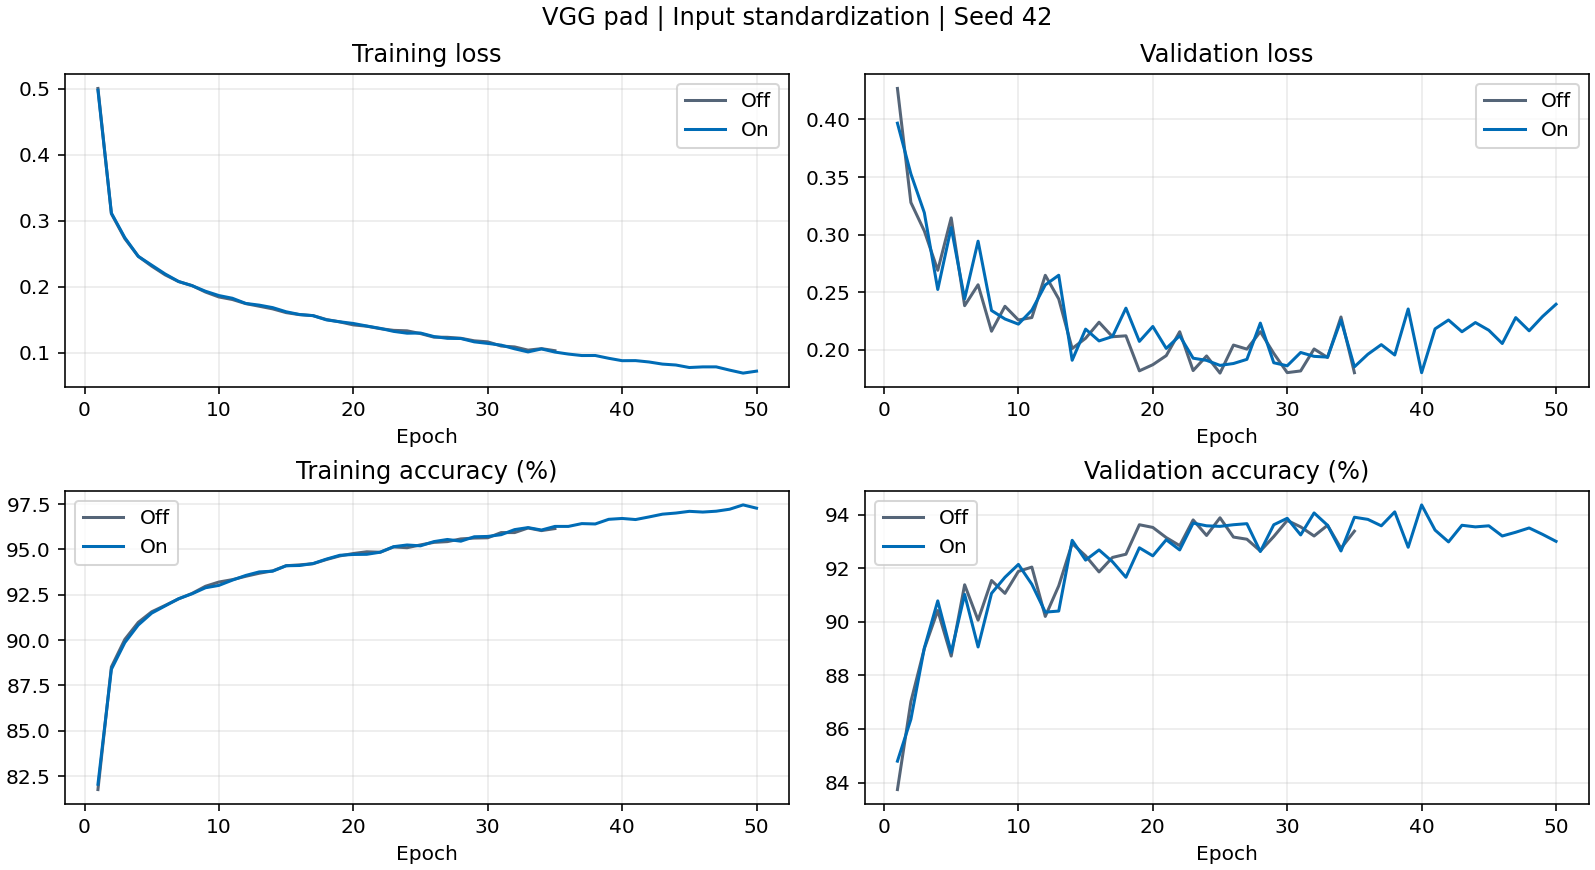

In [111]:
import io
from matplotlib import pyplot as plt
from IPython.display import Image, display

def read_training_history(folder):
    path = folder / "history.jsonl"
    return [json.loads(line) for line in path.read_text().splitlines()]

def comparison_png(folder, off_run, on_run, title):
    metrics = ("Training loss", "Validation loss", "Training accuracy (%)", "Validation accuracy (%)")
    fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
    for label, run, color in (("Off", off_run, "#556578"), ("On", on_run, "#006CB6")):
        rows = read_training_history(folder / run)
        epochs = [row["Epoch"] for row in rows]
        for axis, metric in zip(axes.flat, metrics):
            axis.plot(epochs, [row[metric] for row in rows], label=label, color=color)
    for axis, metric in zip(axes.flat, metrics):
        axis.set(xlabel="Epoch", title=metric)
        axis.grid(alpha=0.25)
        axis.legend(loc="best")
    fig.suptitle(title)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=145)
    plt.close(fig)
    return buffer.getvalue()

display(Image(data=comparison_png(BASE / "input_normalization_vgg_pad", 'normalize_off', 'normalize_on', 'VGG pad | Input standardization | Seed 42')))


### 정규화 실험 결과와 해석

| 조건 | 체크포인트 epoch / 종료 epoch | 체크포인트 검증 loss | 체크포인트 검증 정확도 | W&B |
| --- | ---: | ---: | ---: | --- |
| 미적용 | 25 / 35 | 0.17985 | 93.88% | [미적용 실행](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/h869w7ev) |
| 적용 | 40 / 50 | 0.18021 | 94.36% | [적용 실행](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/w82vrpak) |

초기 5 epoch의 평균 검증 정확도는 미적용 **87.78%**, 적용 **87.96%**로 **+0.18%p** 차이가 났다. 선택한 체크포인트에서 적용 − 미적용의 정확도 차이는 **+0.48%p**, 검증 loss 차이는 **+0.00036**였다. 이 설정에서는 입력 표준화가 체크포인트의 검증 정확도를 높였다.

입력 표준화는 첫 합성곱에 들어가는 픽셀의 평균과 스케일을 바꾸므로 초기 학습 경로에 영향을 줄 수 있다. 이 결과는 내부 BatchNorm이 있는 VGG pad에서 동일 seed 한 쌍을 비교한 값이다. 같은 설정의 기존 pad 실행은 검증 정확도 94.20%였으며, 위 비교표에는 이번에 새로 학습한 두 실행의 결과를 사용했다.


## 문제 2 · 기존 VGG Ablation 비교

기존 VGG resize 탐색 실행에서 옵션 하나만 바뀐 쌍을 골랐다. 각 쌍의 seed, 나머지 실행 설정과 학습 코드 해시는 동일하다. 기법별 기준 설정은 서로 다를 수 있으므로 세 효과를 합산하지 않는다. 검증 loss로 선택한 체크포인트에서 적용 − 미적용 정확도를 계산했다.

| 기법 | 미적용 | 적용 | 검증 정확도 차이 |
| --- | ---: | ---: | ---: |
| Augmentation | [E34](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ytx4b8us) · 92.12% | [E35](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8kr3bwor) · 93.46% | **+1.34%p** |
| Dropout | [E35](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8kr3bwor) · 93.46% | [E33](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bmuwf6n8) · 92.64% | **-0.82%p** |
| Batch Normalization | [E35](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8kr3bwor) · 93.46% | [E26](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/c8ffnosk) · 93.78% | **+0.32%p** |

이 비교 조건에서는 Augmentation과 Batch Normalization 적용 시 검증 정확도가 올랐고 Dropout 적용 시에는 낮아졌다. 각 그래프는 W&B에 기록한 네 지표의 적용·미적용 학습 곡선을 겹쳐 그린 것이다.


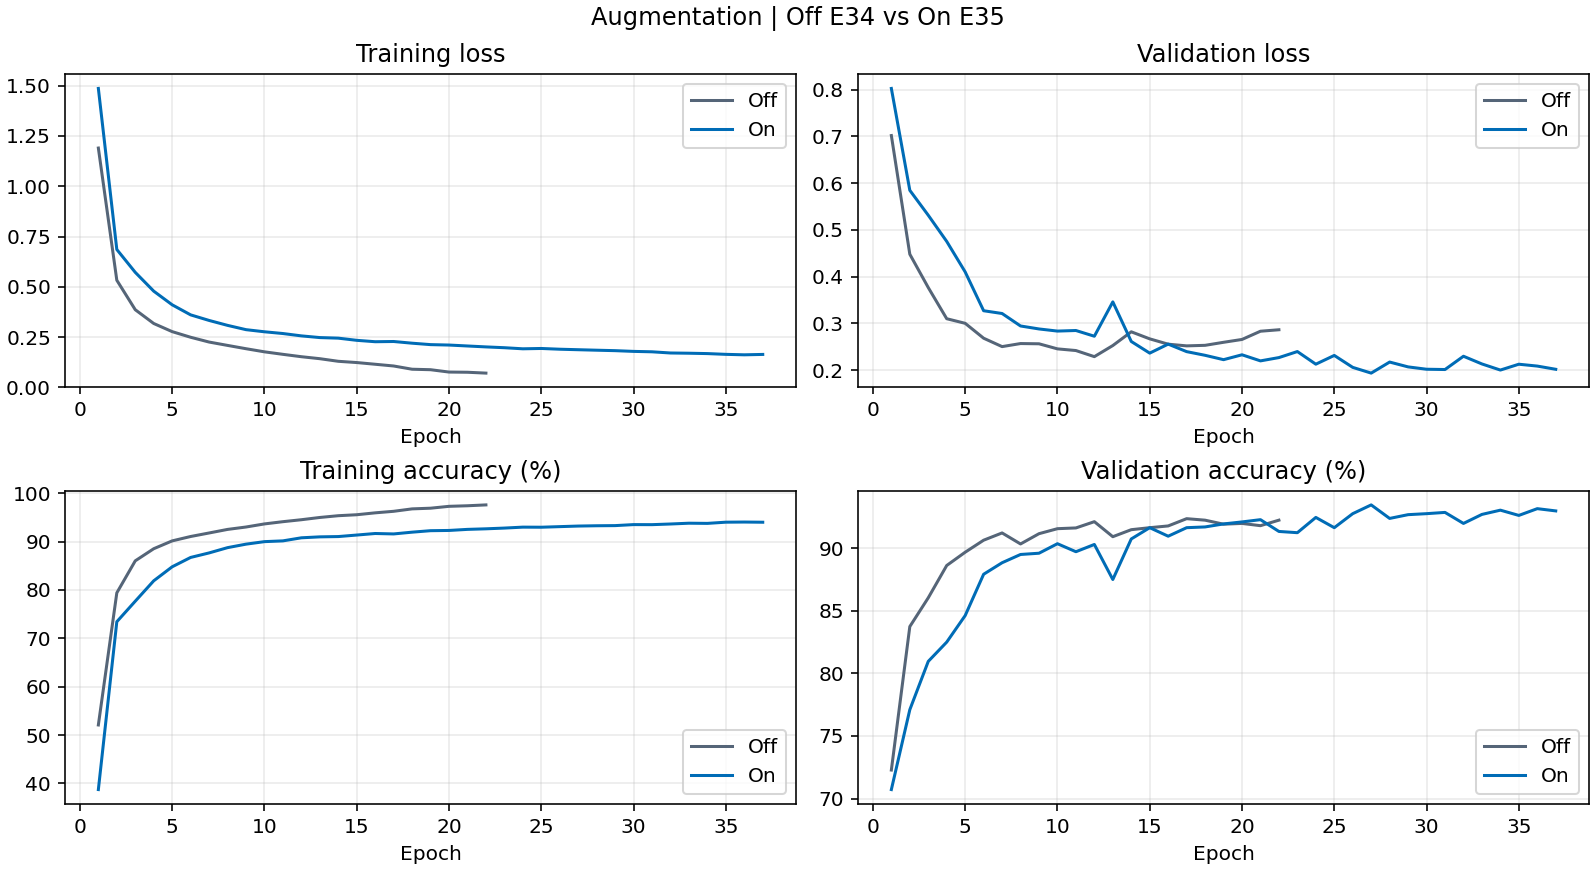

In [112]:
display(Image(data=comparison_png(BASE, 'regularization_vgg_3cc67b2338f1', 'regularization_vgg_515f0d8da6a6', 'Augmentation | Off E34 vs On E35')))


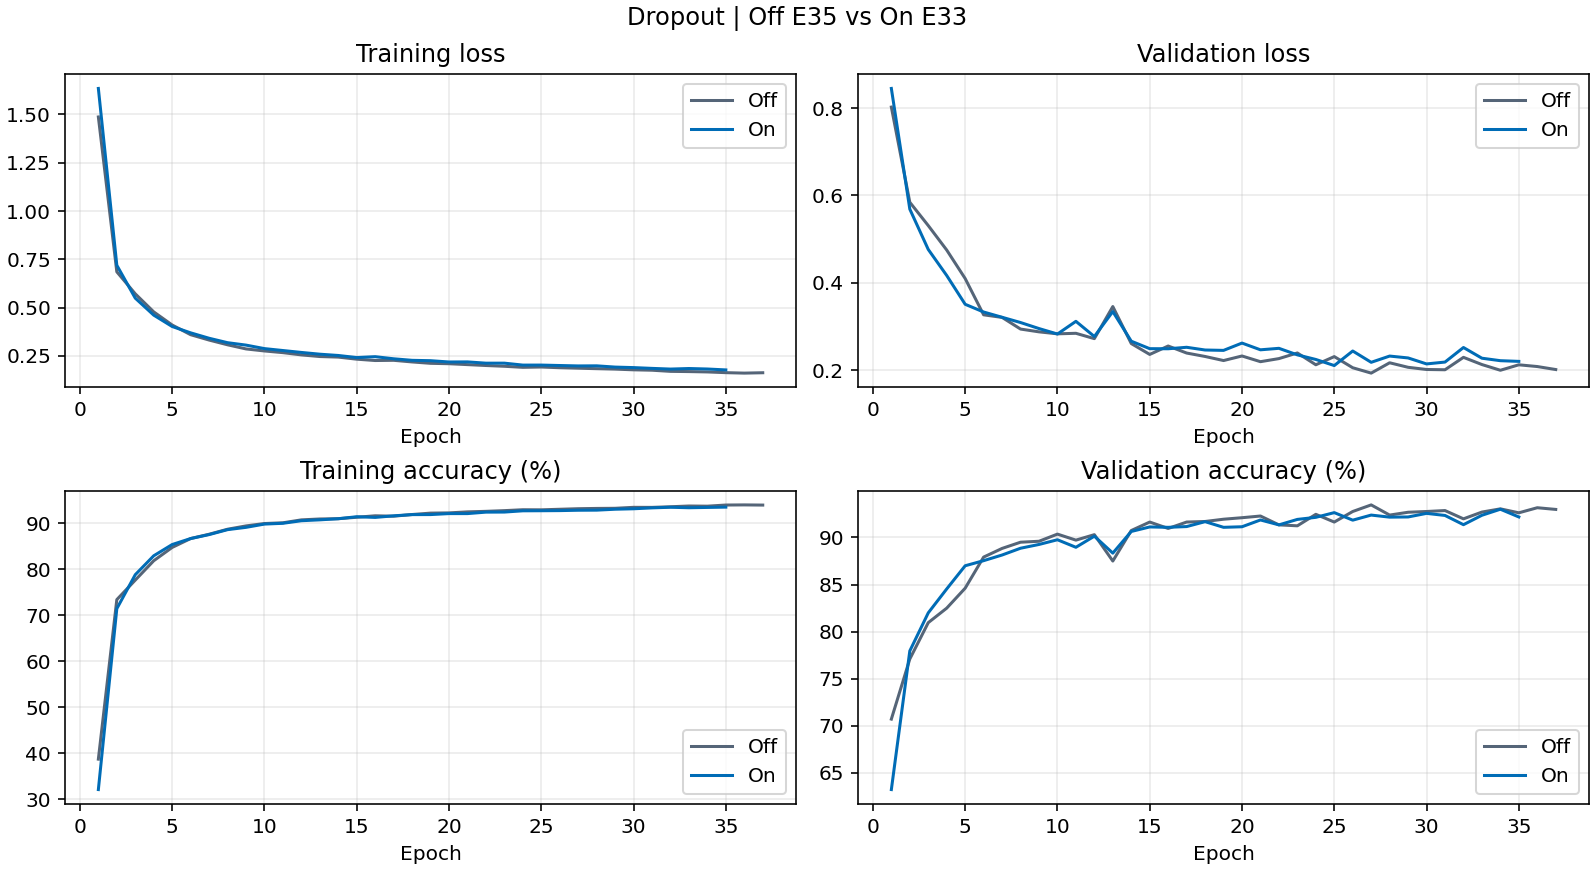

In [113]:
display(Image(data=comparison_png(BASE, 'regularization_vgg_515f0d8da6a6', 'regularization_vgg_38c41d071f6d', 'Dropout | Off E35 vs On E33')))


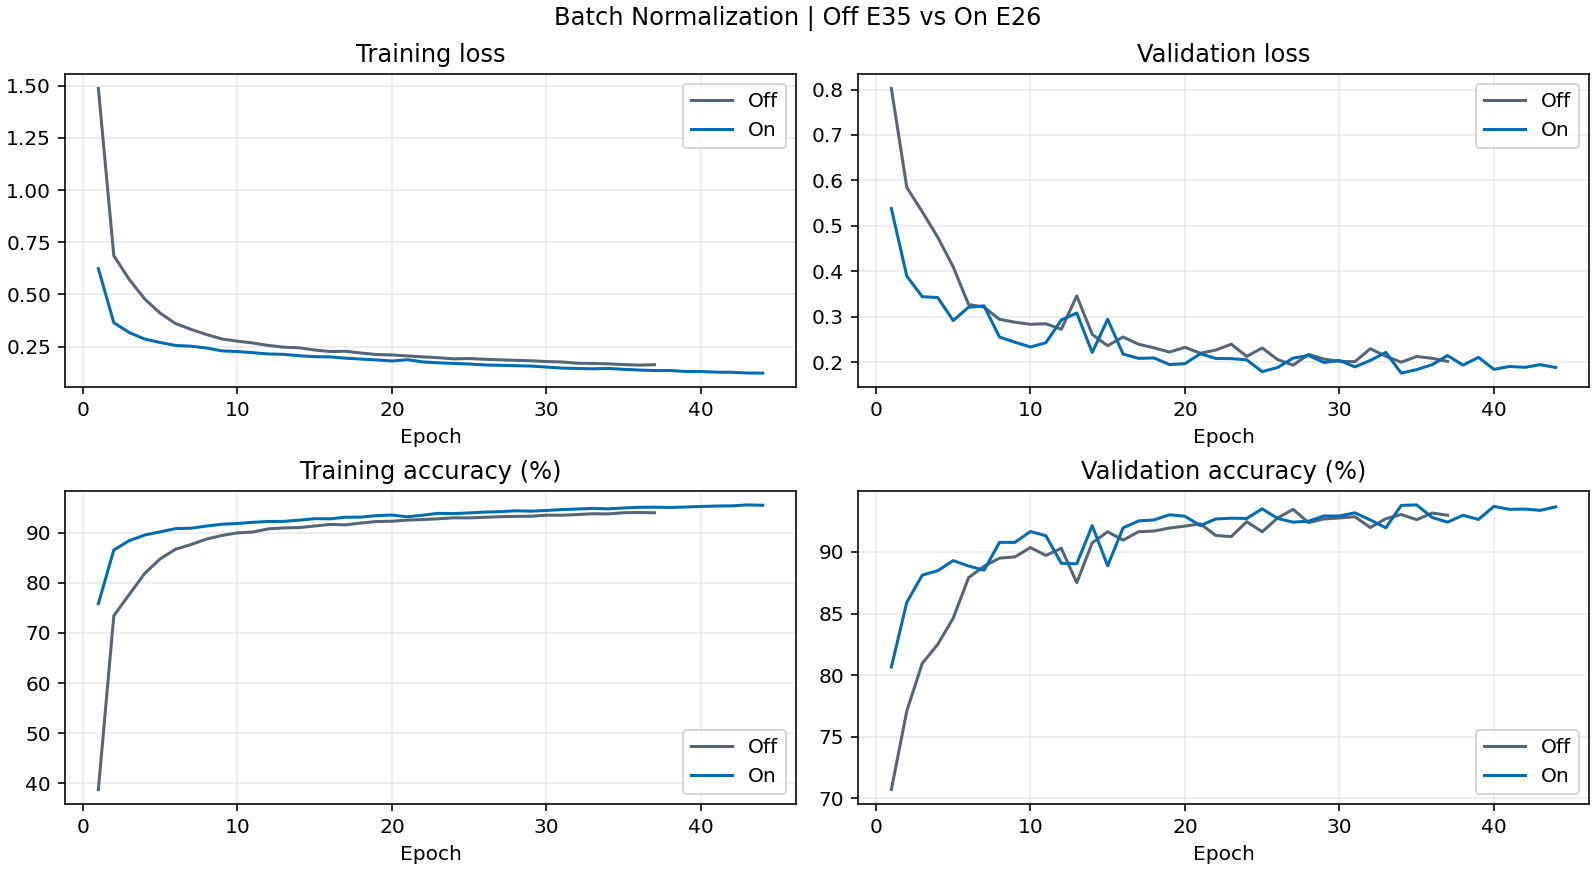

In [114]:
display(Image(data=comparison_png(BASE, 'regularization_vgg_515f0d8da6a6', 'normalization_tuning_vgg_be51f2336604', 'Batch Normalization | Off E35 vs On E26')))


## 문제 3 · 최종 VGG pad의 테스트 평가

입력 정규화를 적용한 seed 42 VGG pad의 체크포인트를 사용했다. 학습과 모델 선택에는 테스트 데이터를 사용하지 않았고, 테스트 전에 검증 정확도 **94.36%**를 재현했다. 평가 중 BatchNorm의 저장 통계가 변하지 않았음을 확인했다.

[W&B 테스트 실행](https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/u6lhs9bz)


In [4]:
EVALUATION = ROOT / "_03_homeworks/homework_3/evaluation/vgg_pad_normalized_seed42"
log_lines = (EVALUATION / "evaluation.log").read_text().splitlines()
print("\n".join(line for line in log_lines if line.startswith(("Restored validation accuracy:", "Test accuracy:"))))

Restored validation accuracy: 94.36% (5000 samples)
Test accuracy: 93.28% (9328/10000)


In [5]:
test_metrics = json.loads((EVALUATION / "metrics.json").read_text())
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

{
  "accuracy": 93.28,
  "num_samples": 10000,
  "num_correct": 9328,
  "num_incorrect": 672,
  "confusion_matrix": [
    [
      911,
      1,
      15,
      11,
      2,
      0,
      59,
      0,
      1,
      0
    ],
    [
      1,
      990,
      1,
      6,
      1,
      0,
      0,
      0,
      1,
      0
    ],
    [
      24,
      0,
      911,
      9,
      29,
      0,
      27,
      0,
      0,
      0
    ],
    [
      21,
      1,
      9,
      926,
      19,
      0,
      23,
      0,
      1,
      0
    ],
    [
      4,
      0,
      34,
      15,
      921,
      0,
      26,
      0,
      0,
      0
    ],
    [
      0,
      0,
      0,
      0,
      0,
      961,
      0,
      25,
      0,
      14
    ],
    [
      108,
      1,
      49,
      15,
      54,
      0,
      770,
      0,
      3,
      0
    ],
    [
      0,
      0,
      0,
      0,
      0,
      0,
      0,
      981,
      0,
      19
    ],
    [
      2,
      1,
      

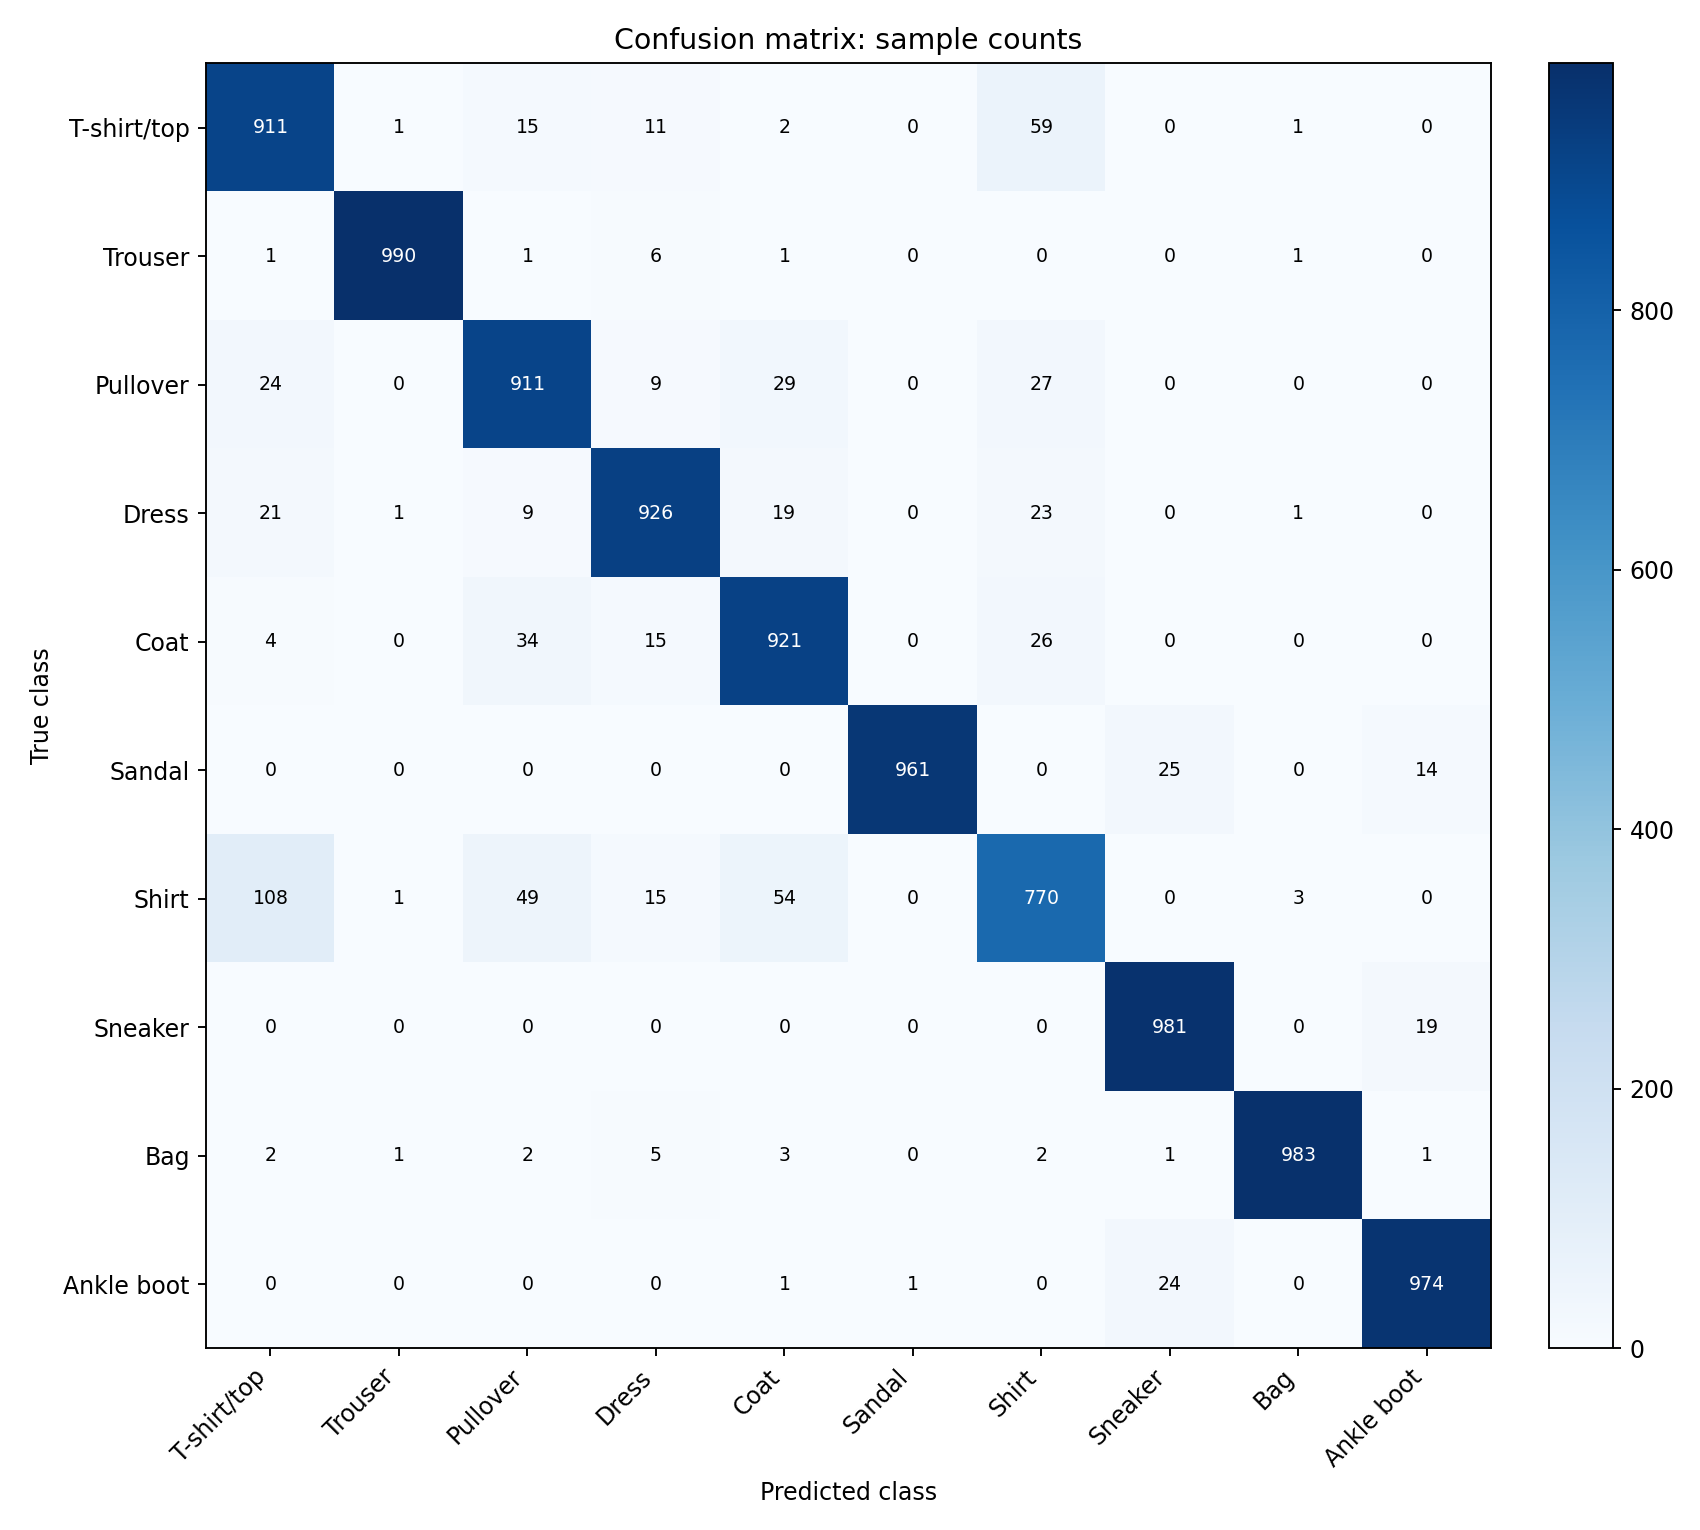

In [6]:
from IPython.display import Image, display
display(Image(filename=str(EVALUATION / 'confusion_matrix_counts.png')))

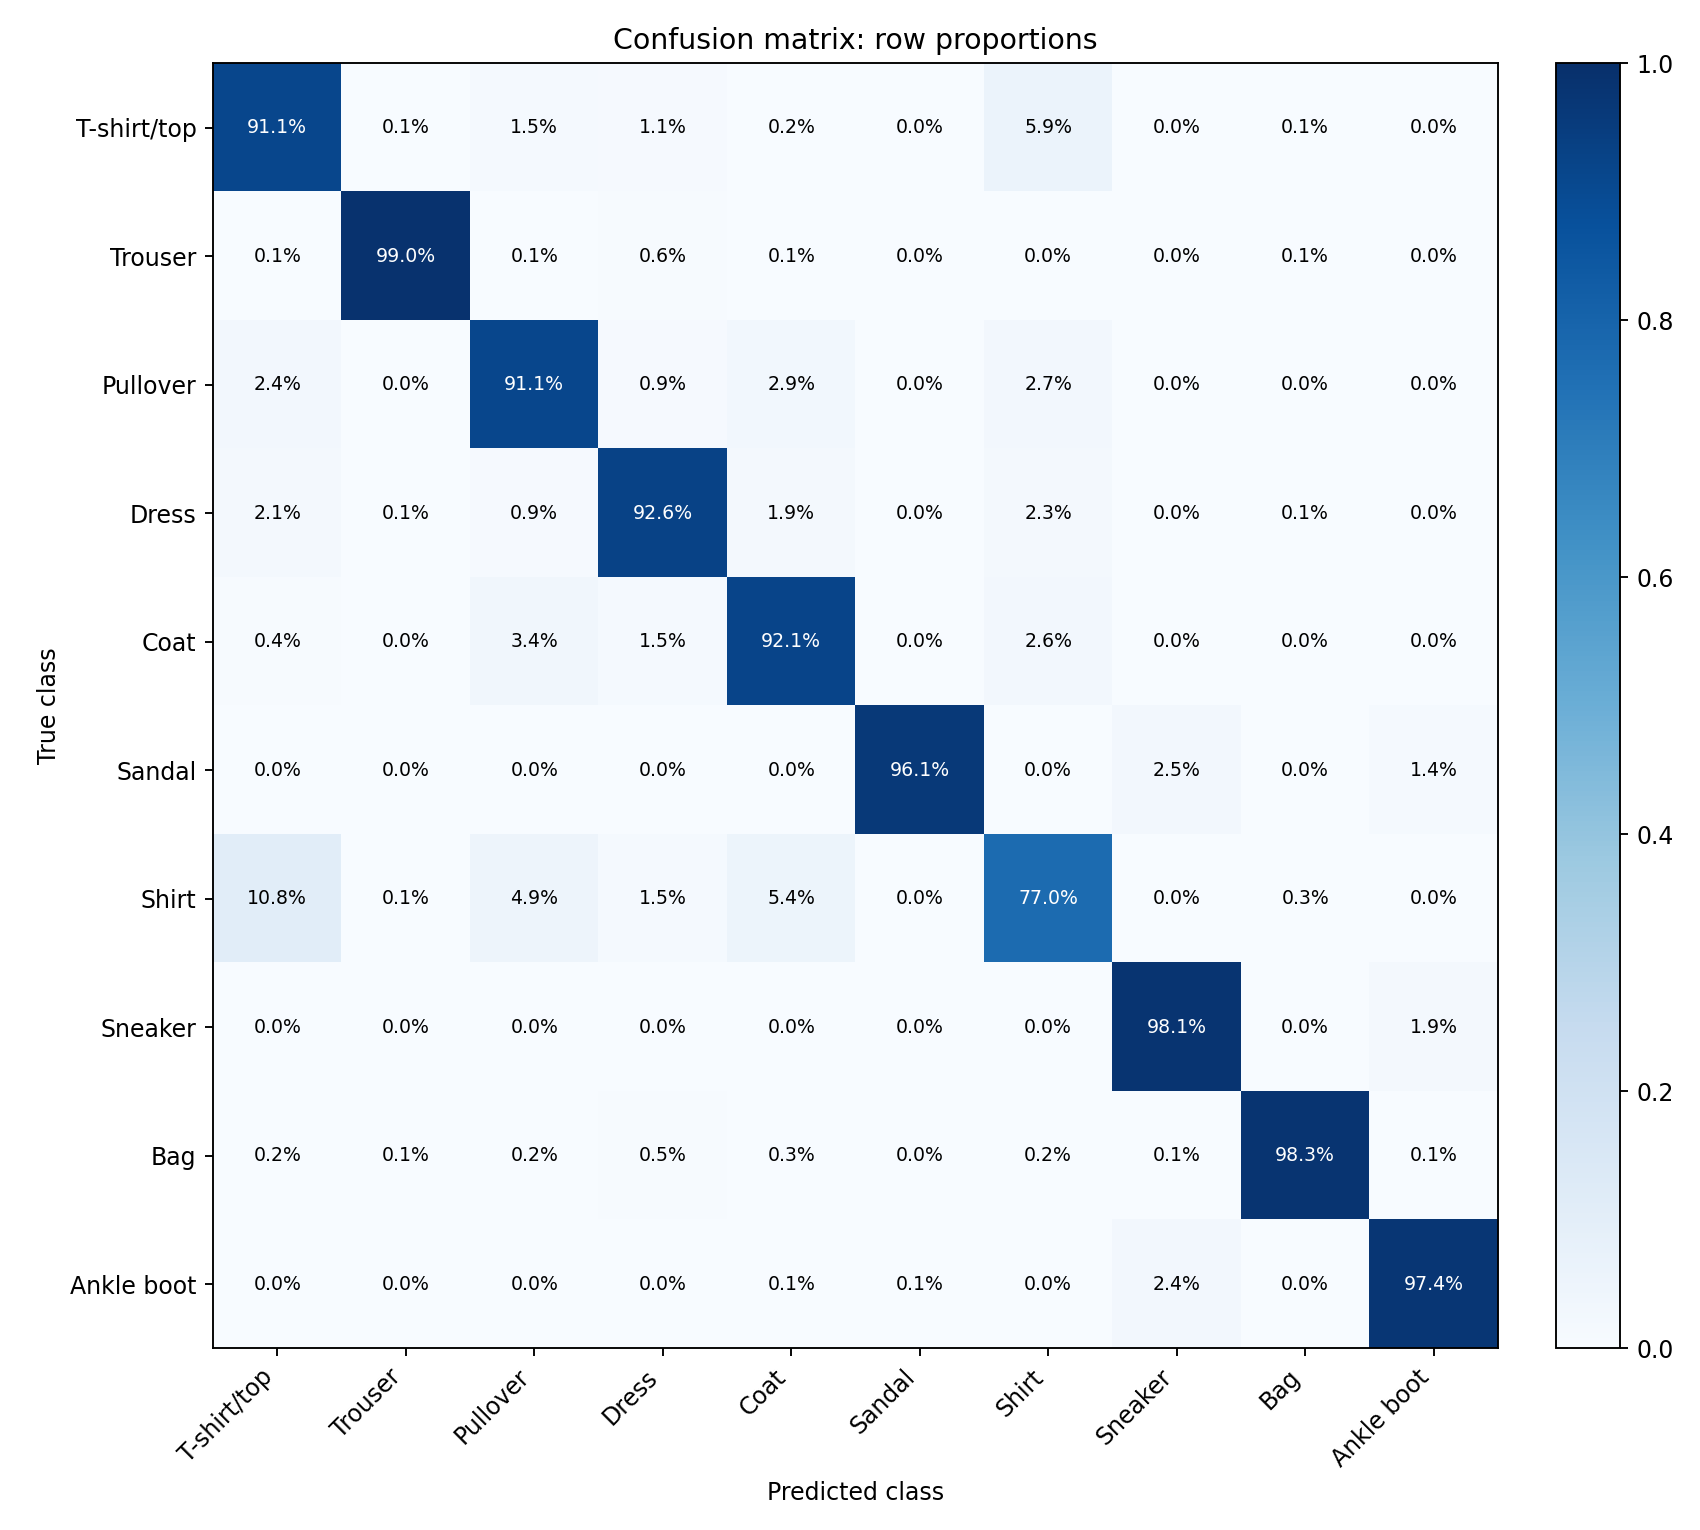

In [7]:
from IPython.display import Image, display
display(Image(filename=str(EVALUATION / 'confusion_matrix_normalized.png')))

### 테스트 정확도와 클래스별 지표

테스트 정확도는 **93.28%** (9,328/10,000)로 과제 기준 93.0%를 충족했다. 검증 정확도와 테스트 정확도의 차이는 1.08%p였다.

Precision은 해당 클래스로 예측한 것 중 실제로 그 클래스인 비율이고, recall은 실제 해당 클래스 중 모델이 맞힌 비율이다. F1은 두 지표의 조화평균이다.


| 클래스 | Precision | Recall | F1 | 표본 수 |
| --- | ---: | ---: | ---: | ---: |
| T-shirt/top | 85.06% | 91.10% | 87.98% | 1000 |
| Trouser | 99.60% | 99.00% | 99.30% | 1000 |
| Pullover | 89.23% | 91.10% | 90.15% | 1000 |
| Dress | 93.82% | 92.60% | 93.21% | 1000 |
| Coat | 89.42% | 92.10% | 90.74% | 1000 |
| Sandal | 99.90% | 96.10% | 97.96% | 1000 |
| Shirt | 84.90% | 77.00% | 80.76% | 1000 |
| Sneaker | 95.15% | 98.10% | 96.60% | 1000 |
| Bag | 99.39% | 98.30% | 98.84% | 1000 |
| Ankle boot | 96.63% | 97.40% | 97.01% | 1000 |


### 낮은 클래스 지표와 혼동

최저 precision은 **Shirt 84.90%**, 최저 recall은 **Shirt 77.00%**였다. 가장 많이 혼동한 클래스쌍은 **T-shirt/top ↔ Shirt**로, 양방향 합계는 **167장**(59장 + 108장)이다. 단방향으로는 Shirt을 T-shirt/top으로 예측한 108장이 가장 많았다.

Shirt 오분류 사례에는 T-shirt/top, Pullover, Coat 등 윤곽이 비슷한 상의가 포함된다. 28×28 이미지에서 깃과 단추 같은 세부 특징이 약하게 보인다는 점이 혼동의 원인일 수 있다.


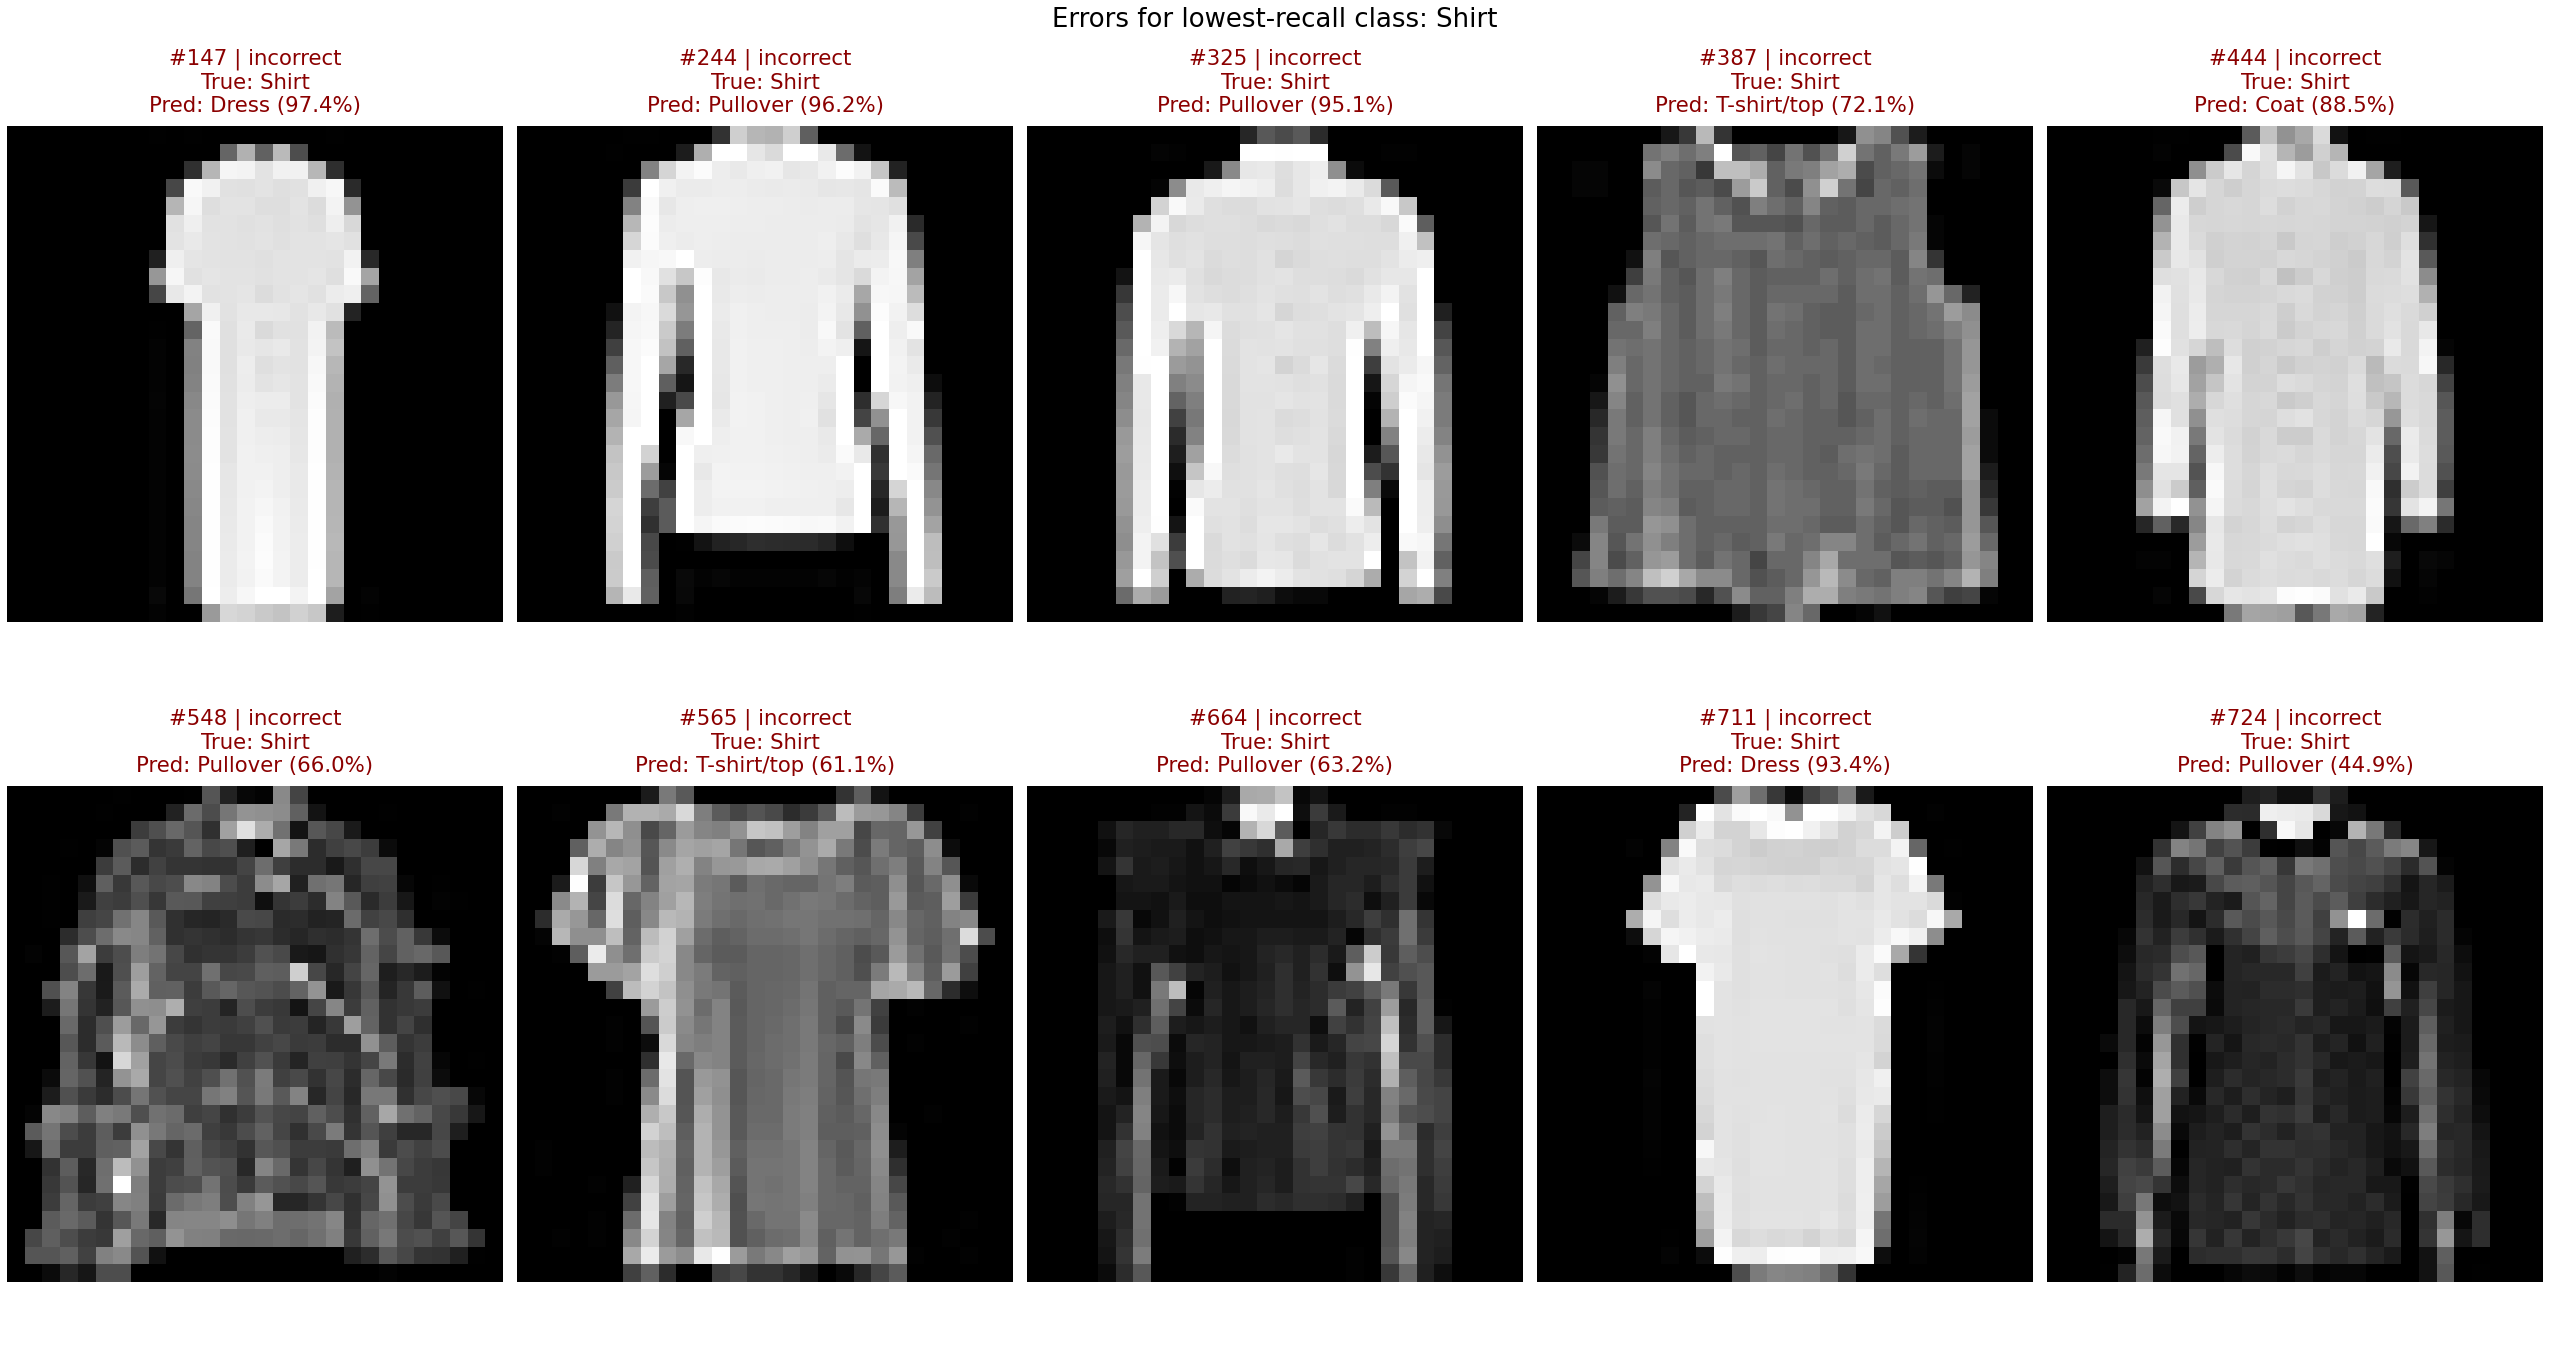

In [8]:
from IPython.display import Image, display
display(Image(filename=str(EVALUATION / 'lowest_recall_errors.png')))

## 문제 4 · 테스트 샘플 예측 분석

seed 42로 전체 테스트 데이터에서 10장을 무작위로 뽑았다. 각 이미지 위에 실제 레이블, 예측 레이블, 정분류 여부, 예측 클래스의 소프트맥스 확률을 표시했다.


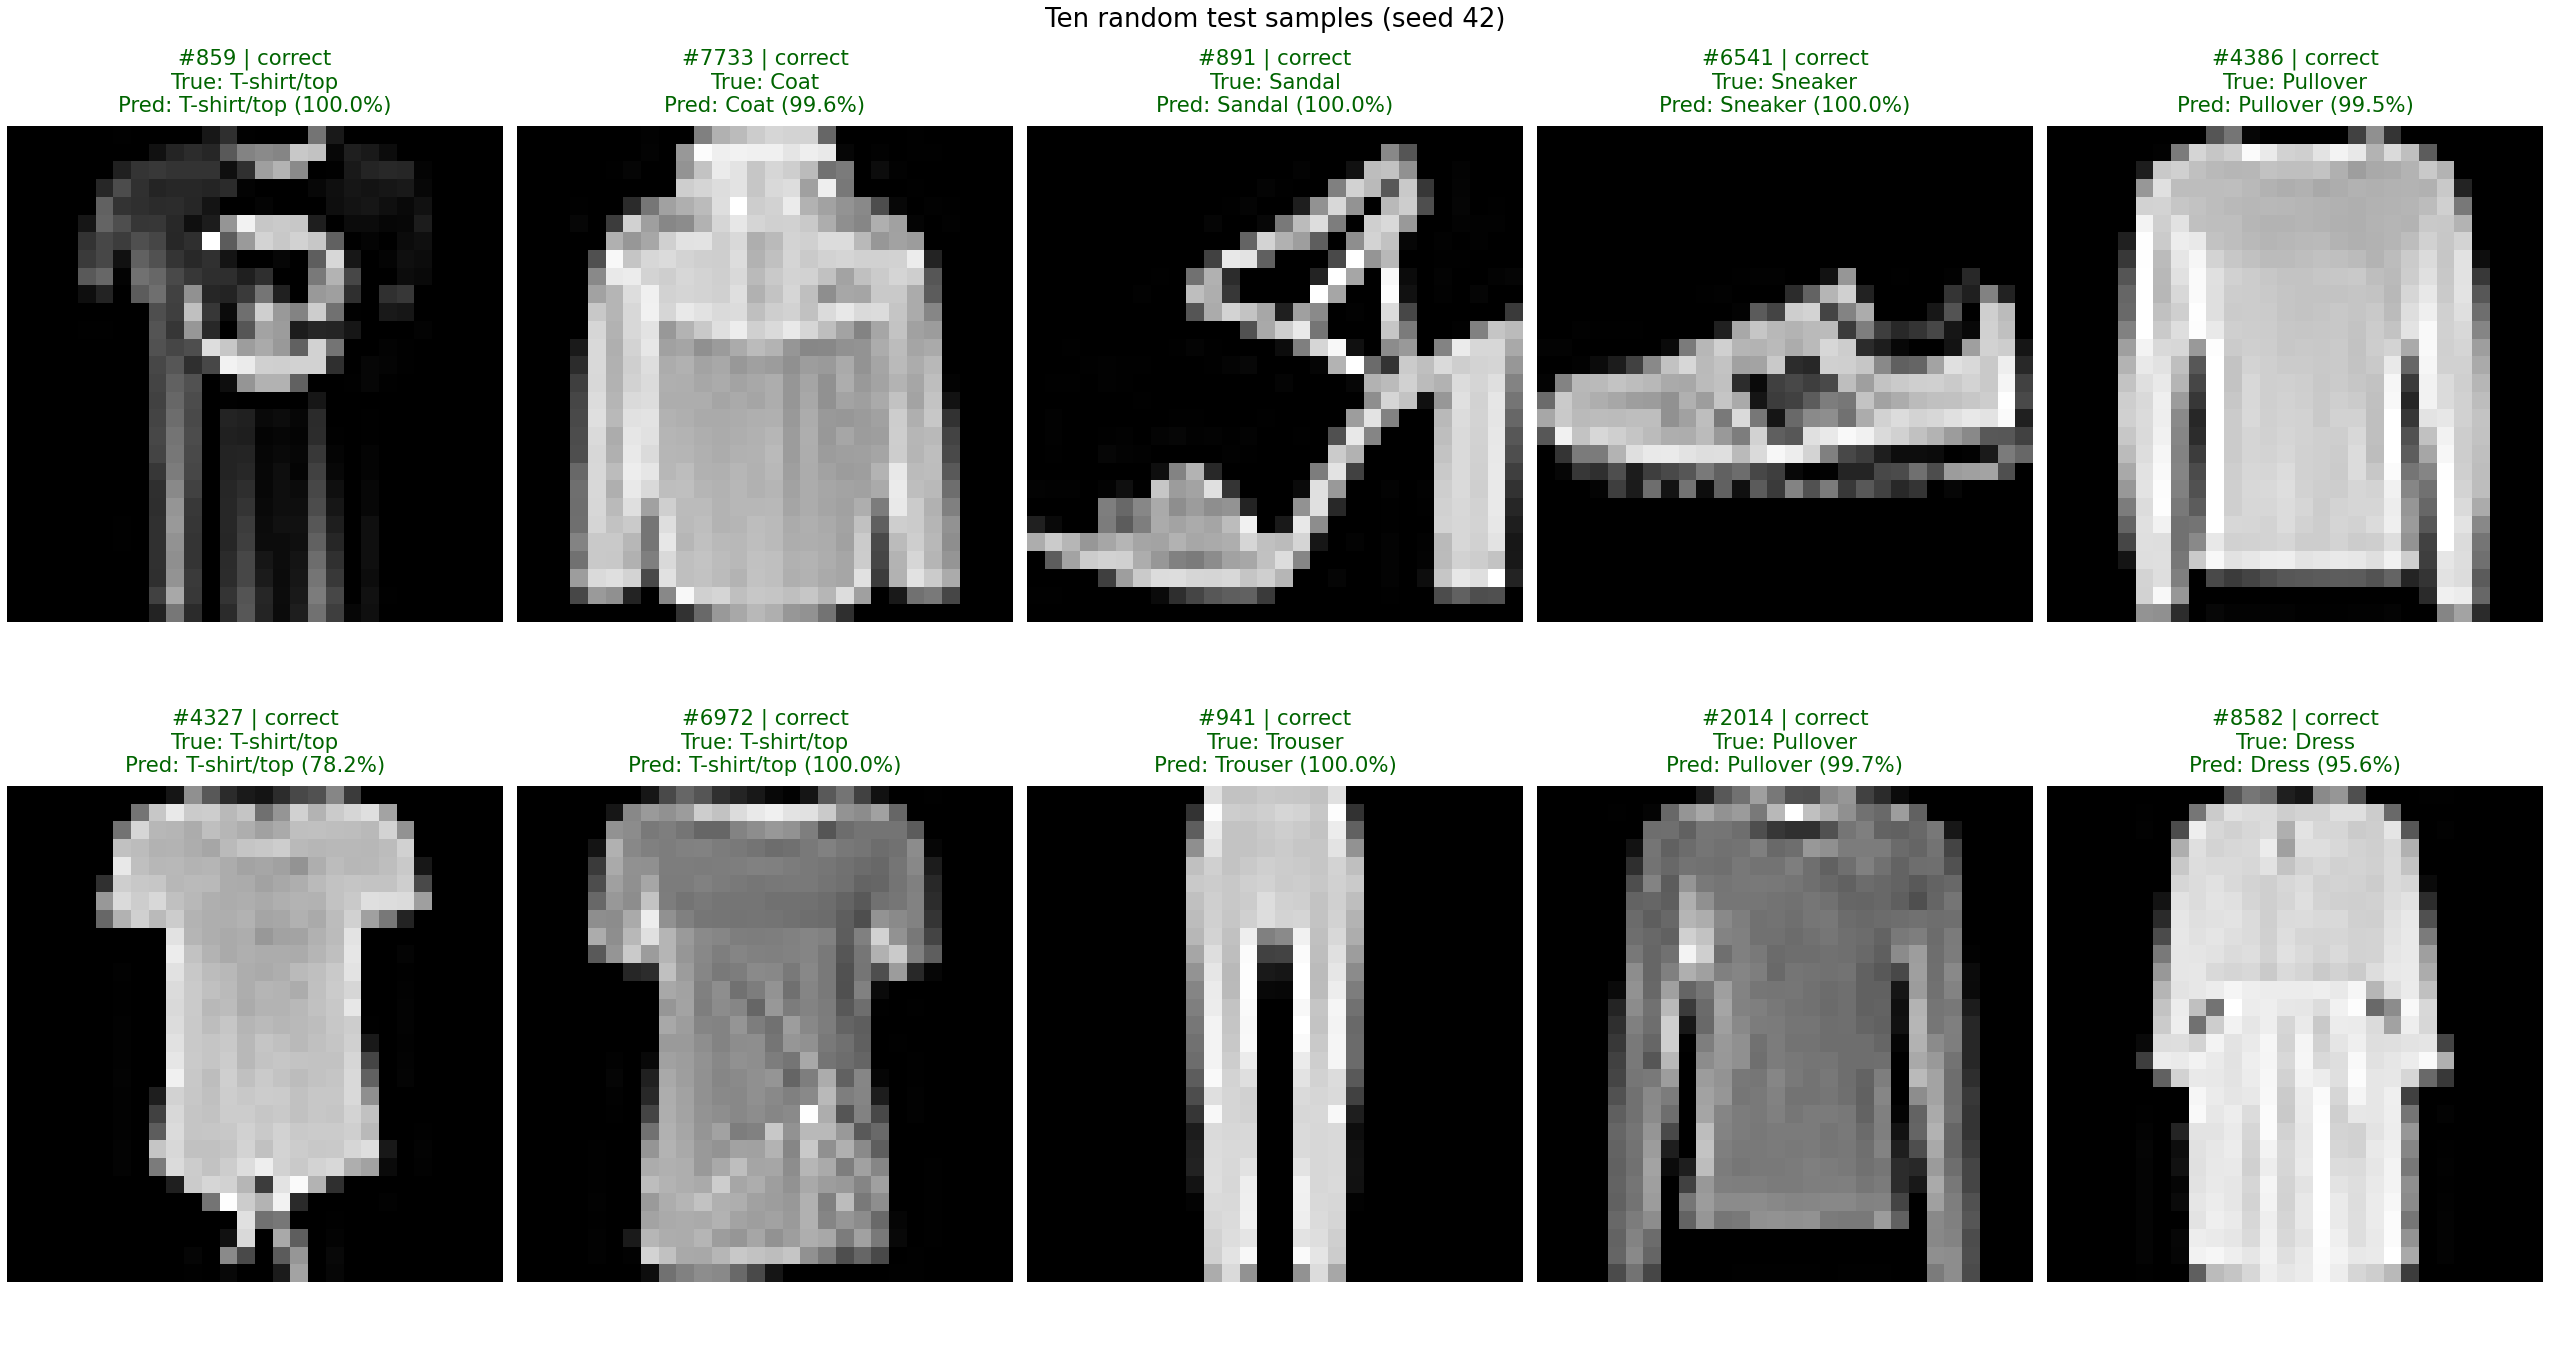

In [9]:
from IPython.display import Image, display
display(Image(filename=str(EVALUATION / 'random_samples.png')))

### 무작위 10장의 확신도

확신도 **90% 이상**을 높음으로 구분했다. 무작위 10장은 모두 맞혔다. 그중 9장은 고확신이었고, 저확신 정분류는 #4327 (78.19%)였다. 전체 10,000장의 분포를 함께 보면, 높은 확신도로도 틀린 경우가 있었다.

| 확신도 | 정분류 | 오분류 |
| --- | ---: | ---: |
| 높음 | 8,617 | 216 |
| 낮음 | 711 | 456 |

### 가장 애매한 샘플

가장 높은 소프트맥스 확률과 두 번째 확률의 차이가 작을수록 두 후보를 구분하기 어렵다고 보았다. 이 차이가 가장 작은 샘플을 전체 10,000장 중에서 골랐다. 동률이면 인덱스가 작은 샘플을 사용한다.

**#5820**의 실제 클래스는 Pullover이다. 모델은 Pullover(40.7890%)을 1순위로, T-shirt/top(40.7853%)을 2순위로 예측했다. 확률 차이는 **0.00370%p**로, 정분류였지만 두 후보의 확률이 거의 같았다.


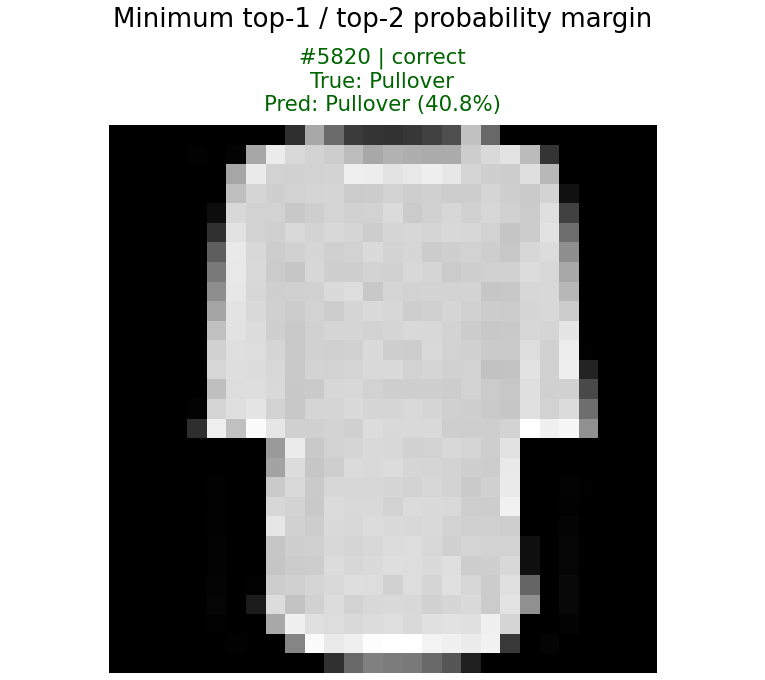

In [10]:
from IPython.display import Image, display
display(Image(filename=str(EVALUATION / 'most_ambiguous.png')))

## E01: baseline_cnn

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5jx5co3u

In [11]:
print((BASE / 'baseline_cnn' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 5jx5co3u
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/baseline_cnn/wandb/run-20261104_014529-5jx5co3u
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run cnn_bn1_drop1_aug0_norm1_seed42_2026-11-04_01-45-28
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5jx5co3u
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_del

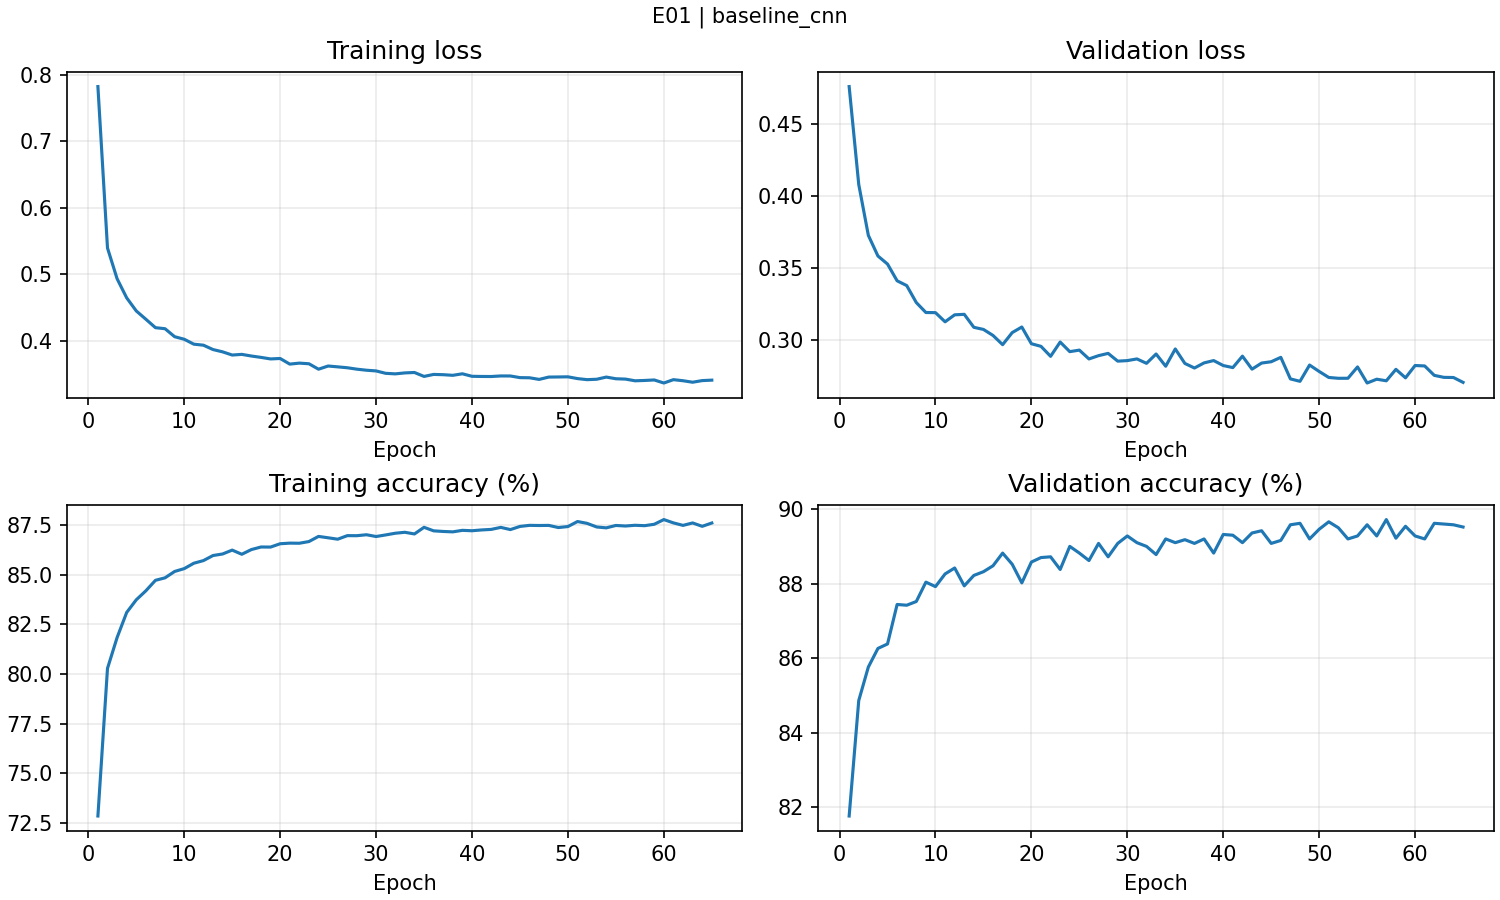

In [12]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'baseline_cnn.png')))

## E02: baseline_googlenet

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/d9yyna63

In [13]:
print((BASE / 'baseline_googlenet' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run d9yyna63
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/baseline_googlenet/wandb/run-20261104_015823-d9yyna63
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run googlenet_bn0_drop1_aug0_norm1_seed42_2026-11-04_01-58-22
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/d9yyna63
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, ea

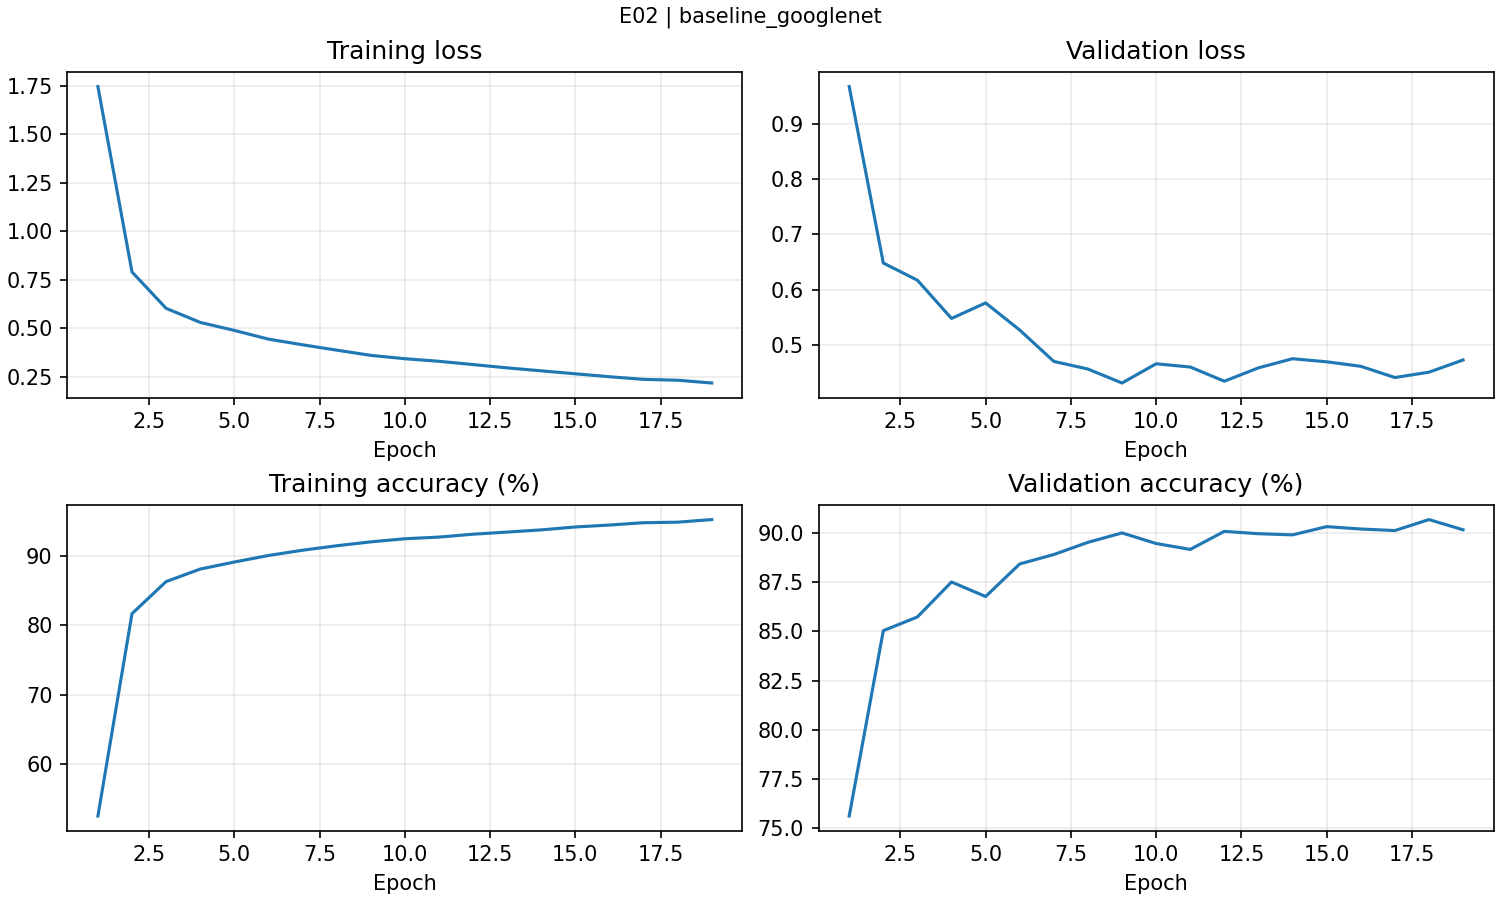

In [14]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'baseline_googlenet.png')))

## E03: baseline_nin

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qww2imrf

In [15]:
print((BASE / 'baseline_nin' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/baseline_nin/wandb/run-20261104_015050-qww2imrf
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_01-50-50
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qww2imrf
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimizer=3, weight_d

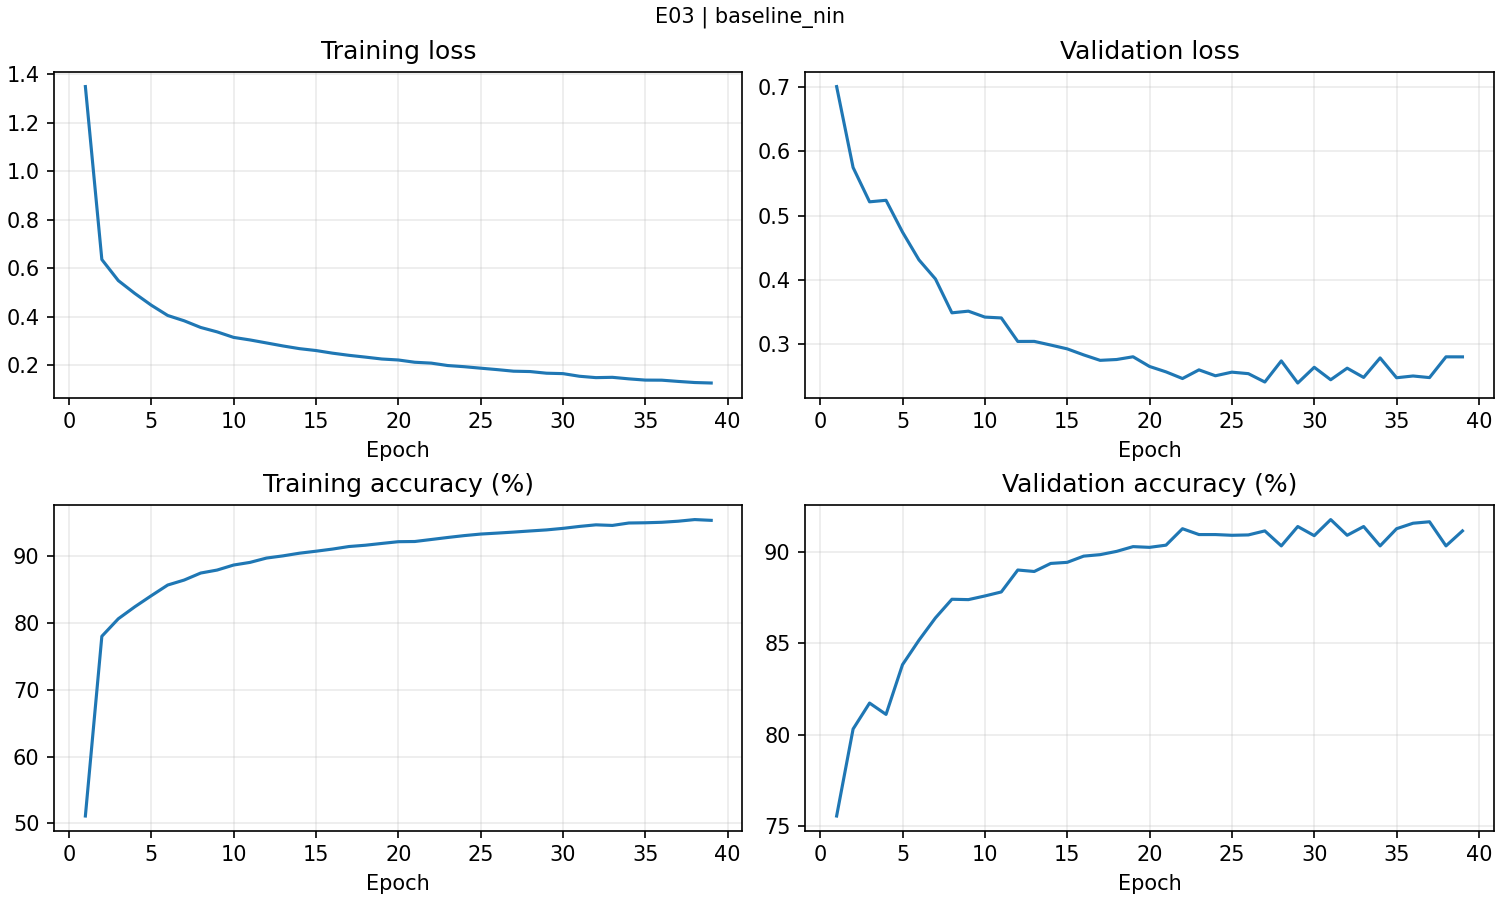

In [16]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'baseline_nin.png')))

## E04: baseline_resnet

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5nf4jdq4

In [17]:
print((BASE / 'baseline_resnet' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 5nf4jdq4
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/baseline_resnet/wandb/run-20261104_020249-5nf4jdq4
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run resnet_bn1_drop0_aug0_norm1_seed42_2026-11-04_02-02-49
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/5nf4jdq4
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_st

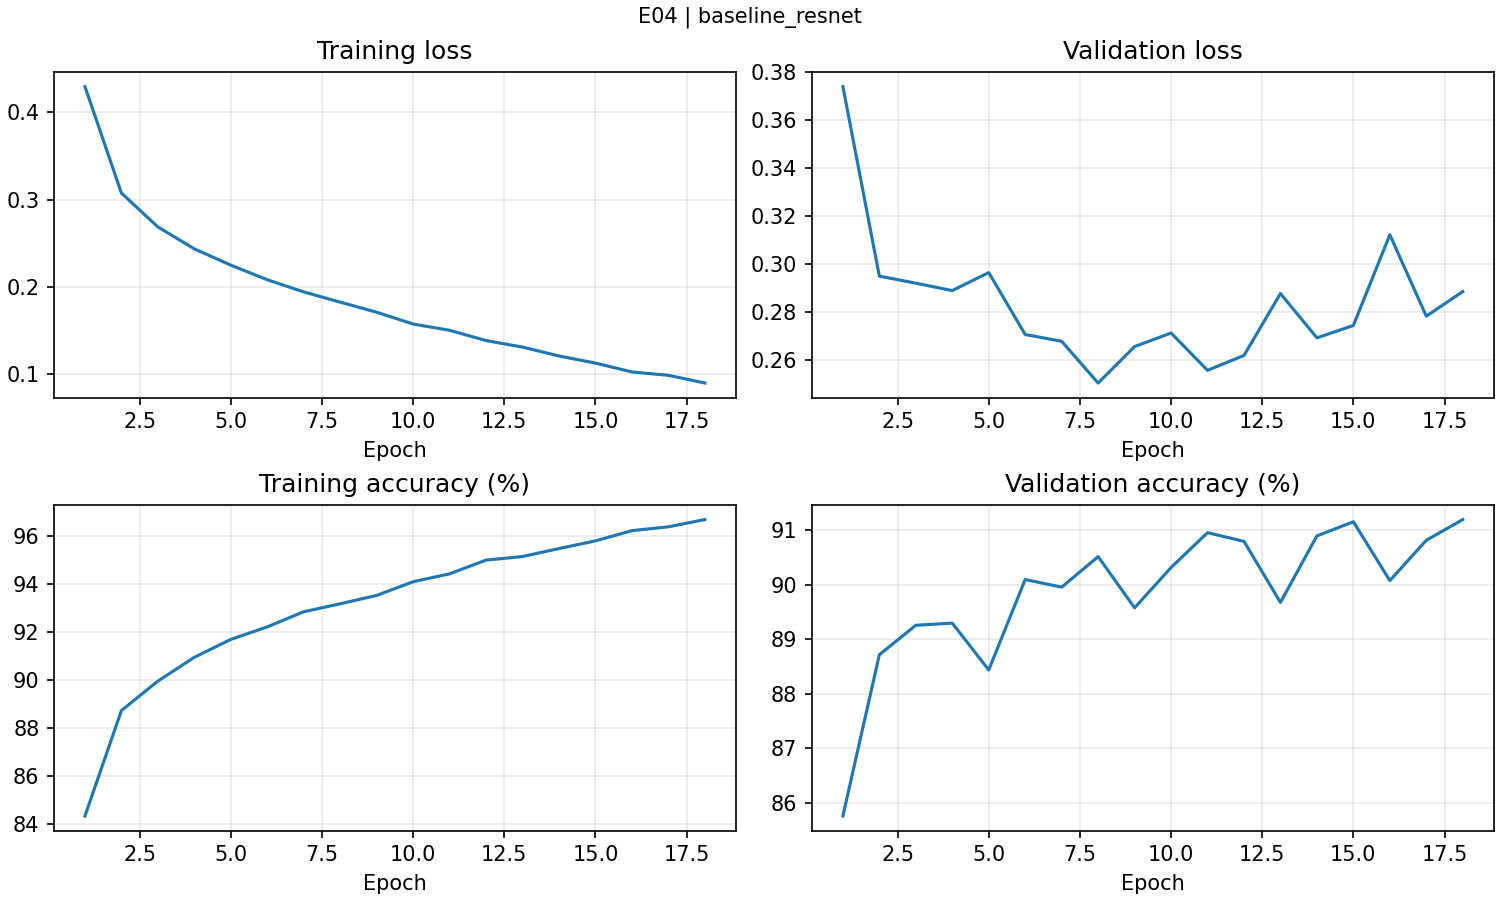

In [18]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'baseline_resnet.png')))

## E05: baseline_vgg

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qzq04czt

In [19]:
print((BASE / 'baseline_vgg' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/baseline_vgg/wandb/run-20261104_014621-qzq04czt
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_01-46-20
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/qzq04czt
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimizer=3, weight_d

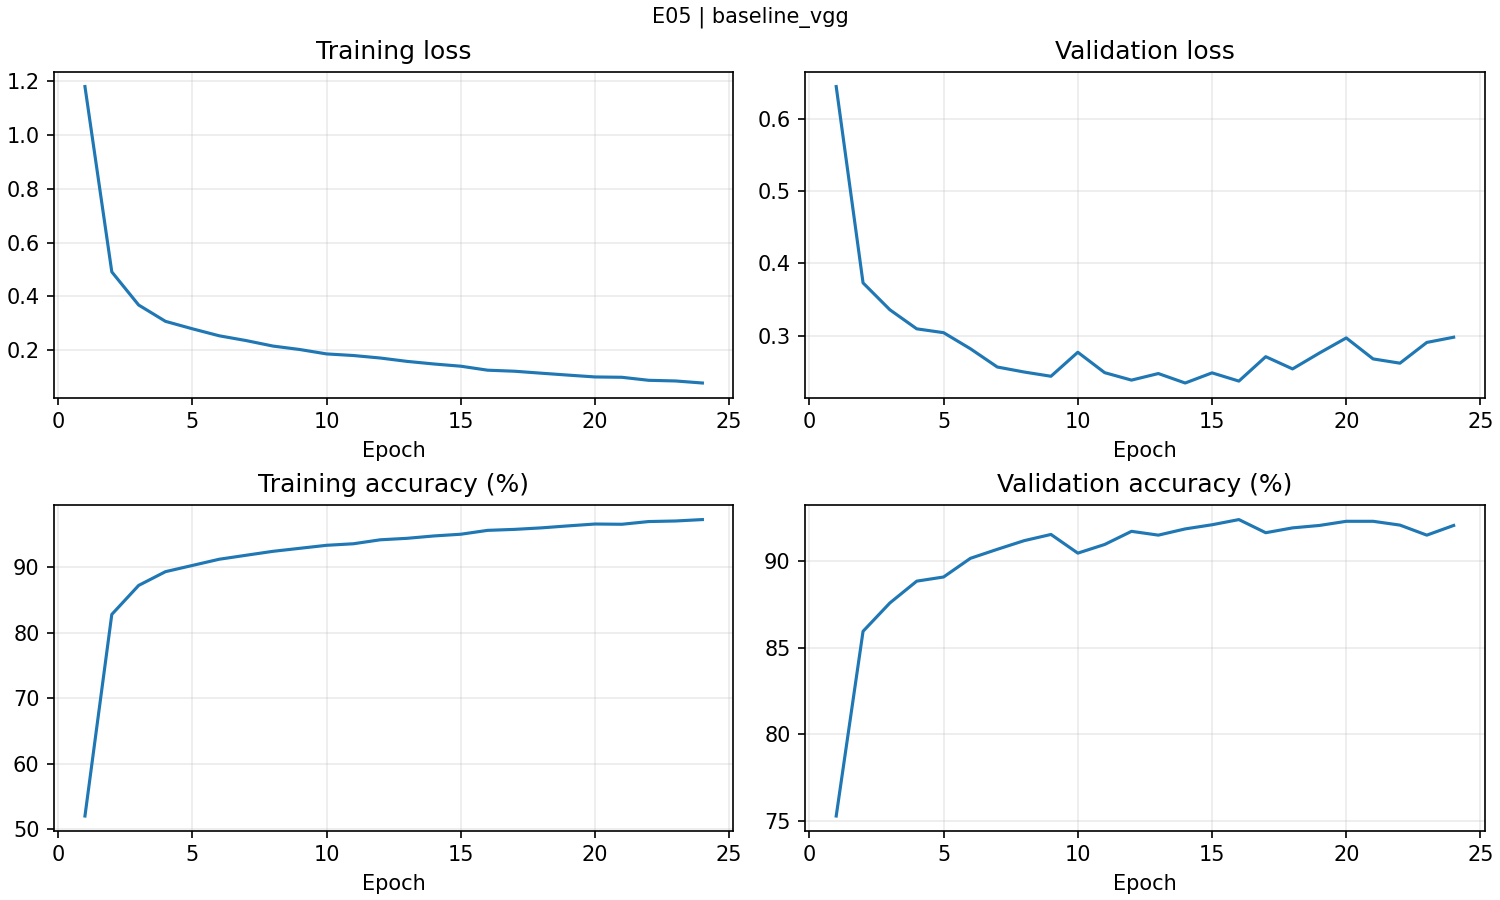

In [20]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'baseline_vgg.png')))

## E06: batch_lr_nin_94d71663ef65

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/wxovq9ef

In [21]:
print((BASE / 'batch_lr_nin_94d71663ef65' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run wxovq9ef
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_94d71663ef65/wandb/run-20261104_024900-wxovq9ef
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-49-00
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/wxovq9ef
/home/link/link_dl
Namespace(wandb=True, batch_size=64, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, e

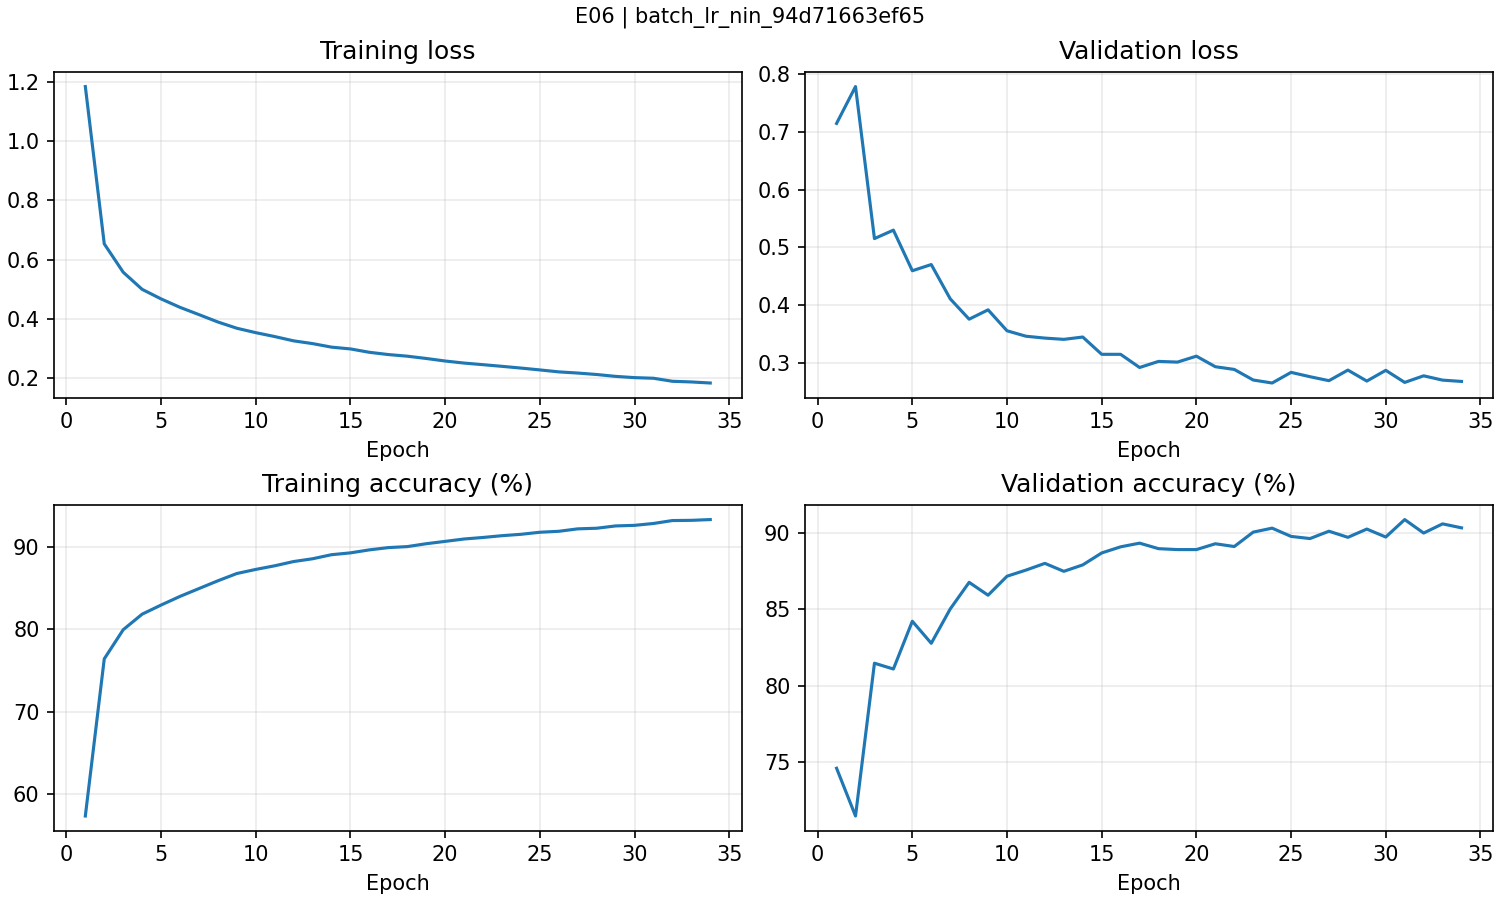

In [22]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_94d71663ef65.png')))

## E07: batch_lr_nin_fdd536e9adb7

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/lpjwncuy

In [23]:
print((BASE / 'batch_lr_nin_fdd536e9adb7' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_fdd536e9adb7/wandb/run-20261104_025610-lpjwncuy
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-56-10
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/lpjwncuy
/home/link/link_dl
Namespace(wandb=True, batch_size=64, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimizer

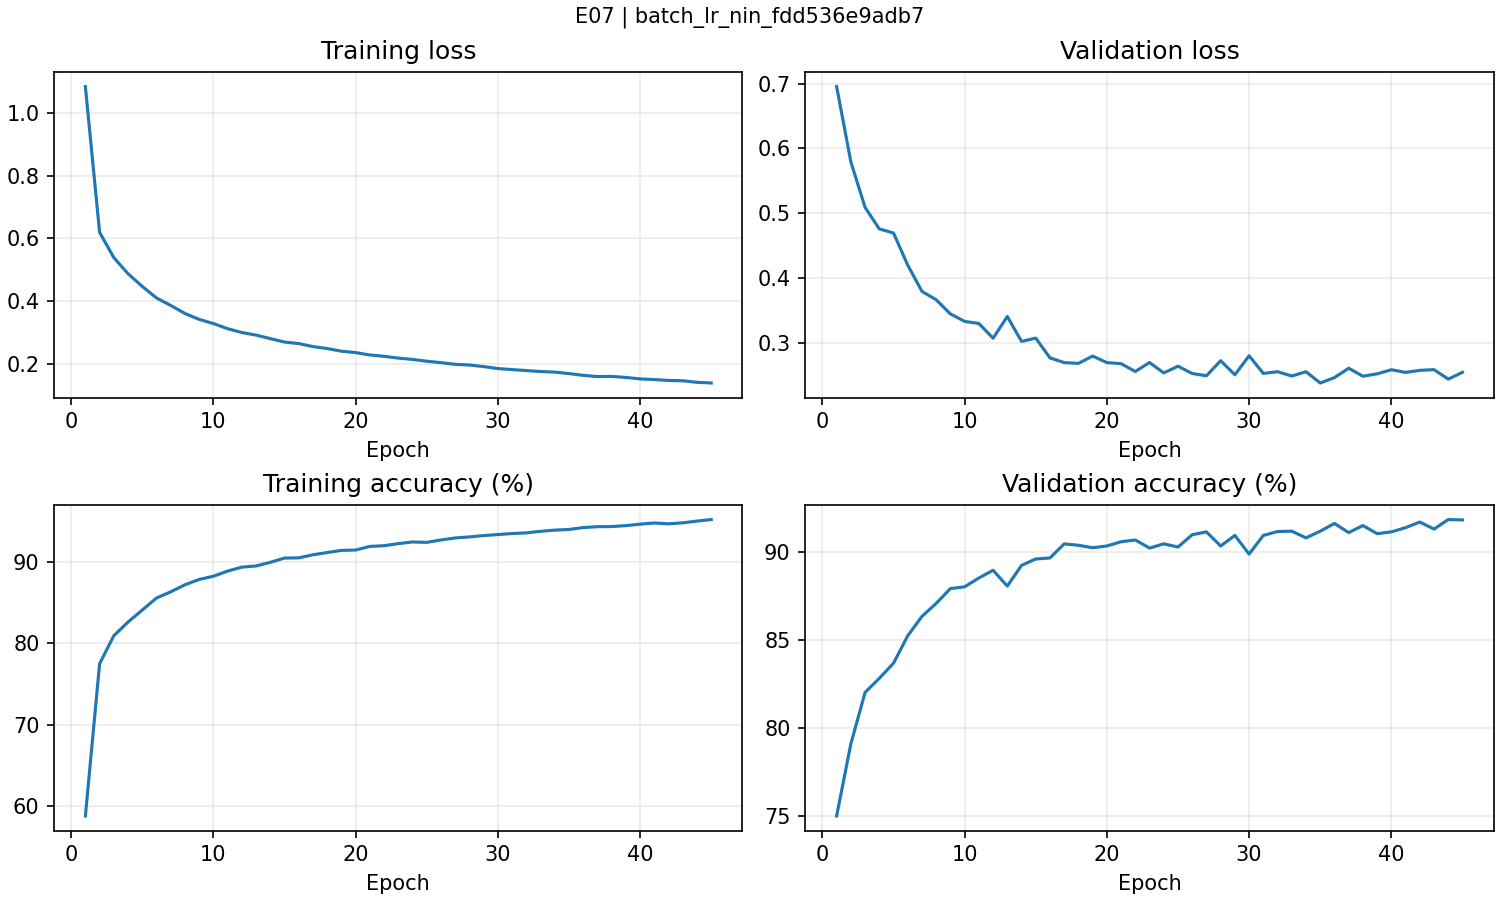

In [24]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_fdd536e9adb7.png')))

## E08: batch_lr_nin_14071cd582f5

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/y0xbtrlb

In [25]:
print((BASE / 'batch_lr_nin_14071cd582f5' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_14071cd582f5/wandb/run-20261104_030536-y0xbtrlb
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-05-35
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/y0xbtrlb
wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 10-10, summary, console lines

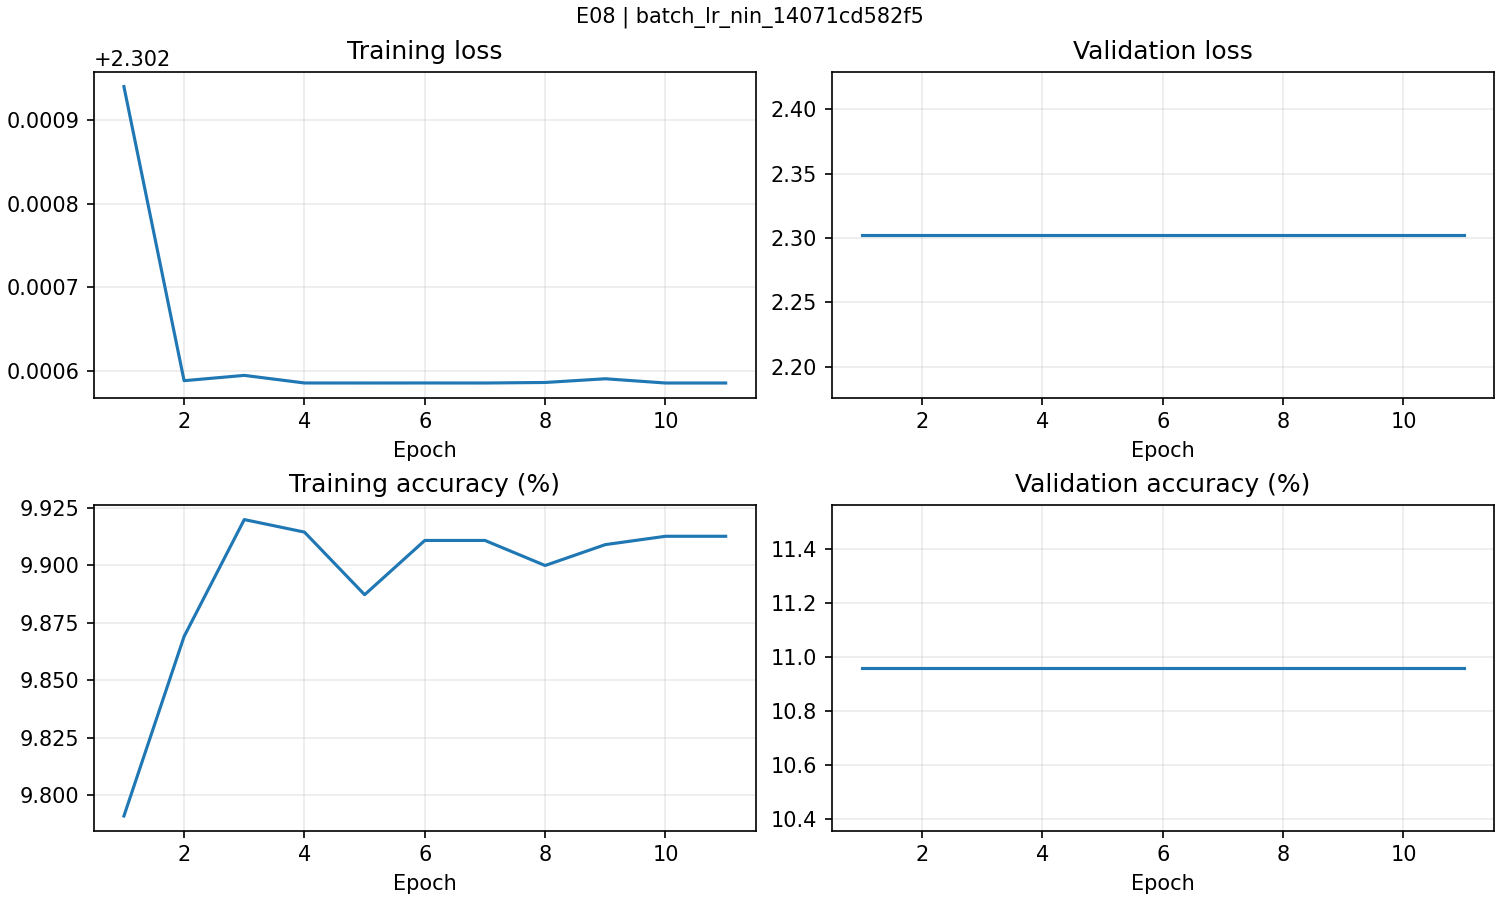

In [26]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_14071cd582f5.png')))

## E09: batch_lr_nin_6ac477517126

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/iujhdy45

In [27]:
print((BASE / 'batch_lr_nin_6ac477517126' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run iujhdy45
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_6ac477517126/wandb/run-20261104_030802-iujhdy45
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-08-01
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/iujhdy45
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, 

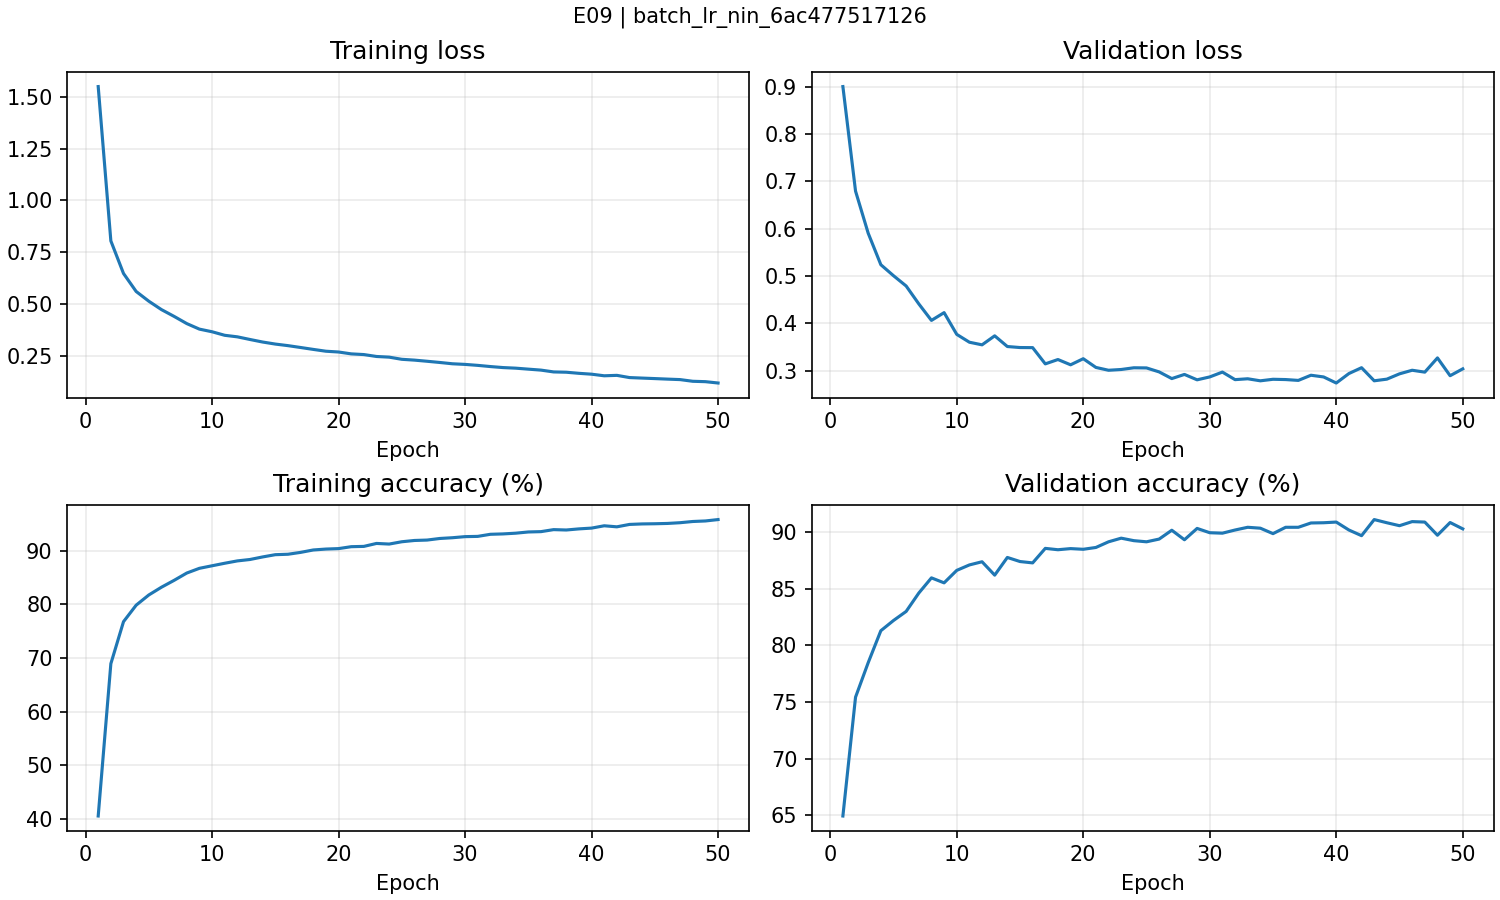

In [28]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_6ac477517126.png')))

## E10: batch_lr_nin_73258271aa85

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/33b6ldeg

In [29]:
print((BASE / 'batch_lr_nin_73258271aa85' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 33b6ldeg
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_73258271aa85/wandb/run-20261104_031732-33b6ldeg
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-17-32
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/33b6ldeg
wandb: updating run metadata
wandb: uploading history steps 10-10, summary, console lines 82-83
wandb: 
wandb: Run history:
wandb:         

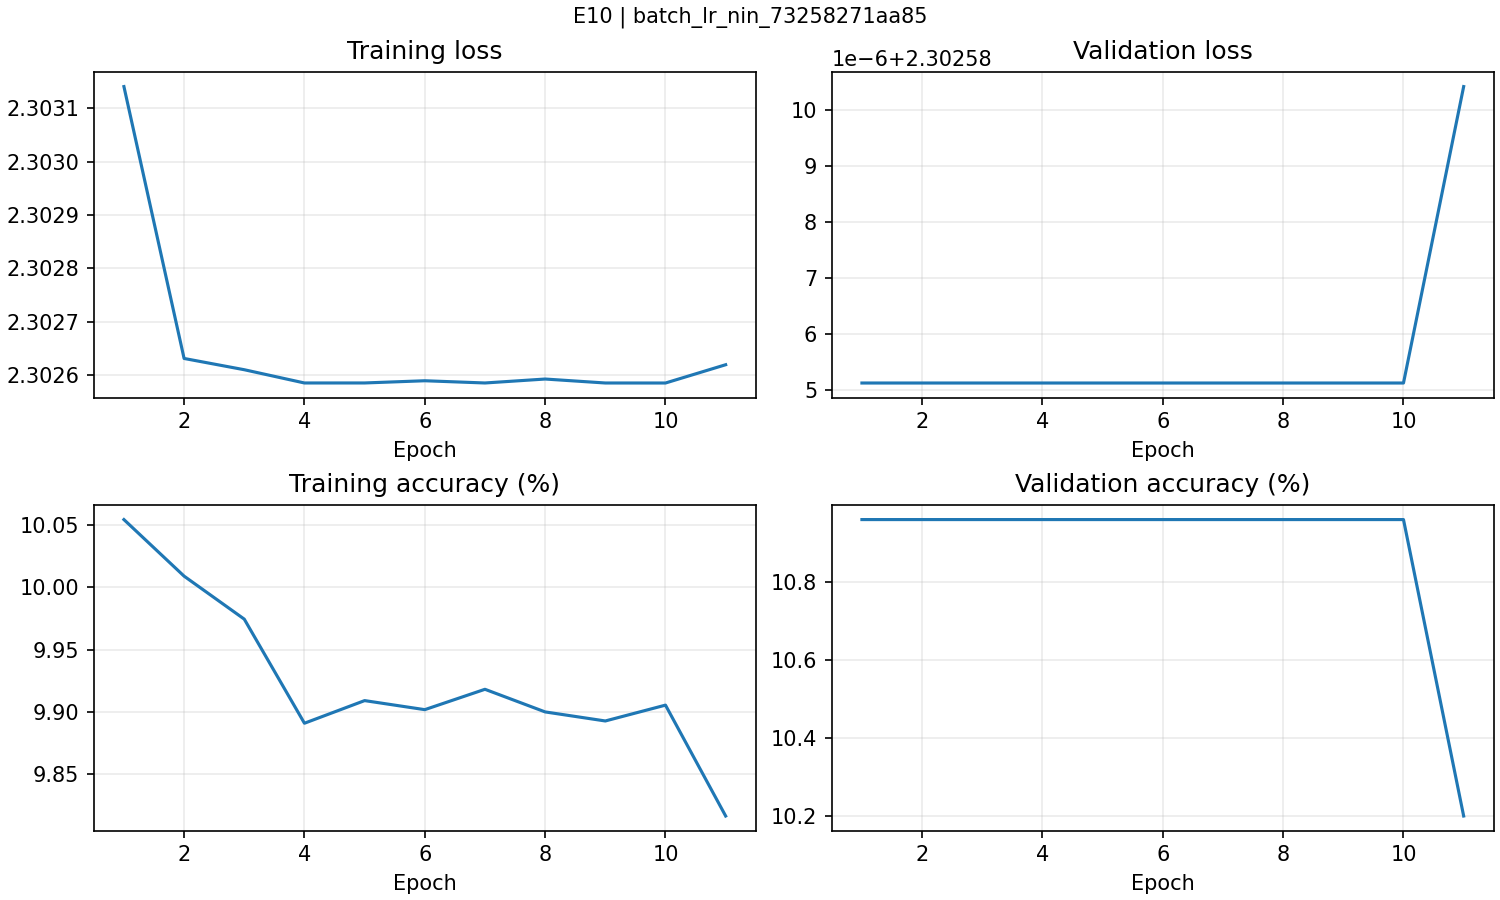

In [30]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_73258271aa85.png')))

## E11: batch_lr_nin_b798689fb349

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/9pt4fk5h

In [31]:
print((BASE / 'batch_lr_nin_b798689fb349' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_b798689fb349/wandb/run-20261104_031948-9pt4fk5h
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-19-47
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/9pt4fk5h
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimiz

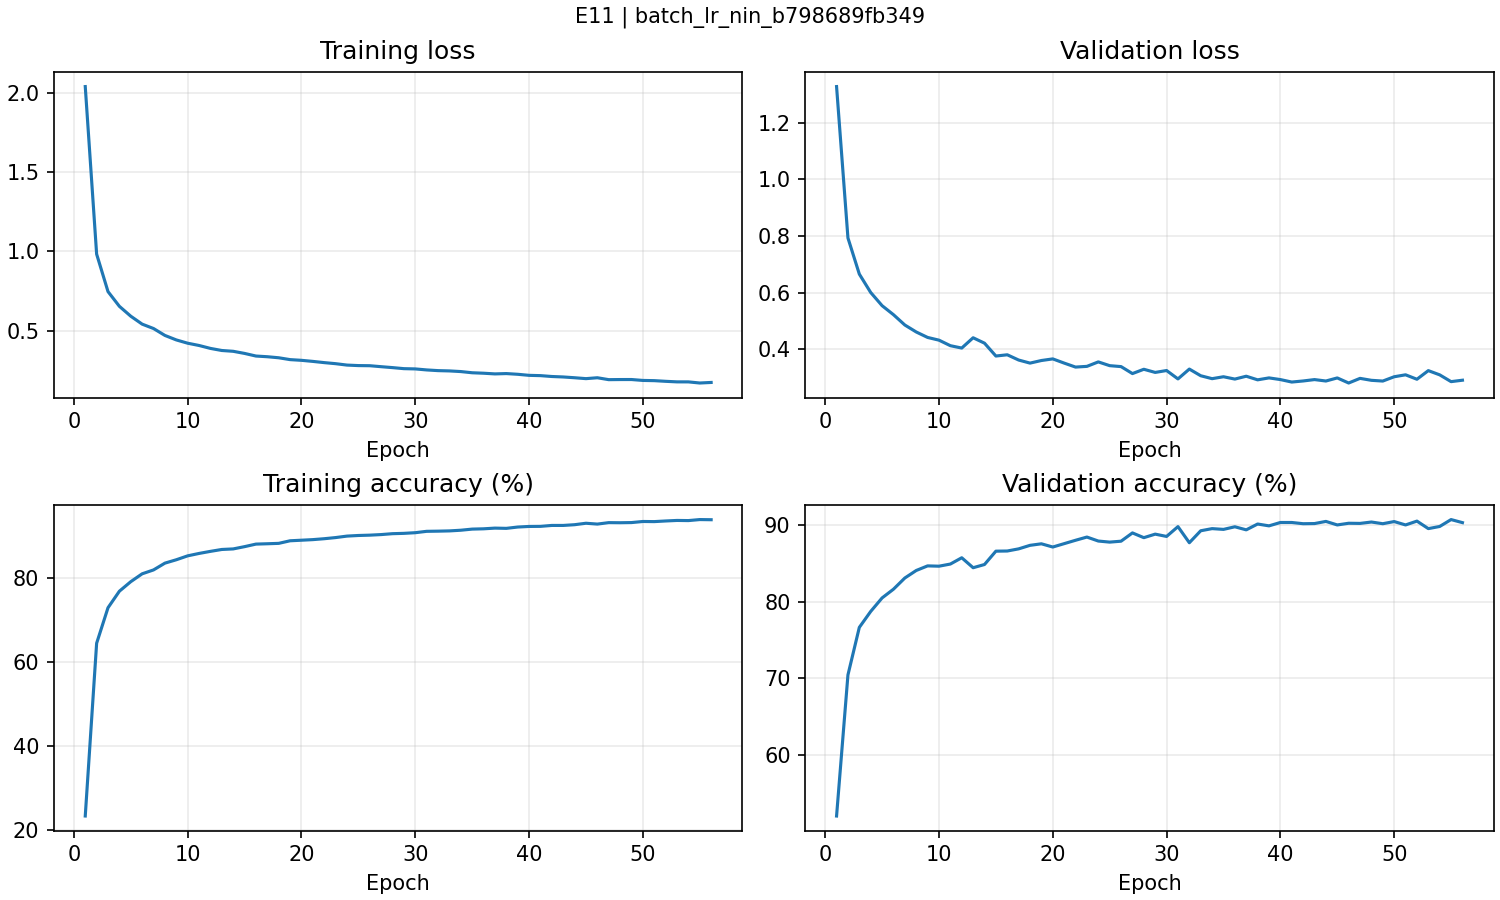

In [32]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_b798689fb349.png')))

## E12: batch_lr_nin_aa2f907e95e8

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/oezfpb1i

In [33]:
print((BASE / 'batch_lr_nin_aa2f907e95e8' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_aa2f907e95e8/wandb/run-20261104_032944-oezfpb1i
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-29-44
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/oezfpb1i
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimize

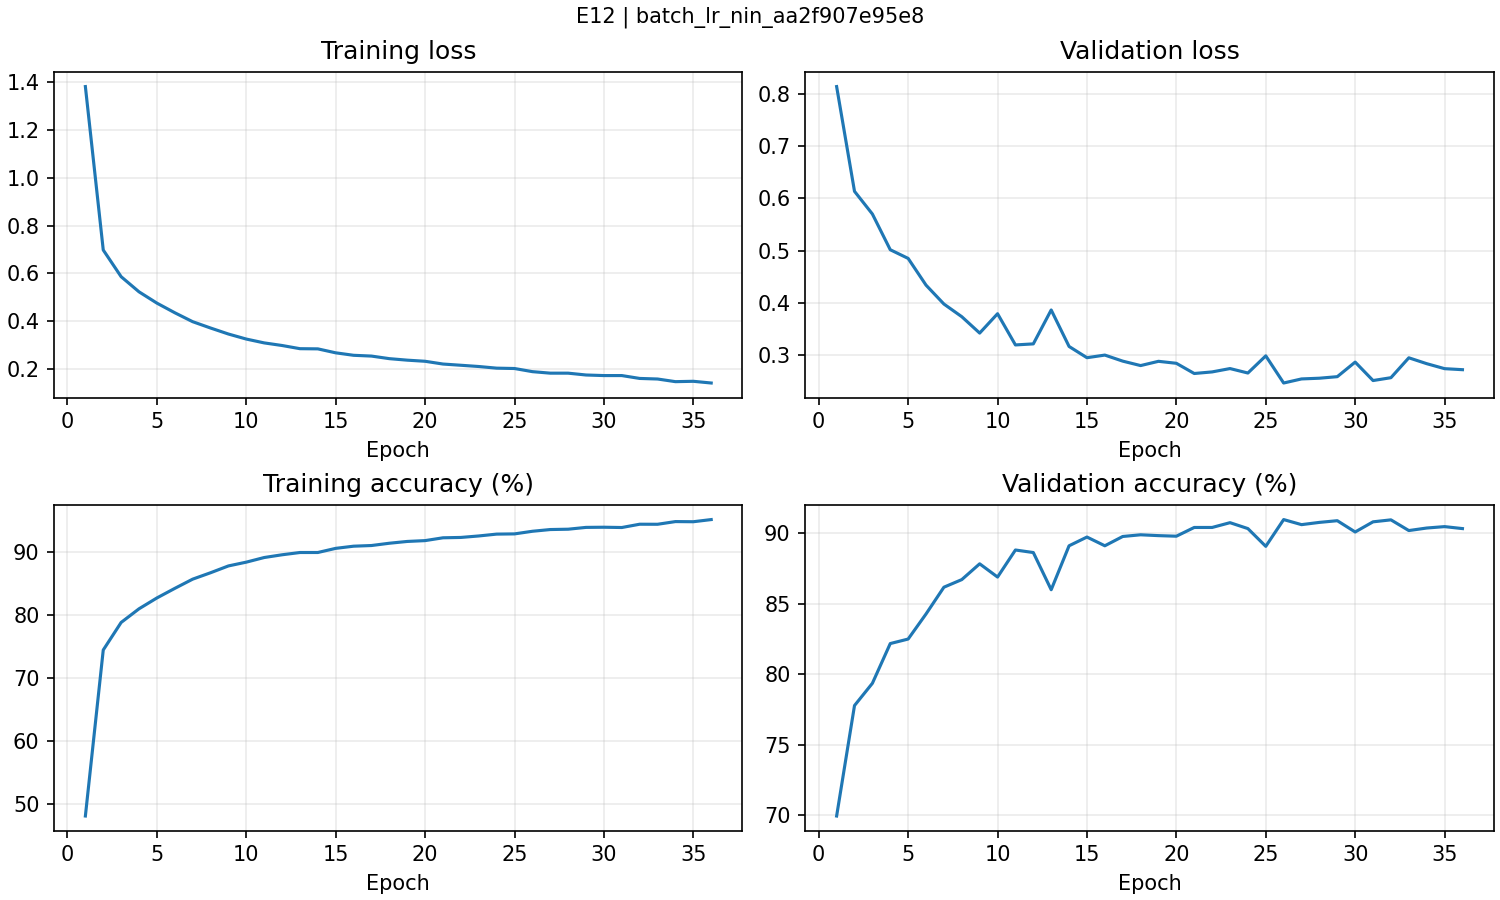

In [34]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_aa2f907e95e8.png')))

## E13: batch_lr_nin_149835a04539

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bto4prcc

In [35]:
print((BASE / 'batch_lr_nin_149835a04539' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run bto4prcc
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_nin_149835a04539/wandb/run-20261104_033612-bto4prcc
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-36-11
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bto4prcc
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, e

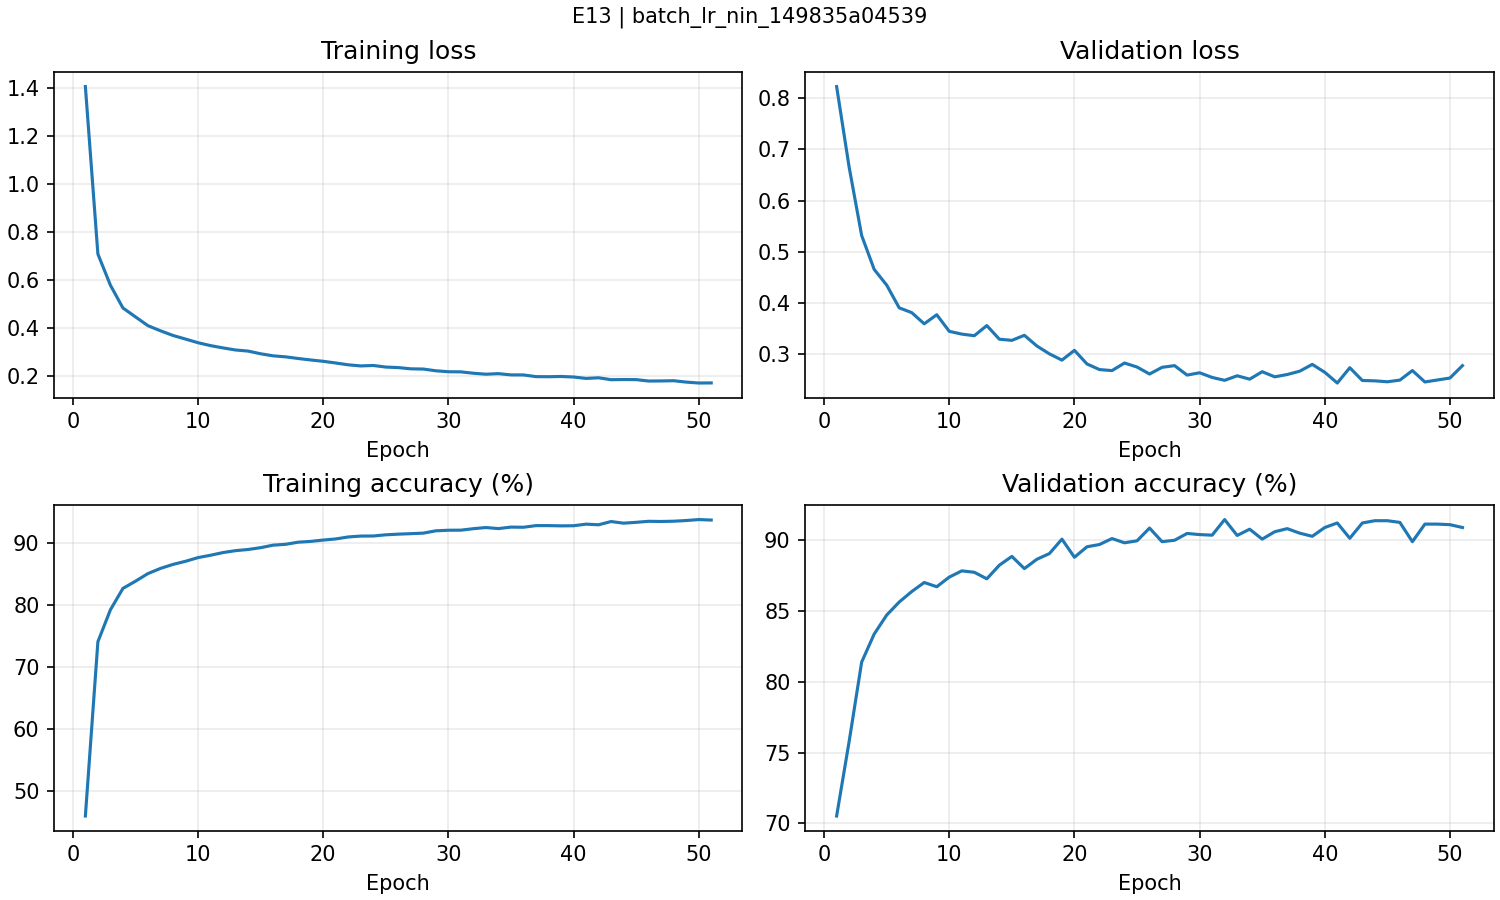

In [36]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_nin_149835a04539.png')))

## E14: batch_lr_vgg_b390392f65de

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/soutc8bx

In [37]:
print((BASE / 'batch_lr_vgg_b390392f65de' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run soutc8bx
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_b390392f65de/wandb/run-20261104_020447-soutc8bx
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-04-47
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/soutc8bx
wandb: updating run metadata
wandb: uploading history steps 17-17, summary, console lines 89-90
wandb: 
wandb: Run history:
wandb:         

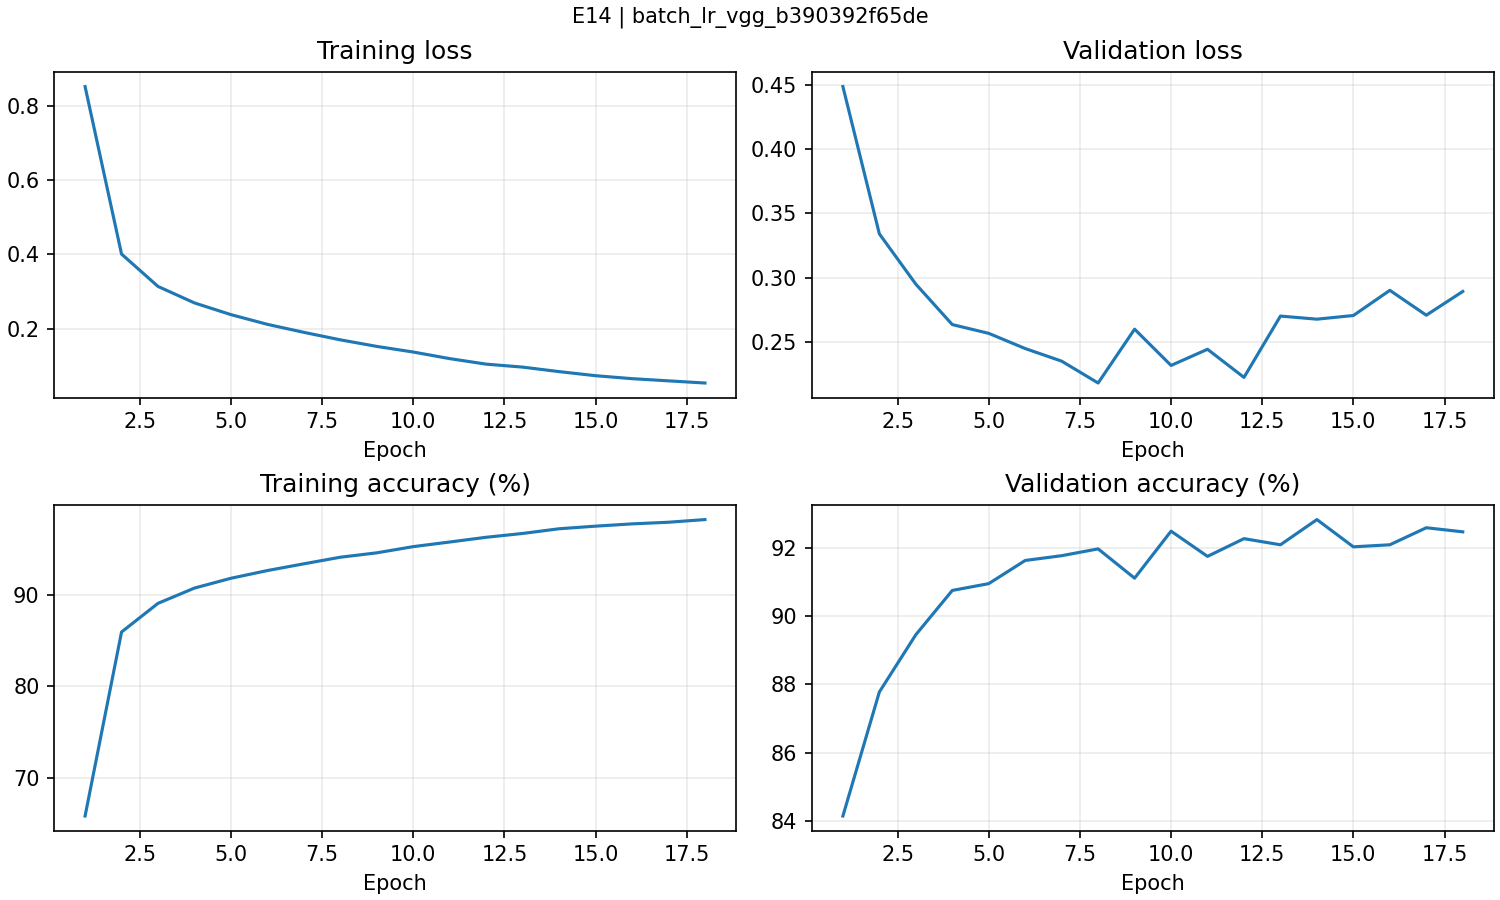

In [38]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_b390392f65de.png')))

## E15: batch_lr_vgg_86e4d56f3a8b

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/izflbaak

In [39]:
print((BASE / 'batch_lr_vgg_86e4d56f3a8b' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_86e4d56f3a8b/wandb/run-20261104_020853-izflbaak
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-08-52
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/izflbaak
/home/link/link_dl
Namespace(wandb=True, batch_size=64, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimizer

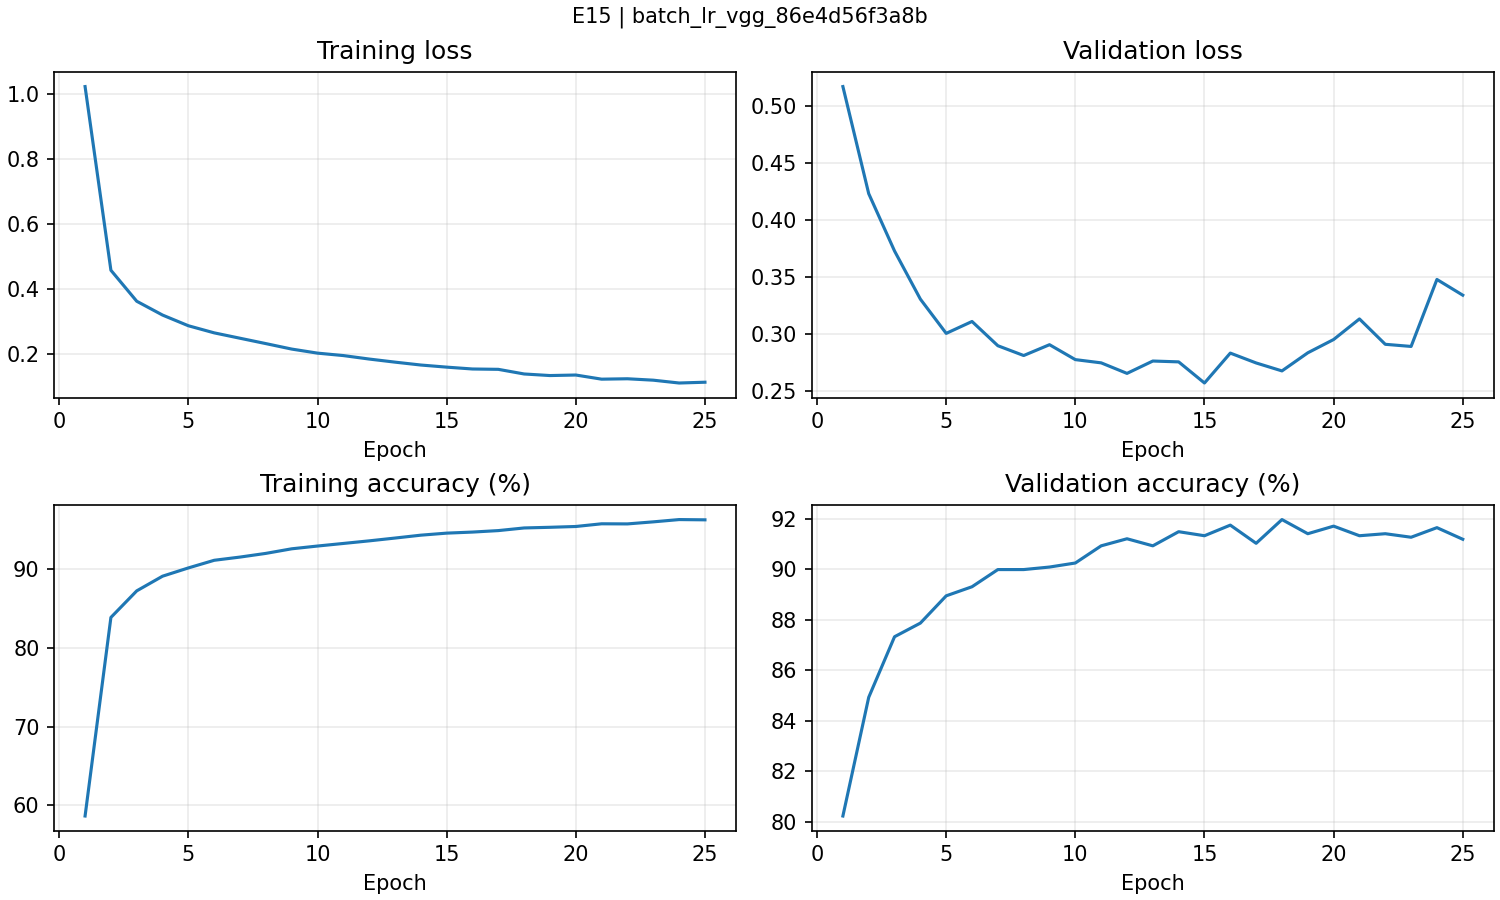

In [40]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_86e4d56f3a8b.png')))

## E16: batch_lr_vgg_9ddef204ec11

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/9l8zcd4b

In [41]:
print((BASE / 'batch_lr_vgg_9ddef204ec11' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_9ddef204ec11/wandb/run-20261104_021430-9l8zcd4b
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-14-30
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/9l8zcd4b
wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 17-17, summary, console lines

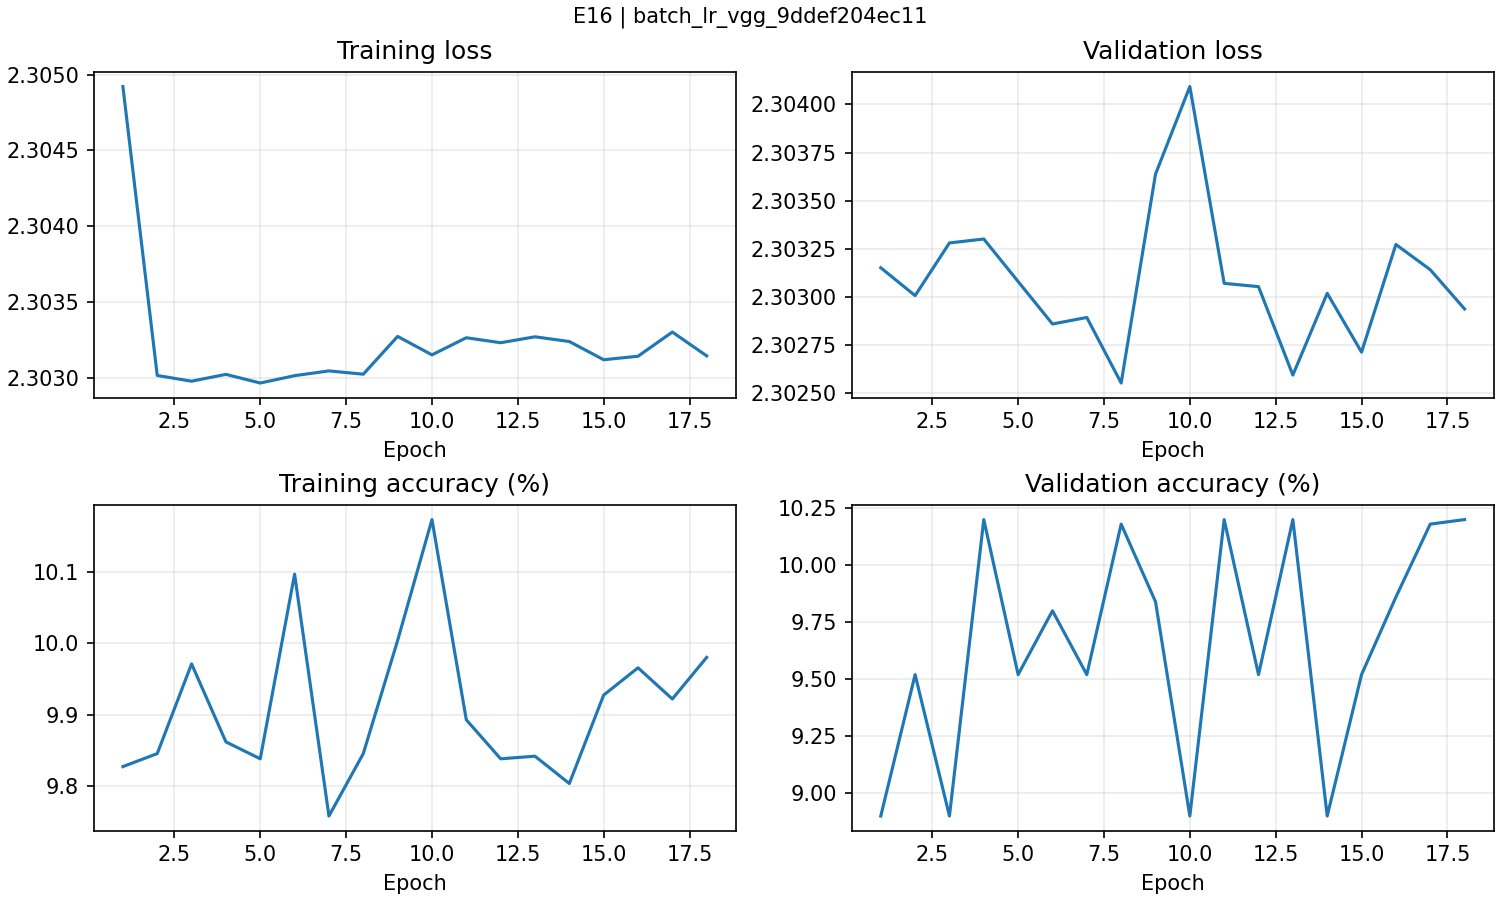

In [42]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_9ddef204ec11.png')))

## E17: batch_lr_vgg_04fb277c0265

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/tqs5157y

In [43]:
print((BASE / 'batch_lr_vgg_04fb277c0265' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run tqs5157y
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_04fb277c0265/wandb/run-20261104_021835-tqs5157y
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-18-35
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/tqs5157y
wandb: updating run metadata
wandb: uploading history steps 17-17, summary, console lines 89-90
wandb: 
wandb: Run history:
wandb:         

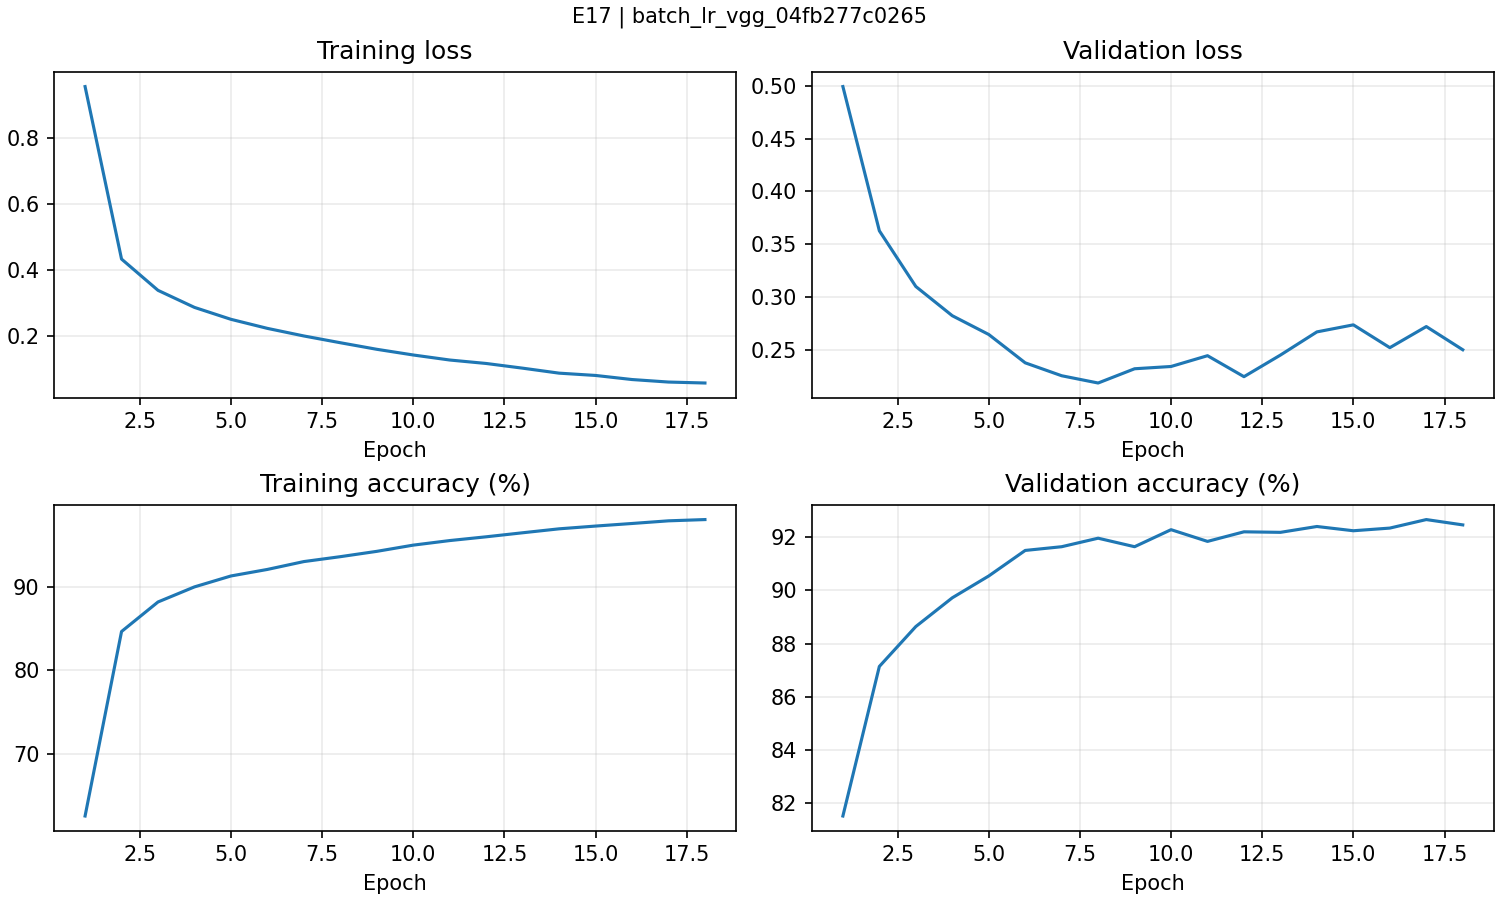

In [44]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_04fb277c0265.png')))

## E18: batch_lr_vgg_a0cb4141da81

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/eph8hgal

In [45]:
print((BASE / 'batch_lr_vgg_a0cb4141da81' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_a0cb4141da81/wandb/run-20261104_022153-eph8hgal
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-21-53
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/eph8hgal
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimize

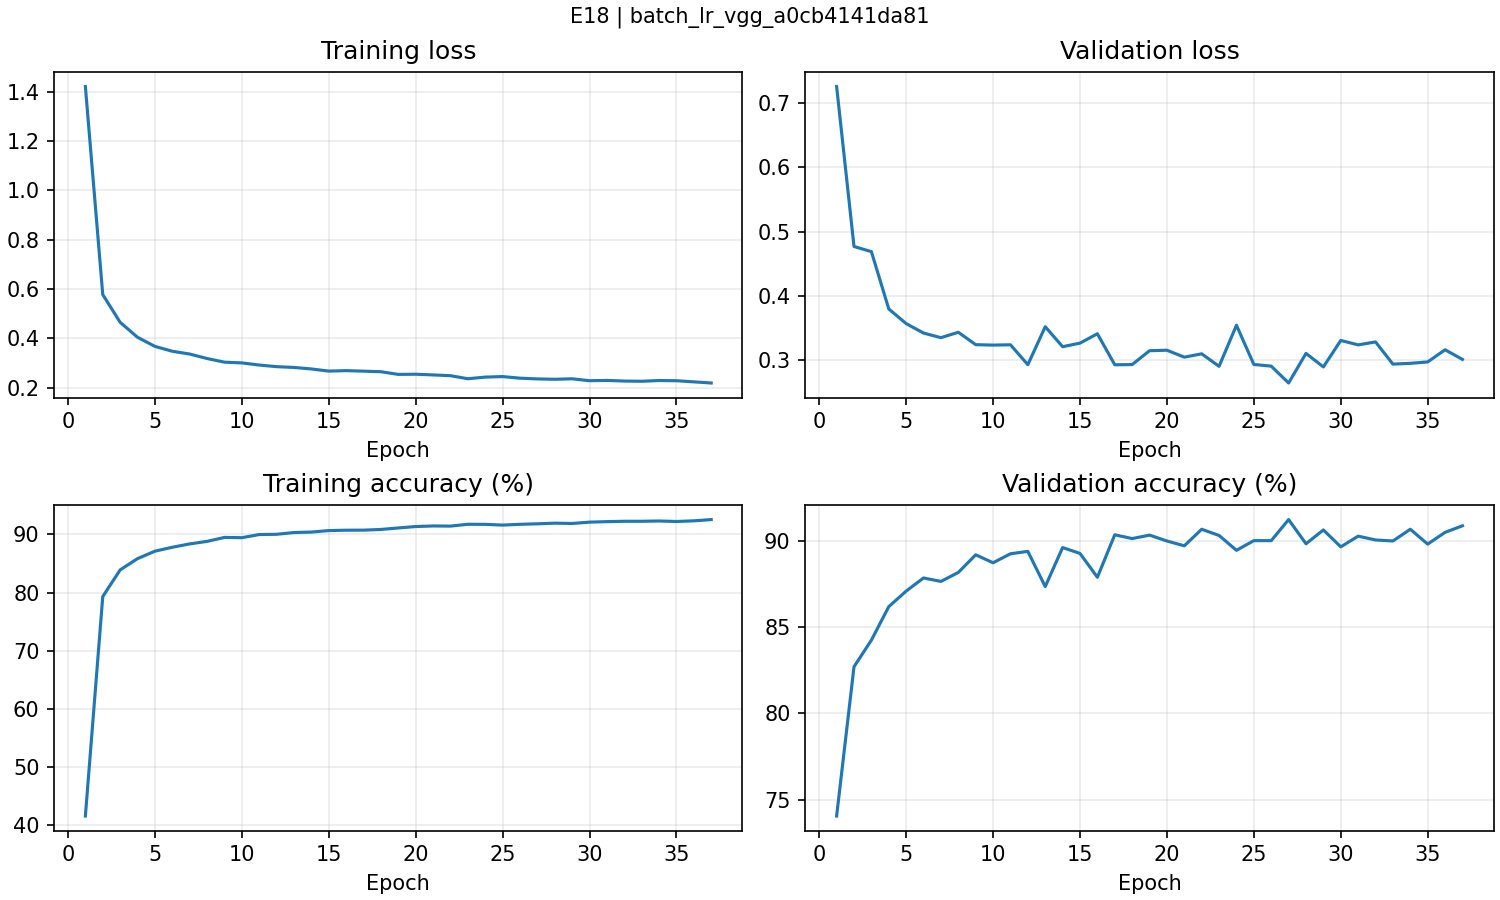

In [46]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_a0cb4141da81.png')))

## E19: batch_lr_vgg_c6f7f929b6c4

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/l1wds0qm

In [47]:
print((BASE / 'batch_lr_vgg_c6f7f929b6c4' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_c6f7f929b6c4/wandb/run-20261104_022830-l1wds0qm
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-28-30
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/l1wds0qm
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimiz

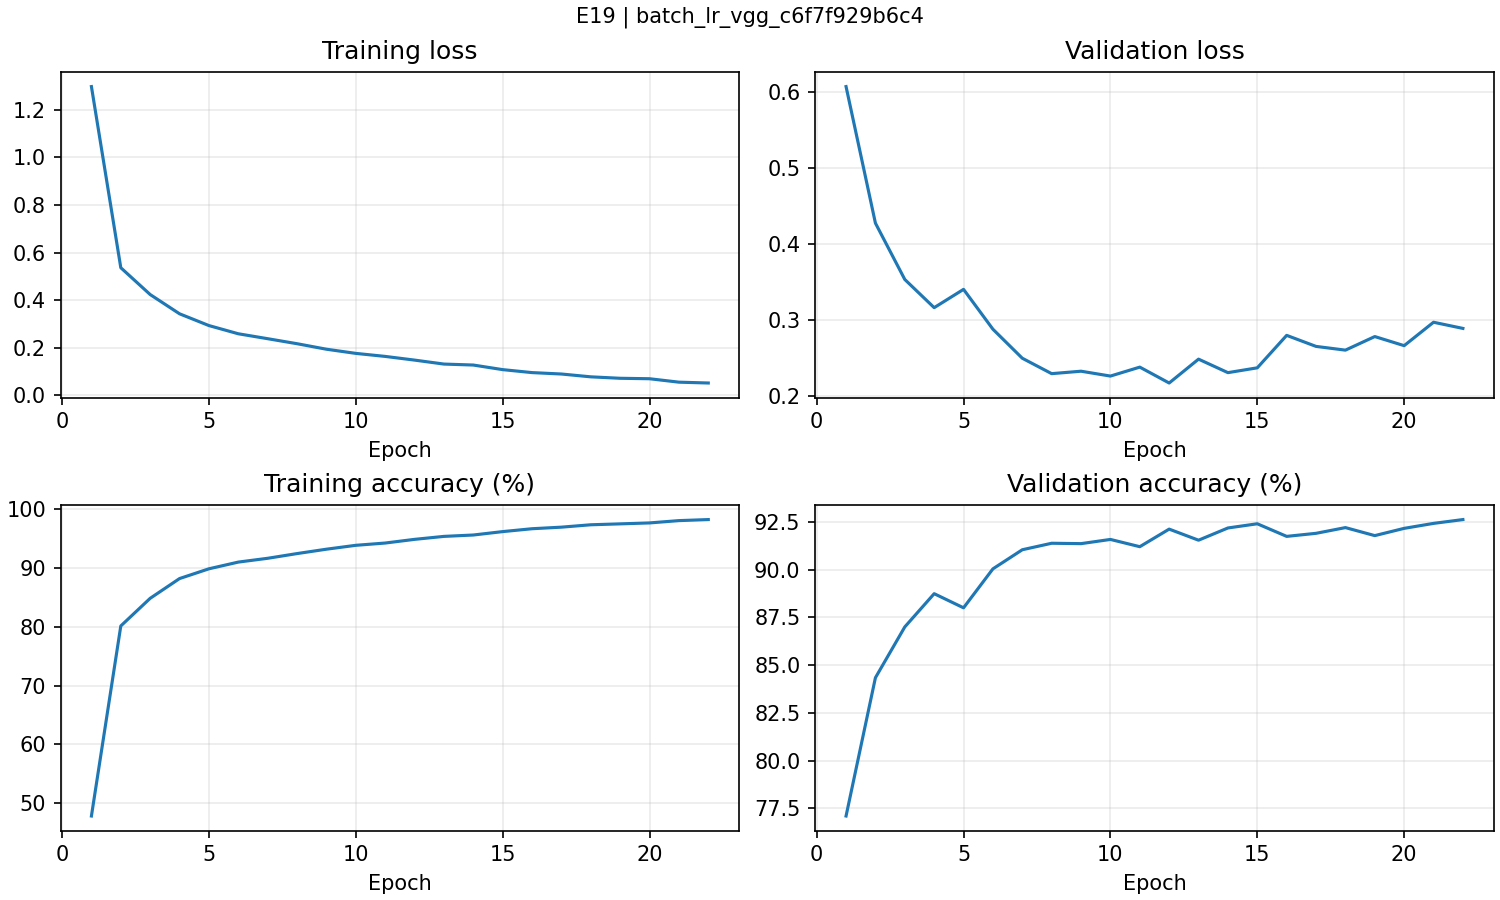

In [48]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_c6f7f929b6c4.png')))

## E20: batch_lr_vgg_f73ddd0ffb79

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/soo8ky91

In [49]:
print((BASE / 'batch_lr_vgg_f73ddd0ffb79' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run soo8ky91
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_f73ddd0ffb79/wandb/run-20261104_023156-soo8ky91
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-31-56
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/soo8ky91
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, e

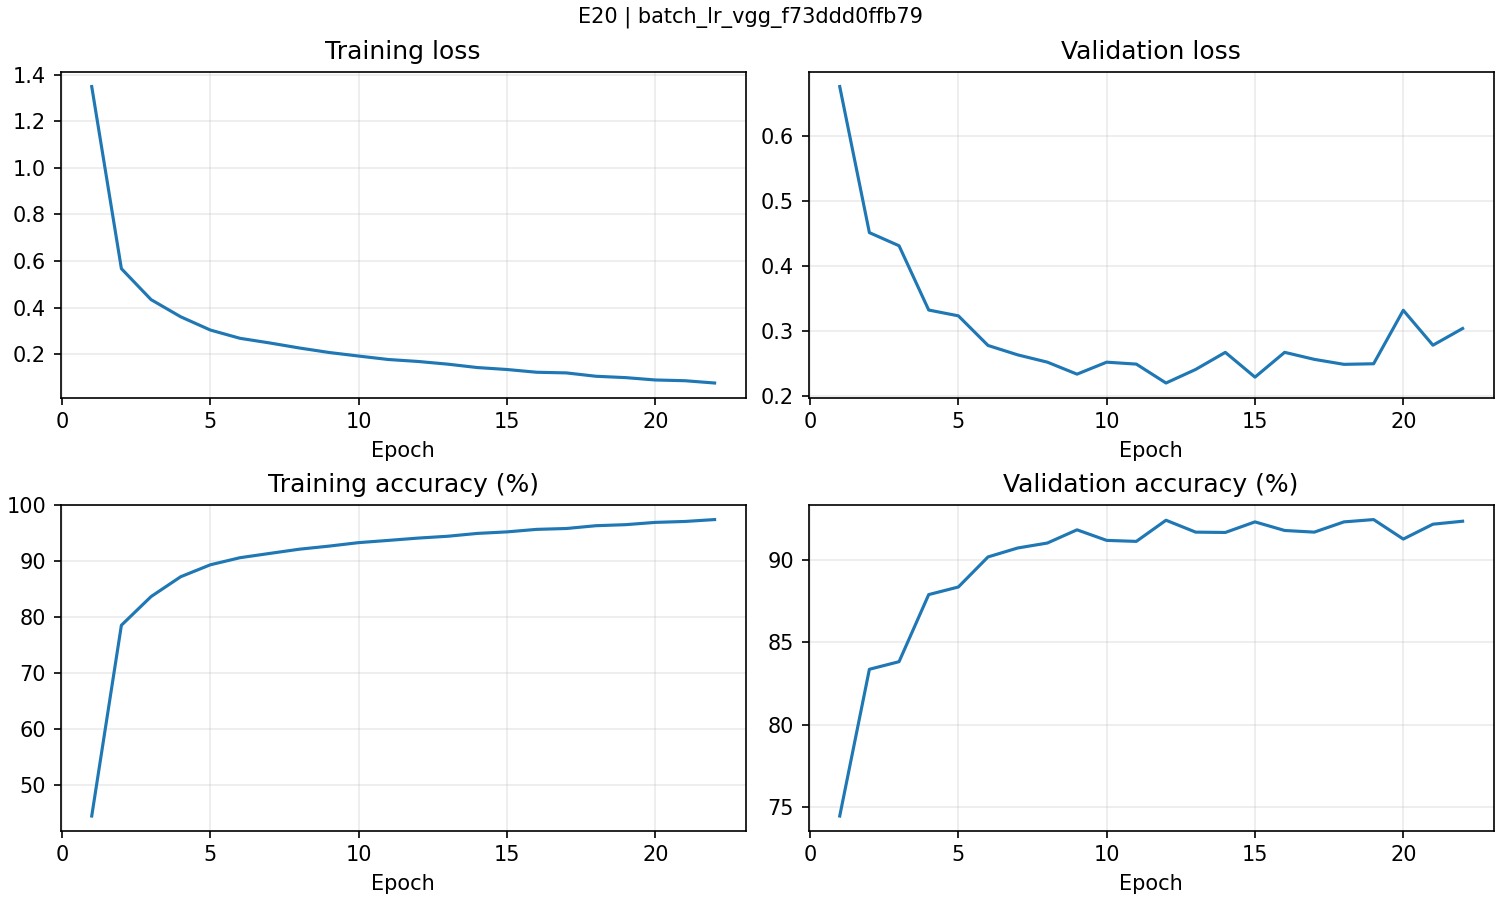

In [50]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_f73ddd0ffb79.png')))

## E21: batch_lr_vgg_0fe02a9374e8

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/6q1qpj0p

In [51]:
print((BASE / 'batch_lr_vgg_0fe02a9374e8' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/batch_lr_vgg_0fe02a9374e8/wandb/run-20261104_023523-6q1qpj0p
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-35-22
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/6q1qpj0p
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optimize

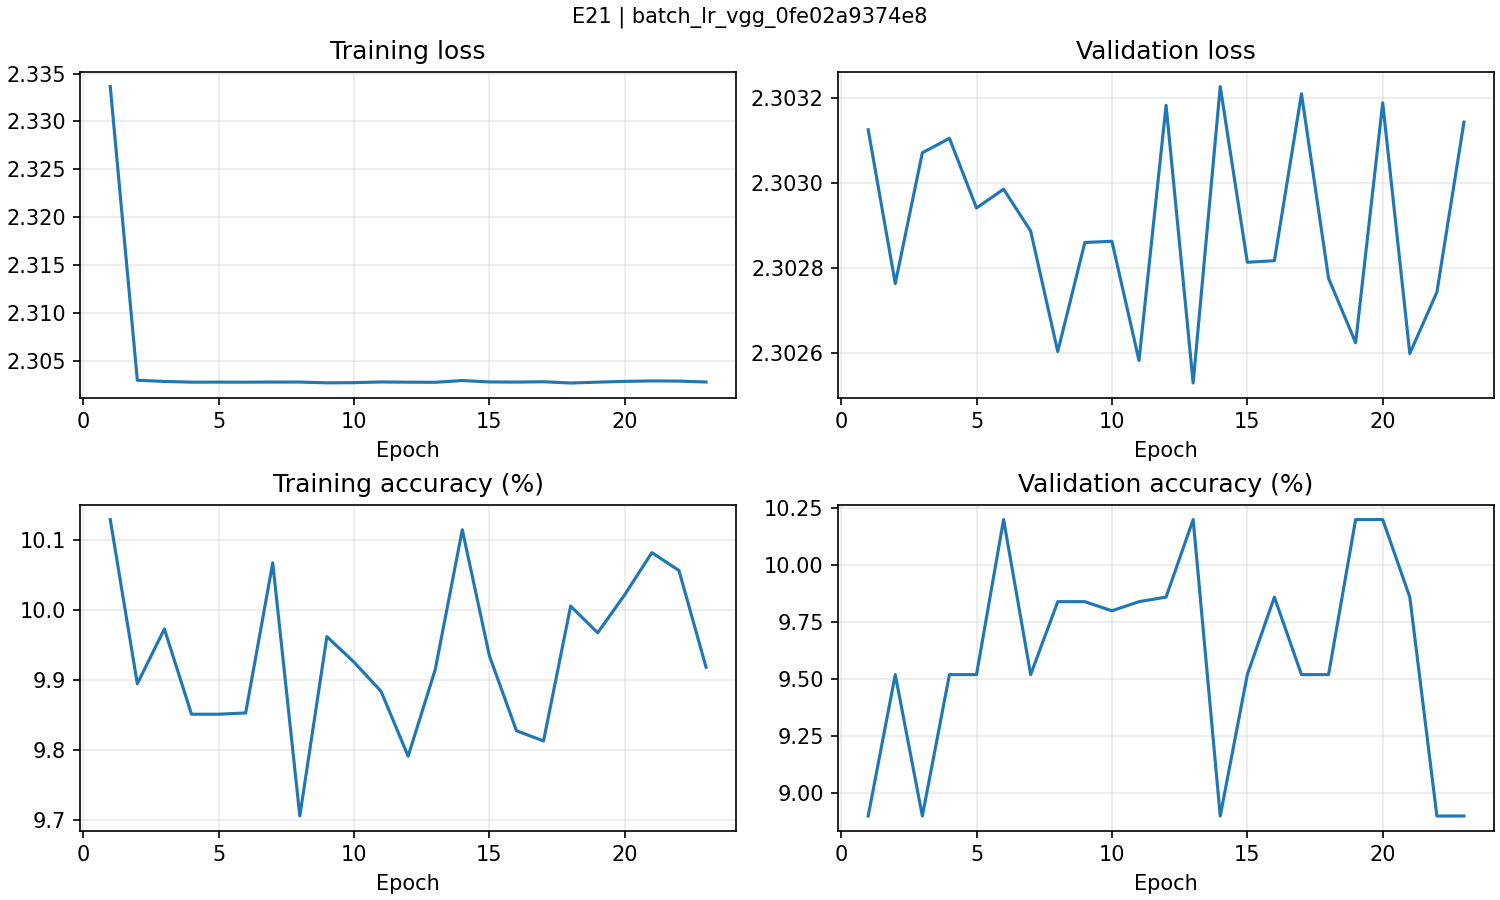

In [52]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'batch_lr_vgg_0fe02a9374e8.png')))

## E22: normalization_tuning_nin_edb1e4a56225

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/1ruzkloa

In [53]:
print((BASE / 'normalization_tuning_nin_edb1e4a56225' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 1ruzkloa
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/normalization_tuning_nin_edb1e4a56225/wandb/run-20261104_052310-1ruzkloa
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn1_drop1_aug1_norm1_seed42_2026-11-04_05-23-10
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/1ruzkloa
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_p

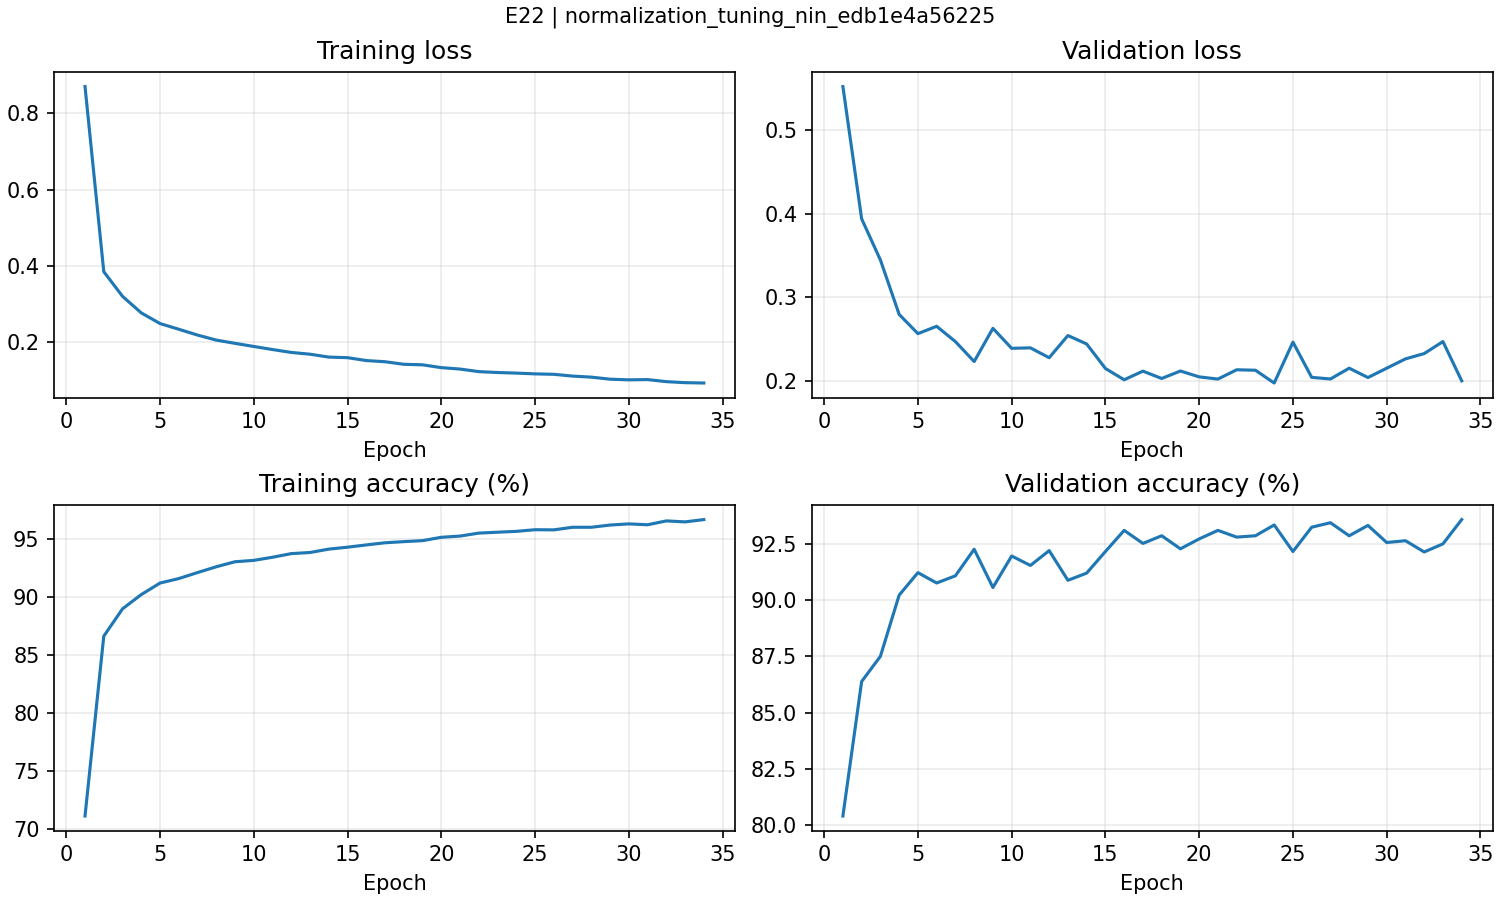

In [54]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'normalization_tuning_nin_edb1e4a56225.png')))

## E23: normalization_tuning_nin_4147206d1b8c

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/1n3nwov9

In [55]:
print((BASE / 'normalization_tuning_nin_4147206d1b8c' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/normalization_tuning_nin_4147206d1b8c/wandb/run-20261104_053127-1n3nwov9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn1_drop1_aug1_norm1_seed42_2026-11-04_05-31-27
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/1n3nwov9
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-

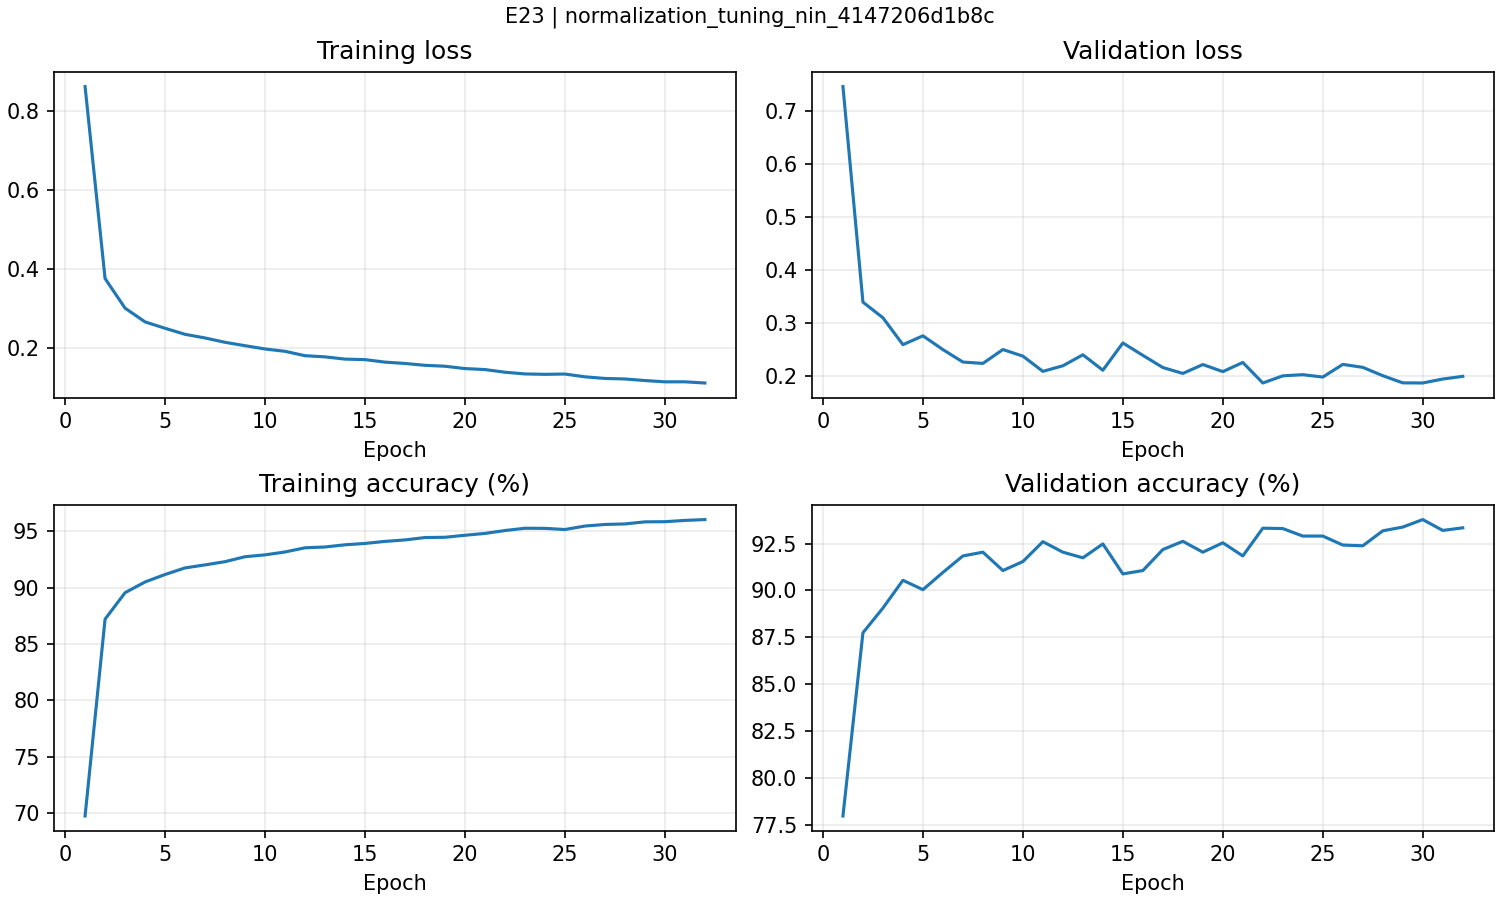

In [56]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'normalization_tuning_nin_4147206d1b8c.png')))

## E24: normalization_tuning_nin_da618c19bd70

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ifjwdgt6

In [57]:
print((BASE / 'normalization_tuning_nin_da618c19bd70' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run ifjwdgt6
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/normalization_tuning_nin_da618c19bd70/wandb/run-20261104_053916-ifjwdgt6
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn1_drop1_aug1_norm1_seed42_2026-11-04_05-39-15
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ifjwdgt6
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_pa

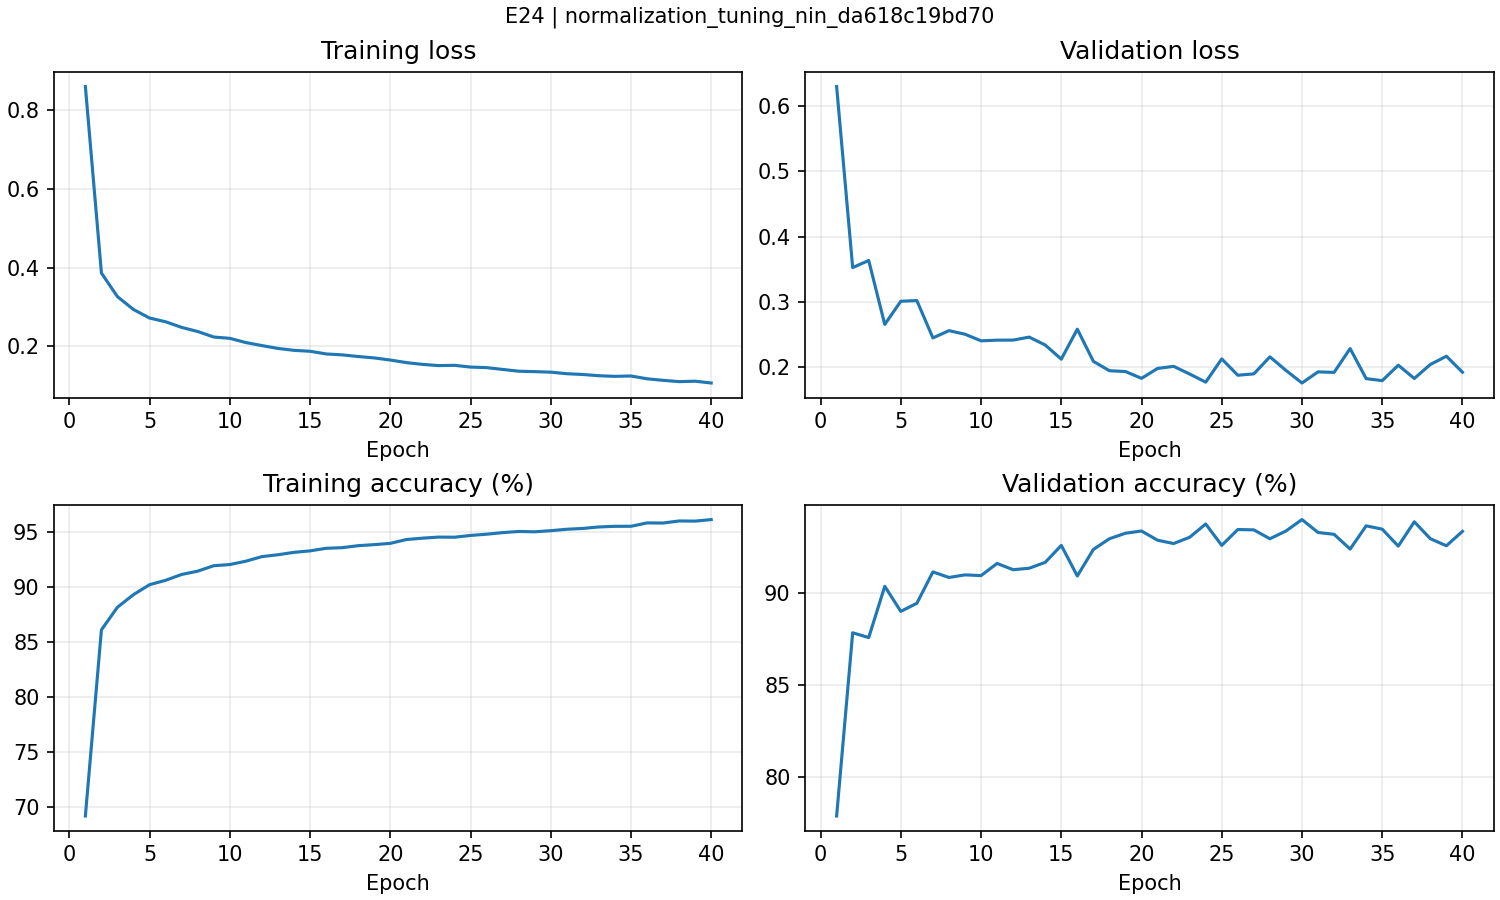

In [58]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'normalization_tuning_nin_da618c19bd70.png')))

## E25: normalization_tuning_vgg_edb82afd29c0

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ab8xs9b6

In [59]:
print((BASE / 'normalization_tuning_vgg_edb82afd29c0' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run ab8xs9b6
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/normalization_tuning_vgg_edb82afd29c0/wandb/run-20261104_042834-ab8xs9b6
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn1_drop0_aug1_norm1_seed42_2026-11-04_04-28-34
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ab8xs9b6
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_p

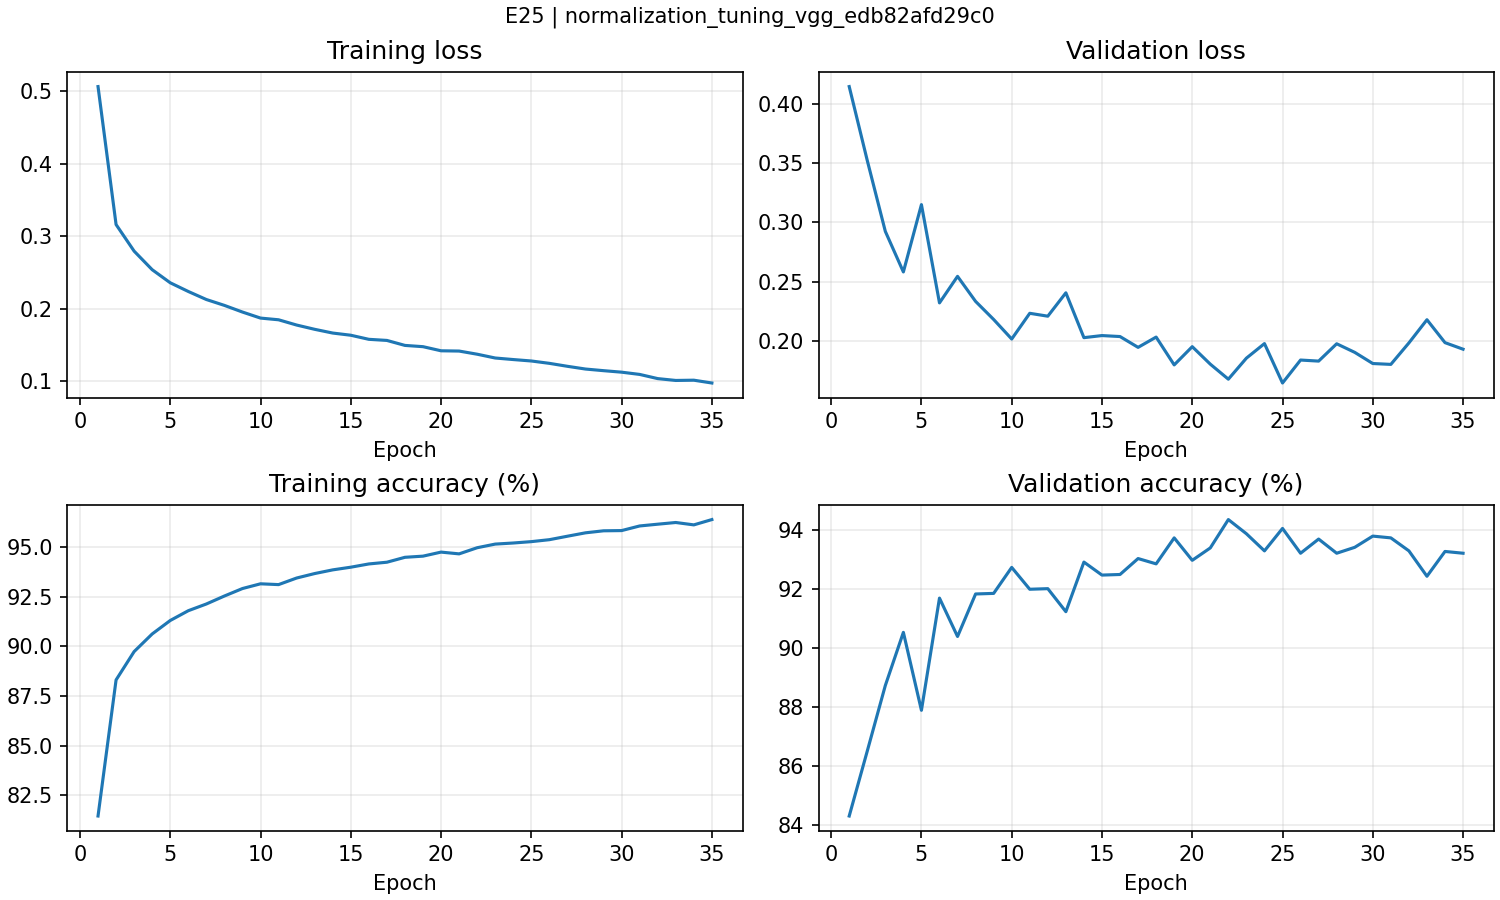

In [60]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'normalization_tuning_vgg_edb82afd29c0.png')))

## E26: normalization_tuning_vgg_be51f2336604

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/c8ffnosk

In [61]:
print((BASE / 'normalization_tuning_vgg_be51f2336604' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run c8ffnosk
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/normalization_tuning_vgg_be51f2336604/wandb/run-20261104_043456-c8ffnosk
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn1_drop0_aug1_norm1_seed42_2026-11-04_04-34-56
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/c8ffnosk
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_pa

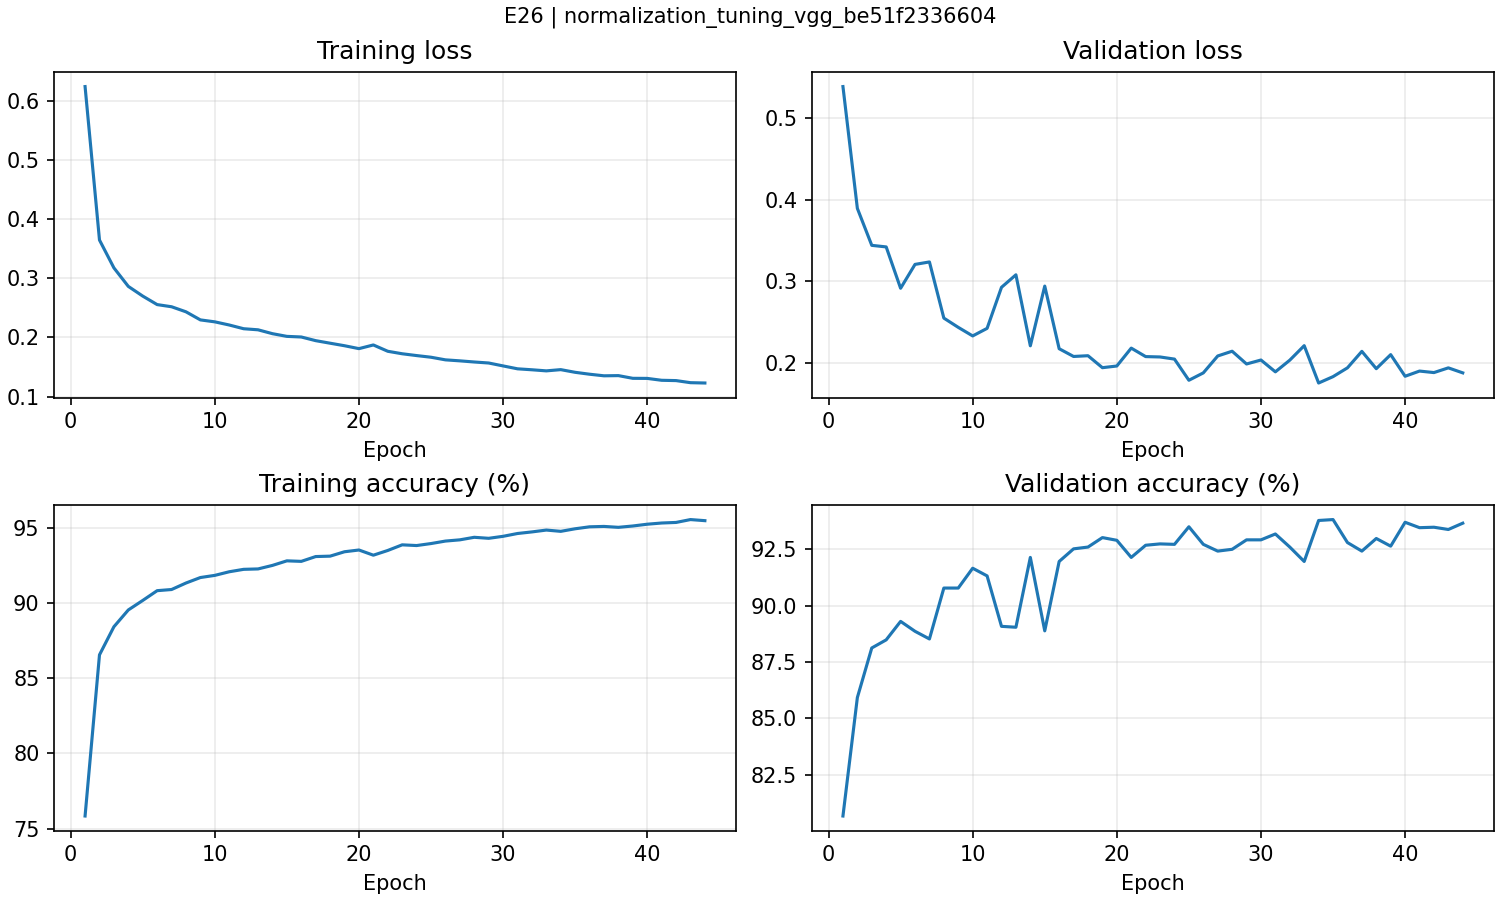

In [62]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'normalization_tuning_vgg_be51f2336604.png')))

## E27: regularization_nin_0de684ab2c14

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/c98xmy56

In [63]:
print((BASE / 'regularization_nin_0de684ab2c14' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_nin_0de684ab2c14/wandb/run-20261104_044303-c98xmy56
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop0_aug0_norm1_seed42_2026-11-04_04-43-03
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/c98xmy56
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, op

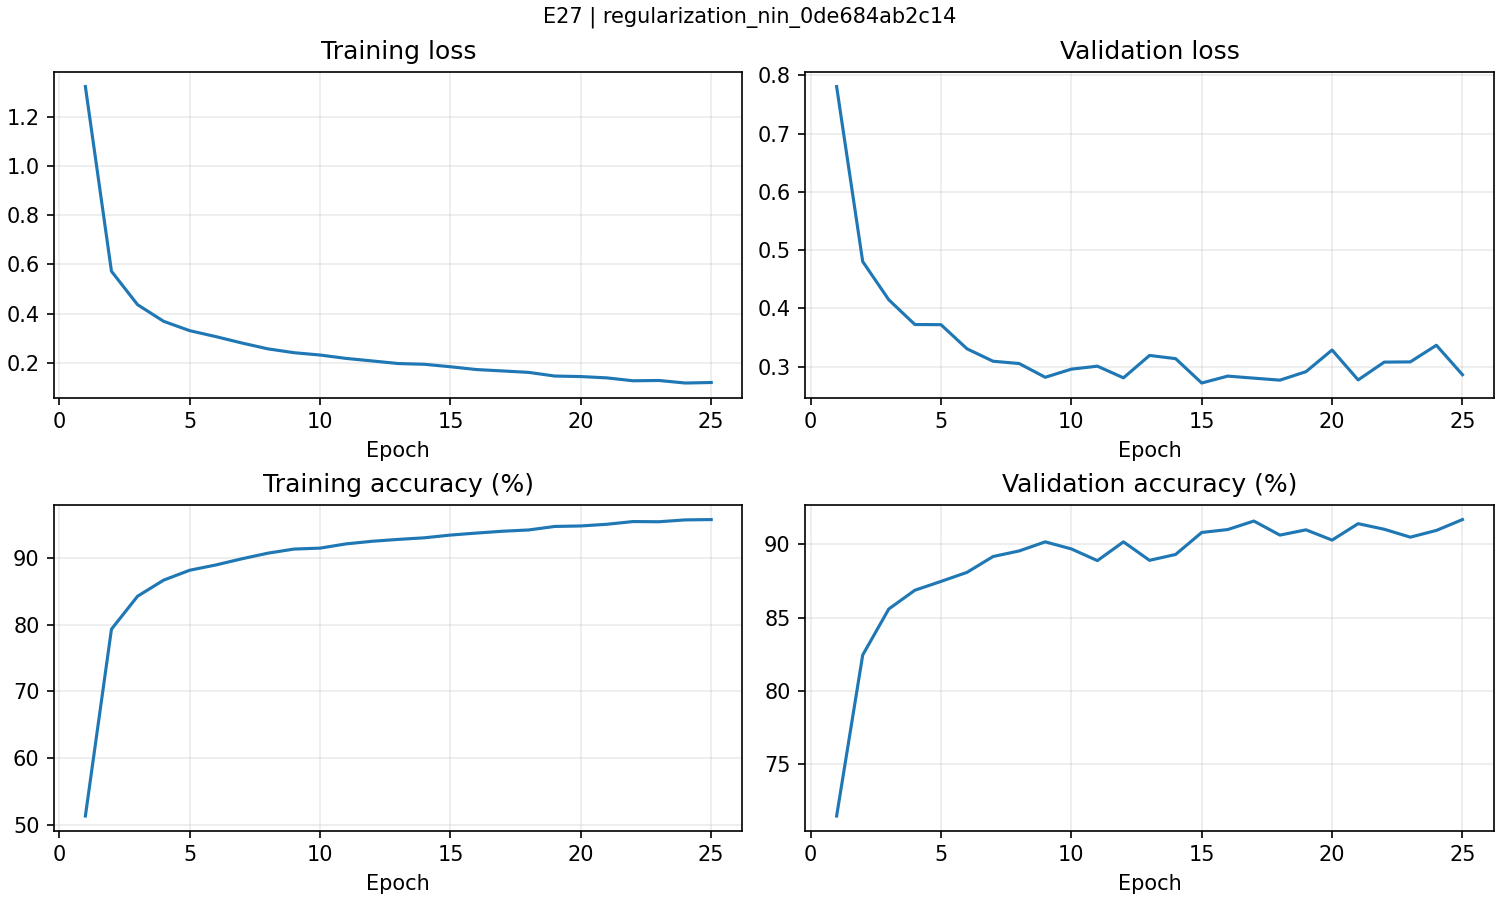

In [64]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_nin_0de684ab2c14.png')))

## E28: regularization_nin_ede643b317b8

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/xxawt4uq

In [65]:
print((BASE / 'regularization_nin_ede643b317b8' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run xxawt4uq
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_nin_ede643b317b8/wandb/run-20261104_051014-xxawt4uq
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug1_norm1_seed42_2026-11-04_05-10-14
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/xxawt4uq
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience

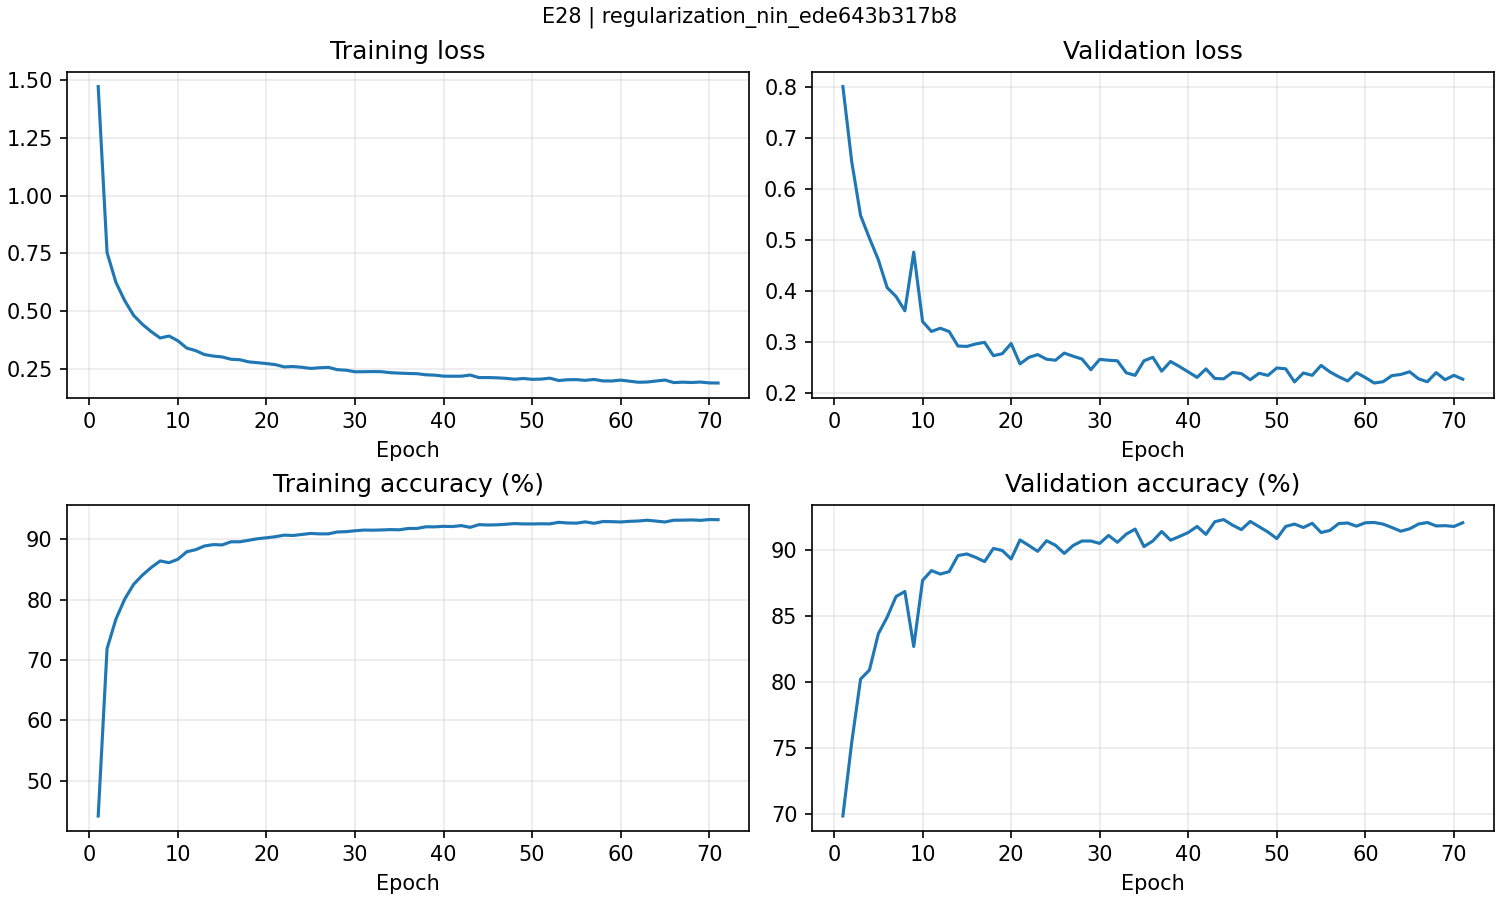

In [66]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_nin_ede643b317b8.png')))

## E29: regularization_nin_9e99171ae626

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/oqyj3cvw

In [67]:
print((BASE / 'regularization_nin_9e99171ae626' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_nin_9e99171ae626/wandb/run-20261104_045247-oqyj3cvw
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop0_aug1_norm1_seed42_2026-11-04_04-52-46
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/oqyj3cvw
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, op

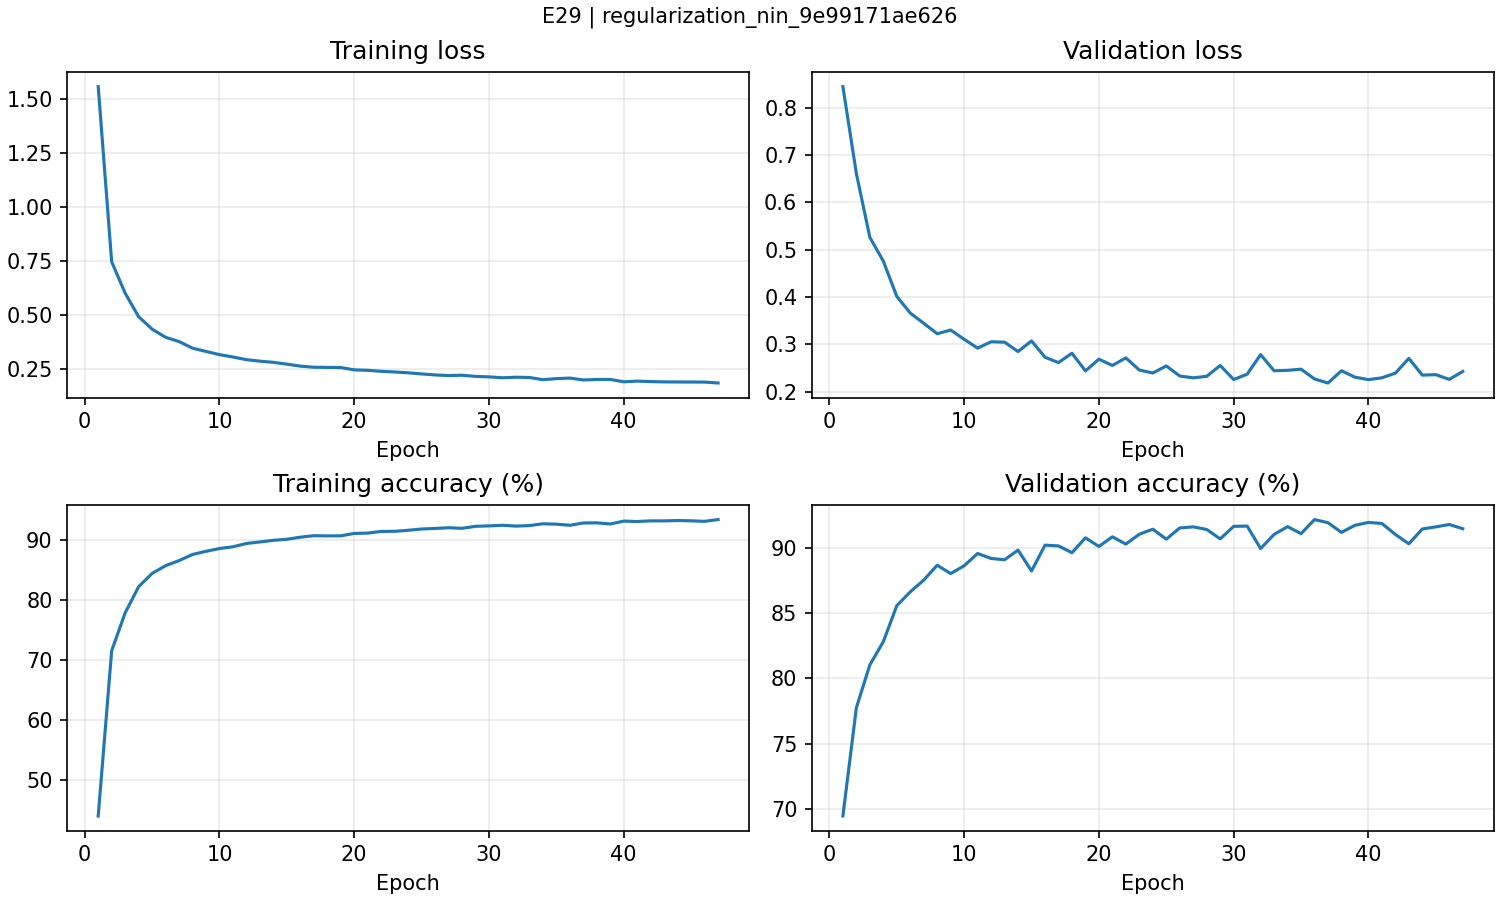

In [68]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_nin_9e99171ae626.png')))

## E30: regularization_nin_b34201381f59

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/rfsr1dti

In [69]:
print((BASE / 'regularization_nin_b34201381f59' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run rfsr1dti
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_nin_b34201381f59/wandb/run-20261104_044739-rfsr1dti
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_04-47-39
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/rfsr1dti
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience

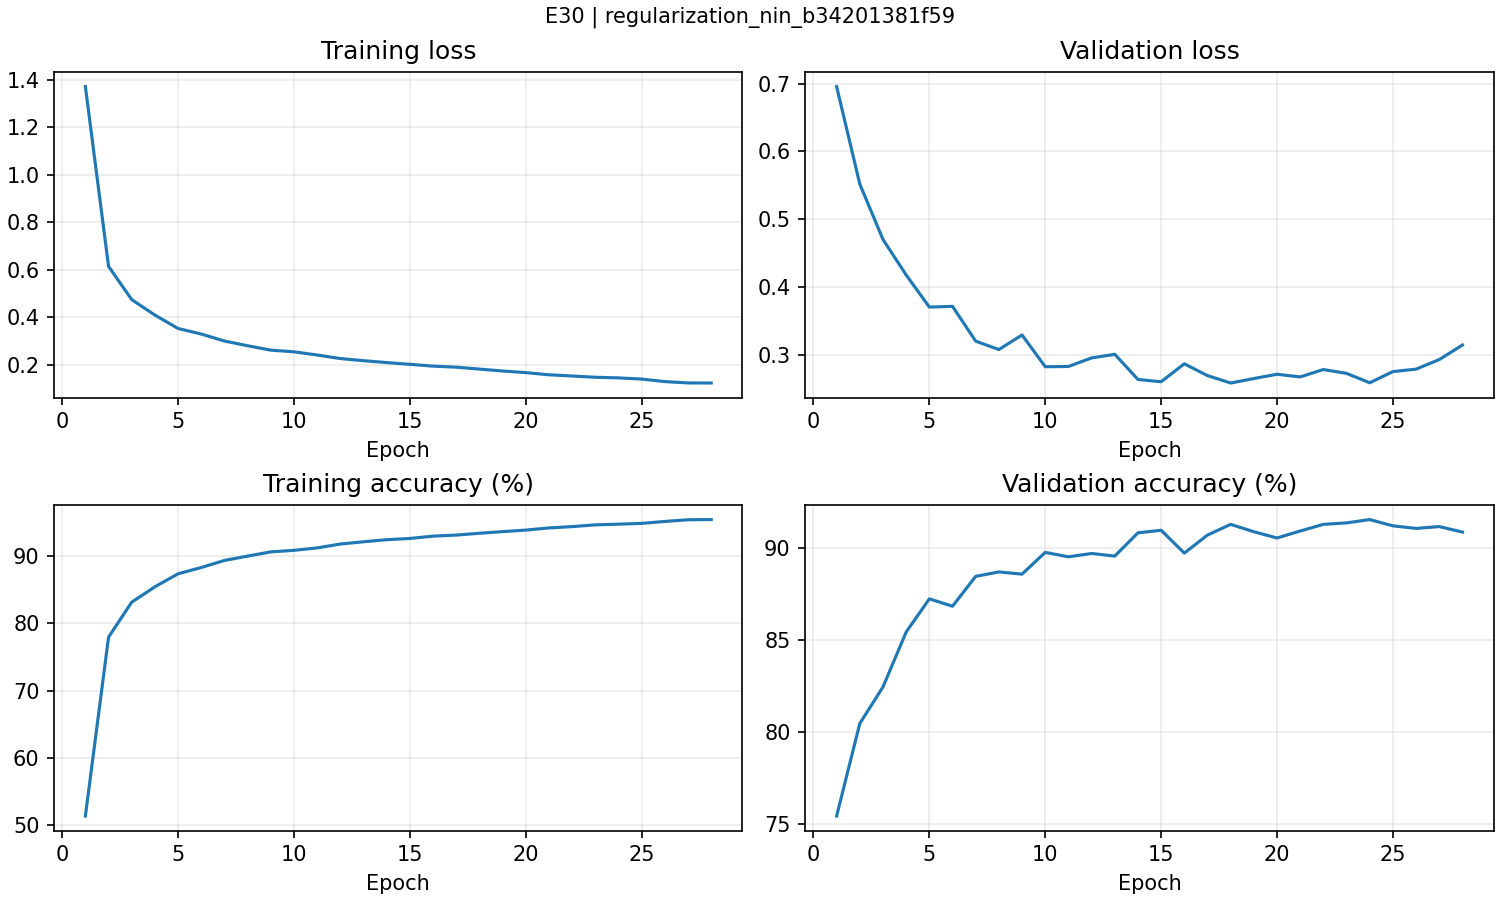

In [70]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_nin_b34201381f59.png')))

## E31: regularization_nin_ce87cf010e46

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/3v65ms9f

In [71]:
print((BASE / 'regularization_nin_ce87cf010e46' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_nin_ce87cf010e46/wandb/run-20261104_050125-3v65ms9f
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug1_norm1_seed42_2026-11-04_05-01-25
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/3v65ms9f
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, op

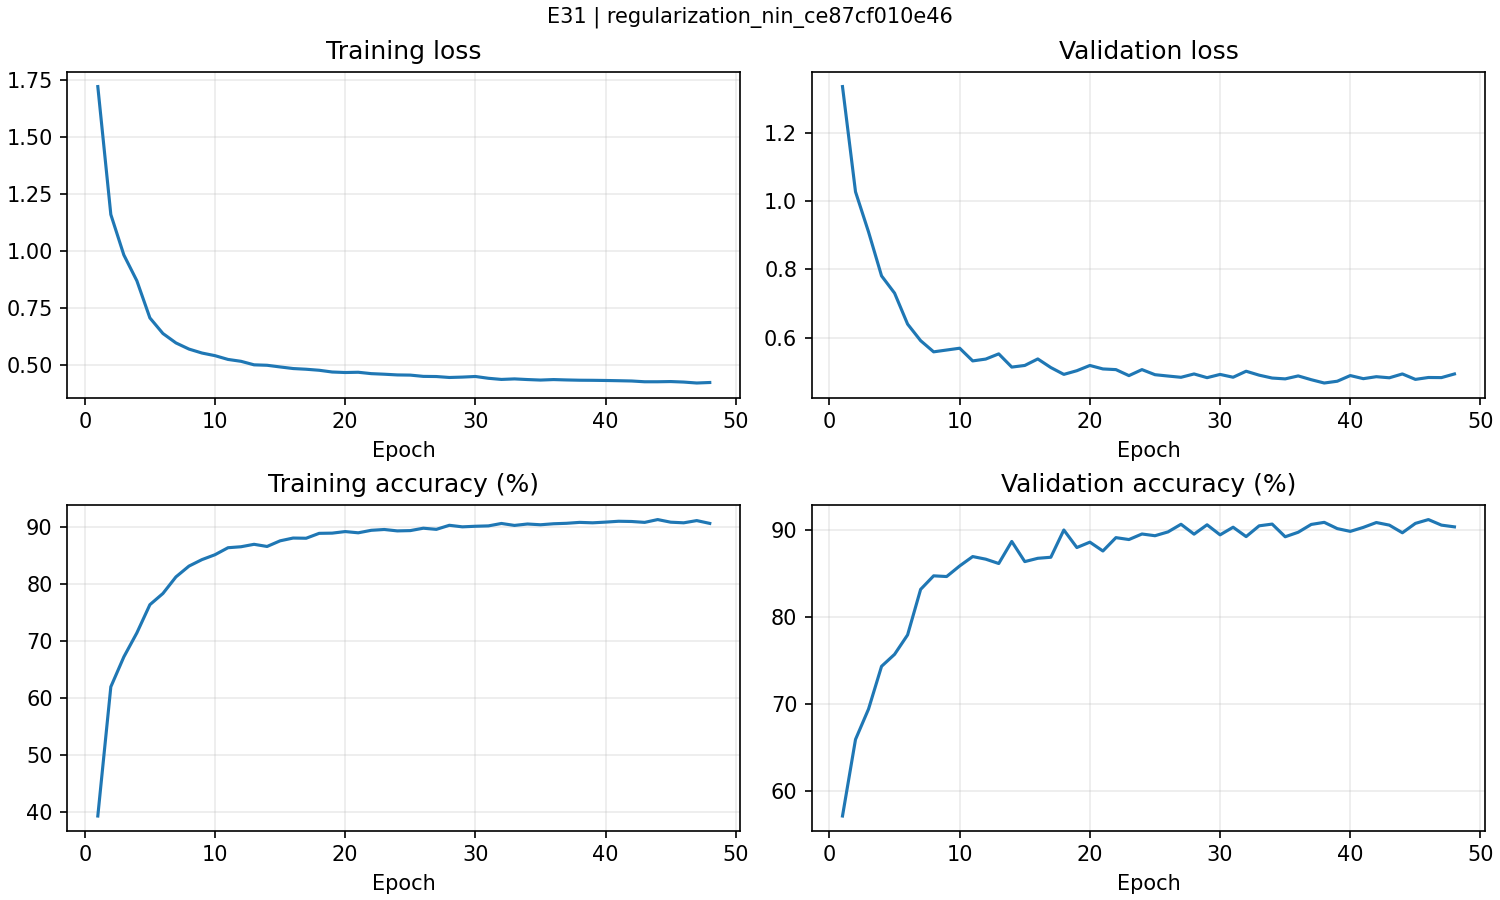

In [72]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_nin_ce87cf010e46.png')))

## E32: regularization_vgg_85fc84c27464

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/78qjgvj1

In [73]:
print((BASE / 'regularization_vgg_85fc84c27464' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 78qjgvj1
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_vgg_85fc84c27464/wandb/run-20261104_040640-78qjgvj1
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_04-06-39
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/78qjgvj1
wandb: updating run metadata
wandb: uploading history steps 16-17, summary, console lines 88-90
wandb: 
wandb: Run history:
wandb:   

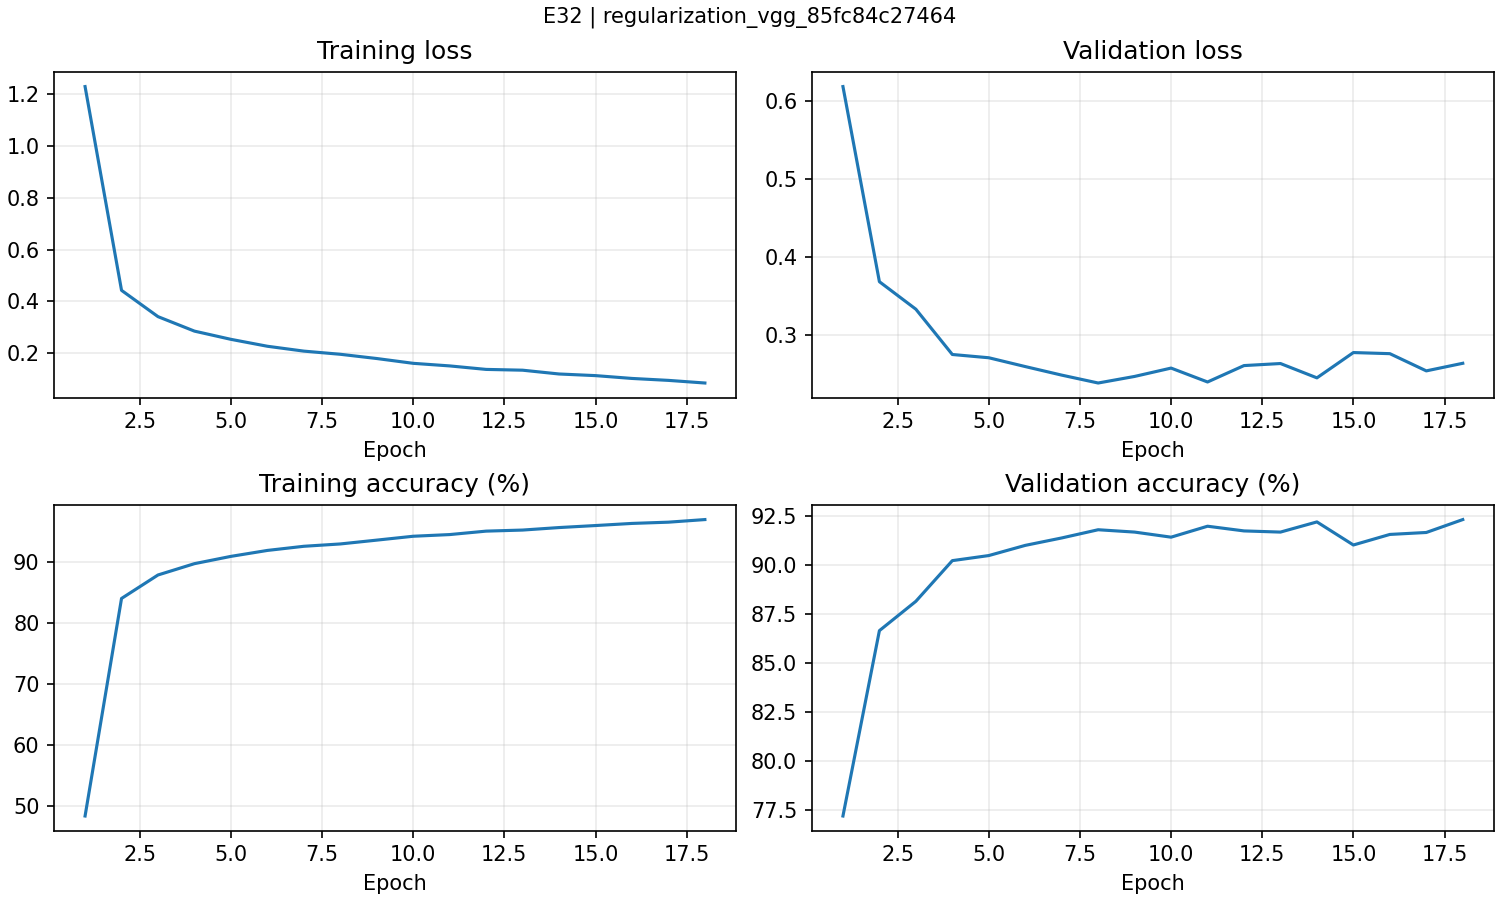

In [74]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_vgg_85fc84c27464.png')))

## E33: regularization_vgg_38c41d071f6d

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bmuwf6n8

In [75]:
print((BASE / 'regularization_vgg_38c41d071f6d' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run bmuwf6n8
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_vgg_38c41d071f6d/wandb/run-20261104_042255-bmuwf6n8
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug1_norm1_seed42_2026-11-04_04-22-55
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bmuwf6n8
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience

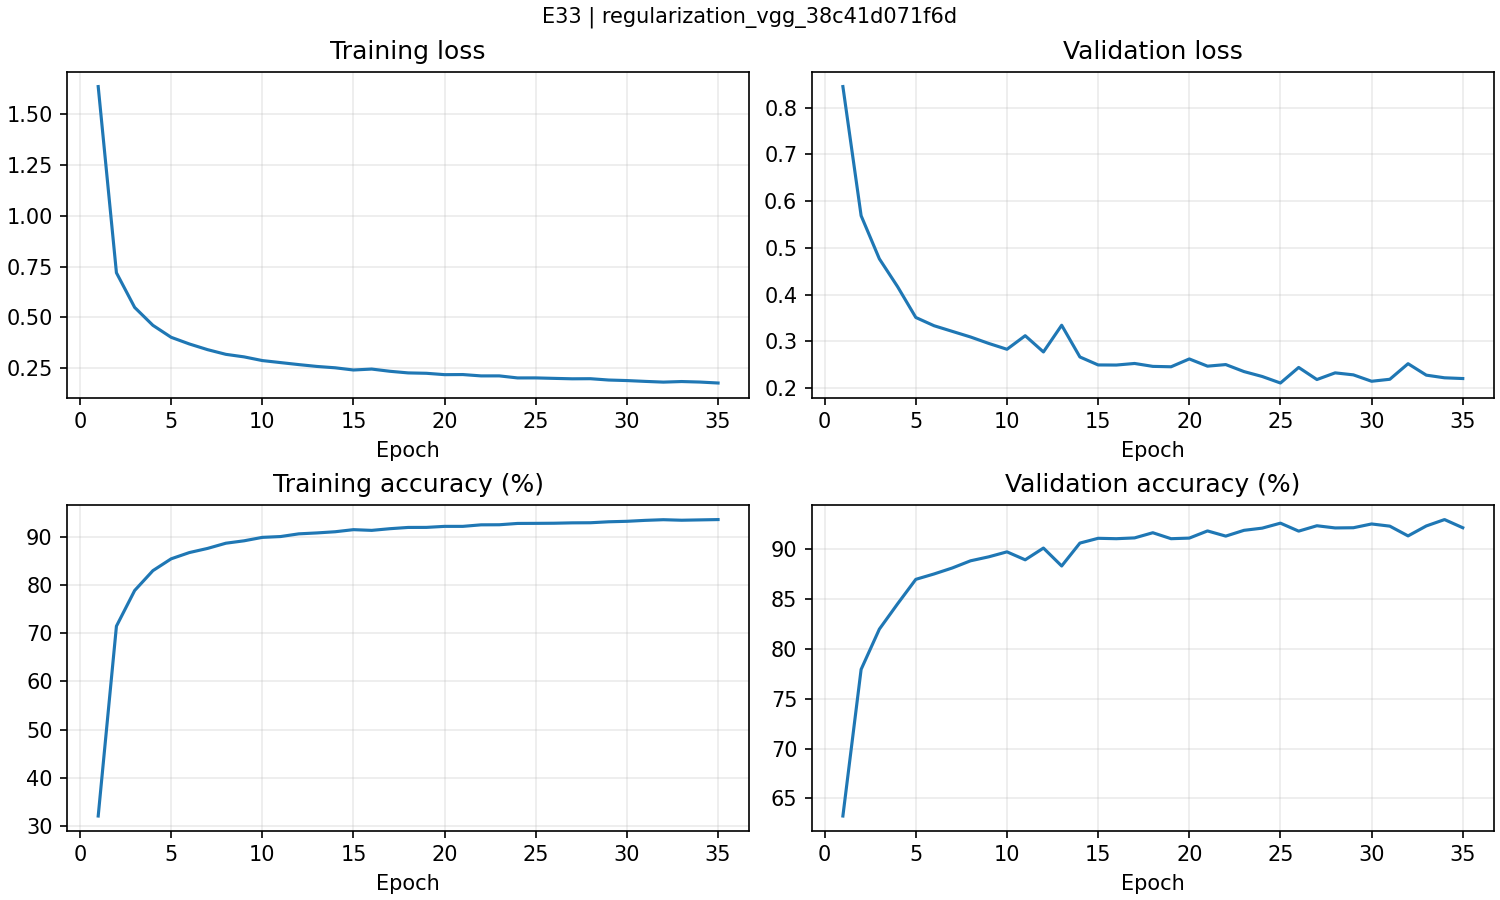

In [76]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_vgg_38c41d071f6d.png')))

## E34: regularization_vgg_3cc67b2338f1

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ytx4b8us

In [77]:
print((BASE / 'regularization_vgg_3cc67b2338f1' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_vgg_3cc67b2338f1/wandb/run-20261104_040309-ytx4b8us
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop0_aug0_norm1_seed42_2026-11-04_04-03-09
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/ytx4b8us
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, op

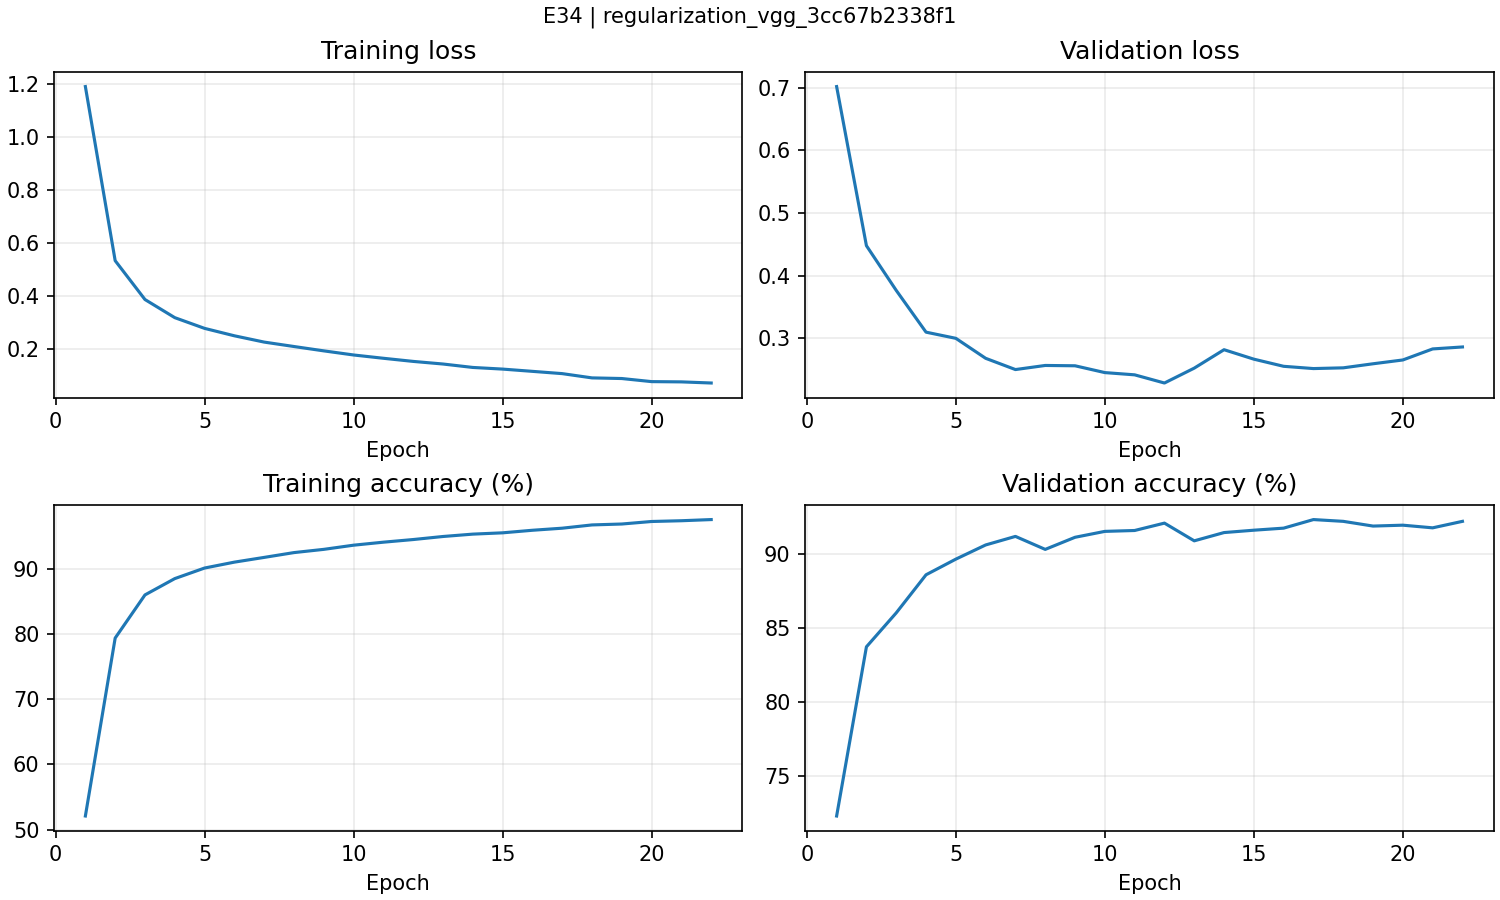

In [78]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_vgg_3cc67b2338f1.png')))

## E35: regularization_vgg_515f0d8da6a6

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8kr3bwor

In [79]:
print((BASE / 'regularization_vgg_515f0d8da6a6' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_vgg_515f0d8da6a6/wandb/run-20261104_040938-8kr3bwor
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop0_aug1_norm1_seed42_2026-11-04_04-09-36
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8kr3bwor
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, op

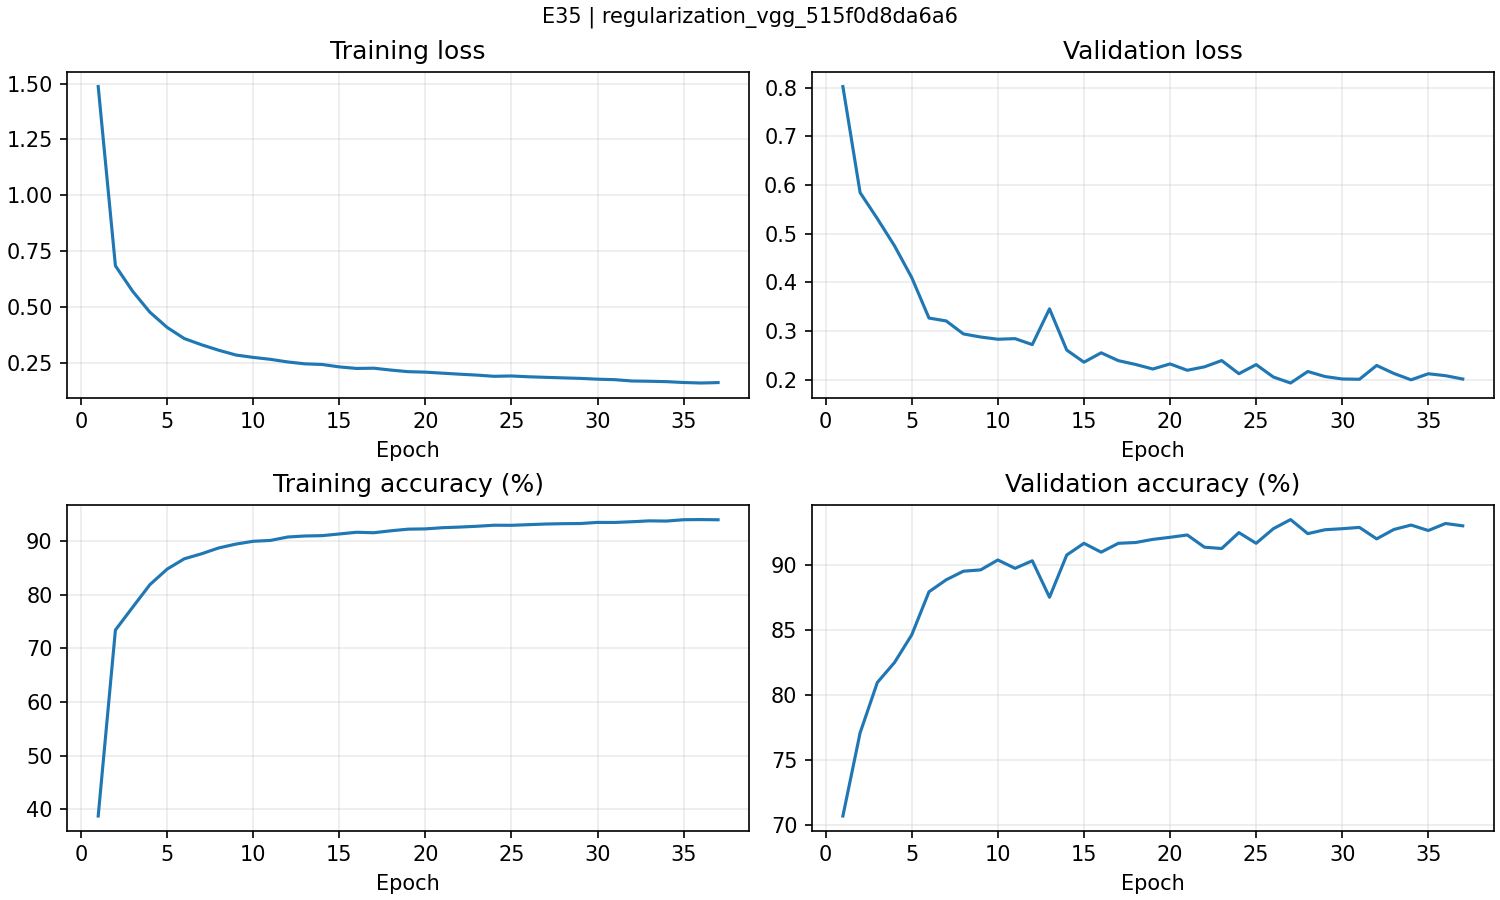

In [80]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_vgg_515f0d8da6a6.png')))

## E36: regularization_vgg_40fe215c71bb

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/zz4s7pra

In [81]:
print((BASE / 'regularization_vgg_40fe215c71bb' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run zz4s7pra
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/regularization_vgg_40fe215c71bb/wandb/run-20261104_041535-zz4s7pra
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug1_norm1_seed42_2026-11-04_04-15-35
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/zz4s7pra
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience

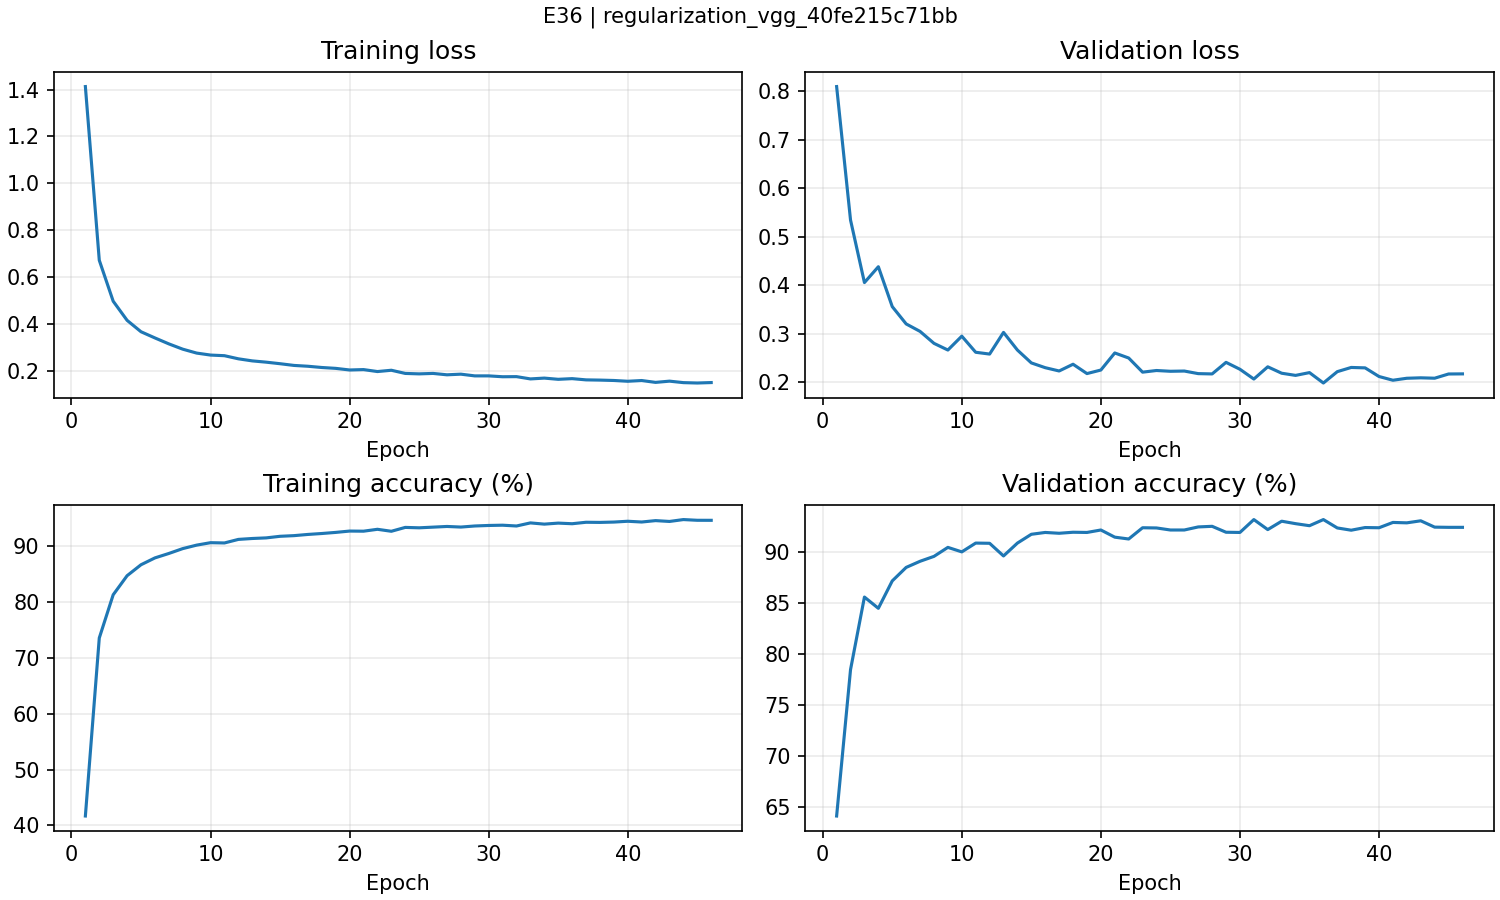

In [82]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'regularization_vgg_40fe215c71bb.png')))

## E37: repeat_seed_nin_b72c8d051474

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/mcz7xtiq

In [83]:
print((BASE / 'repeat_seed_nin_b72c8d051474' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/repeat_seed_nin_b72c8d051474/wandb/run-20261104_060158-mcz7xtiq
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn1_drop1_aug1_norm1_seed43_2026-11-04_06-01-58
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/mcz7xtiq
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optim

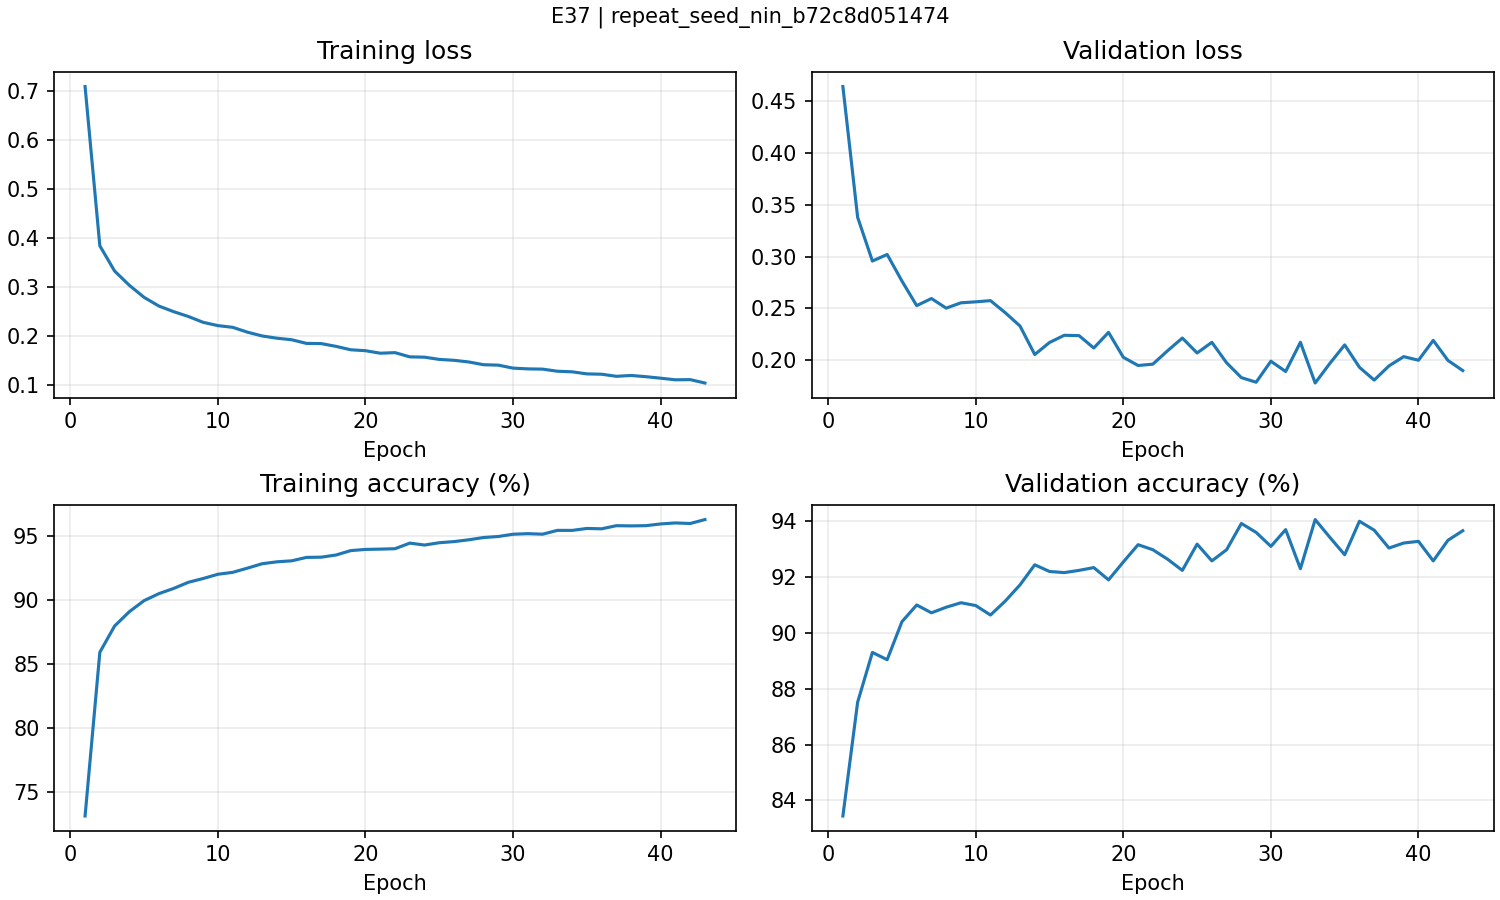

In [84]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'repeat_seed_nin_b72c8d051474.png')))

## E38: repeat_seed_nin_ef64b827cd3f

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/rof2e34m

In [85]:
print((BASE / 'repeat_seed_nin_ef64b827cd3f' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/repeat_seed_nin_ef64b827cd3f/wandb/run-20261104_061223-rof2e34m
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn1_drop1_aug1_norm1_seed44_2026-11-04_06-12-23
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/rof2e34m
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, optim

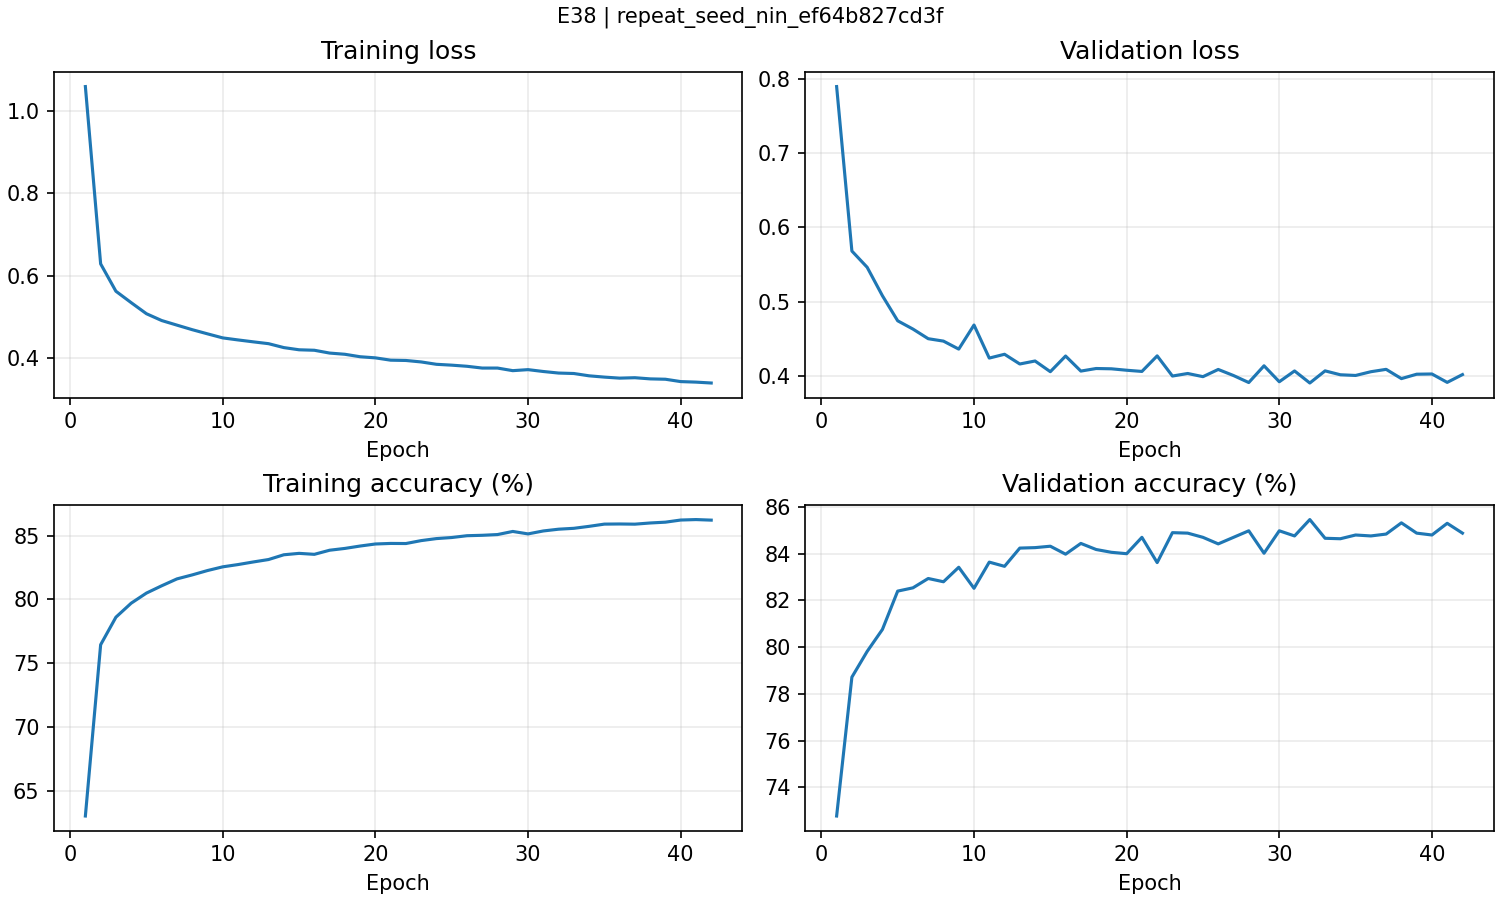

In [86]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'repeat_seed_nin_ef64b827cd3f.png')))

## E39: repeat_seed_vgg_45ea821751fd

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/pig8ruzl

In [87]:
print((BASE / 'repeat_seed_vgg_45ea821751fd' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/repeat_seed_vgg_45ea821751fd/wandb/run-20261104_054910-pig8ruzl
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn1_drop0_aug1_norm1_seed43_2026-11-04_05-49-09
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/pig8ruzl
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, opti

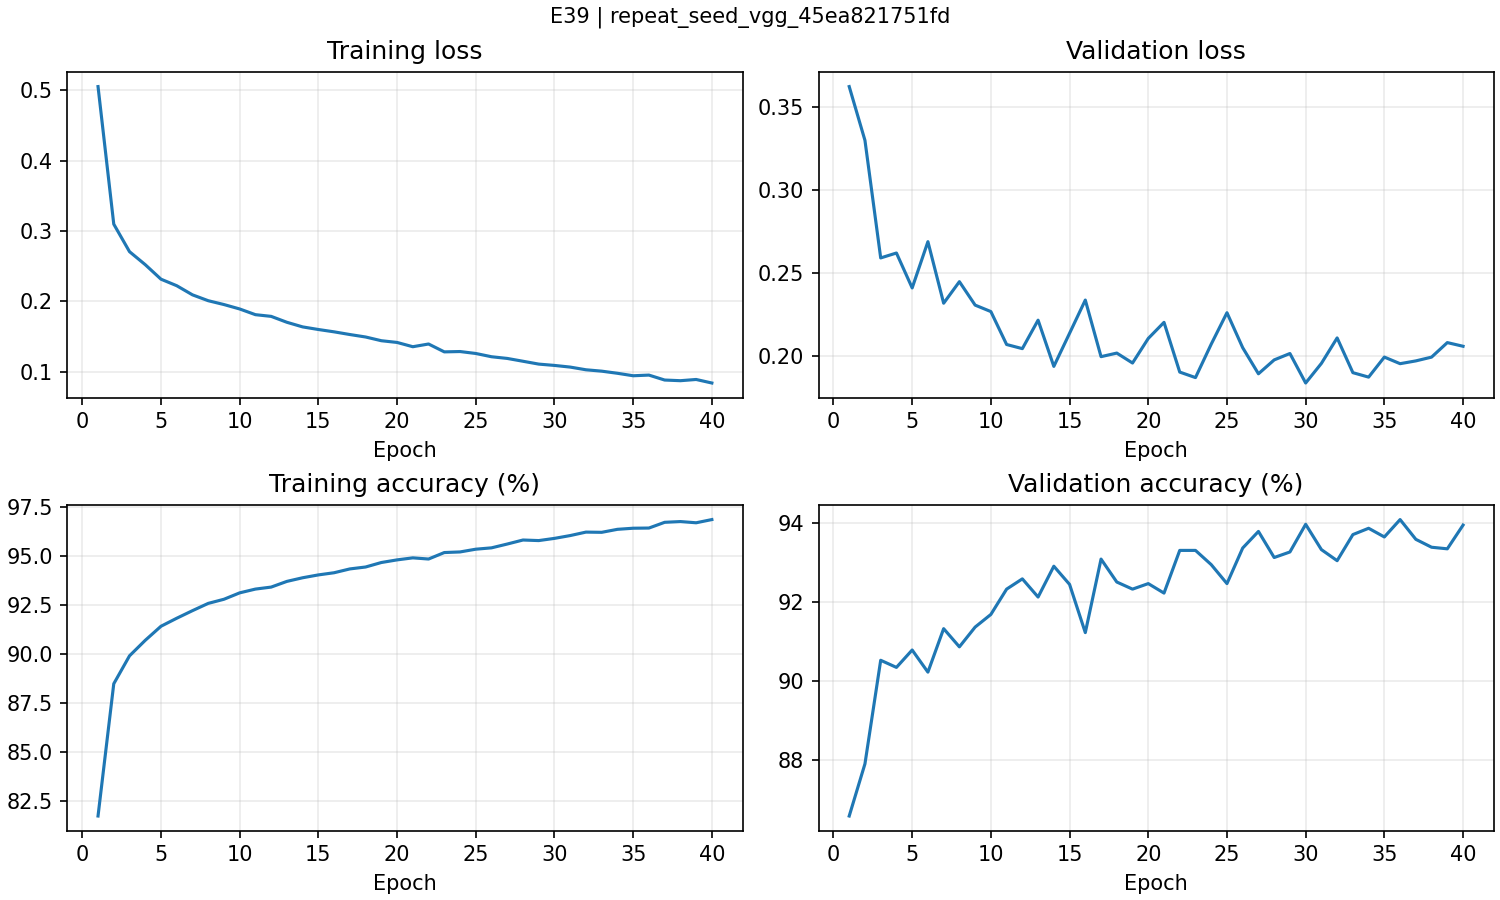

In [88]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'repeat_seed_vgg_45ea821751fd.png')))

## E40: repeat_seed_vgg_46531bb26628

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/g7xf1v21

In [89]:
print((BASE / 'repeat_seed_vgg_46531bb26628' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/repeat_seed_vgg_46531bb26628/wandb/run-20261104_055626-g7xf1v21
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn1_drop0_aug1_norm1_seed44_2026-11-04_05-56-26
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/g7xf1v21
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, opti

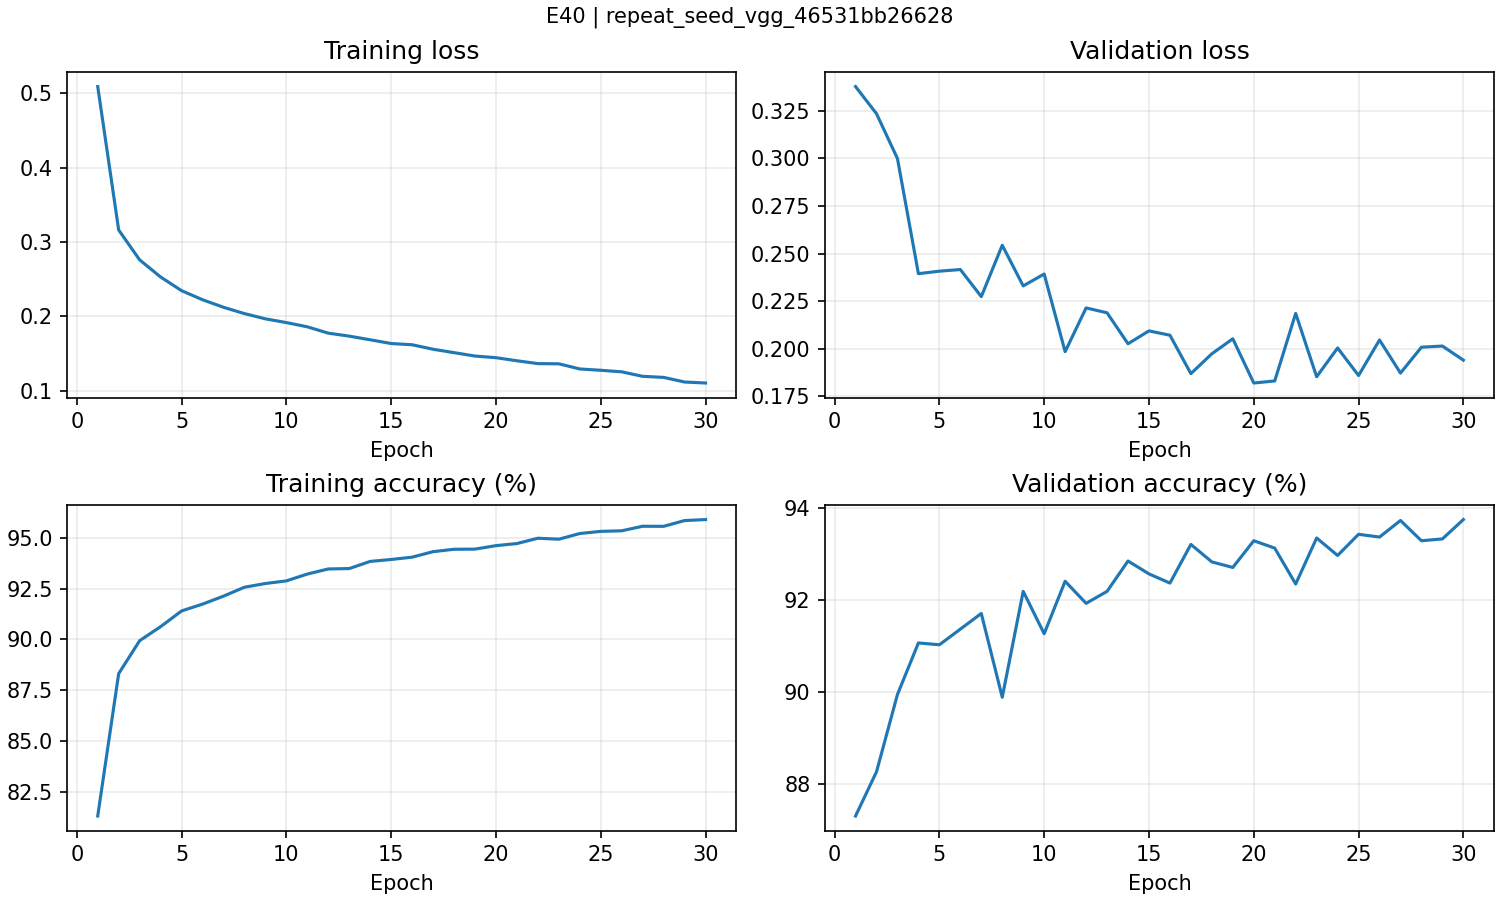

In [90]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'repeat_seed_vgg_46531bb26628.png')))

## E41: weight_decay_nin_070a62b3107c

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8qp8vww2

In [91]:
print((BASE / 'weight_decay_nin_070a62b3107c' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_nin_070a62b3107c/wandb/run-20261104_034517-8qp8vww2
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-45-16
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/8qp8vww2
/home/link/link_dl
Namespace(wandb=True, batch_size=128, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=10, early_stop_delta=1e-05, opti

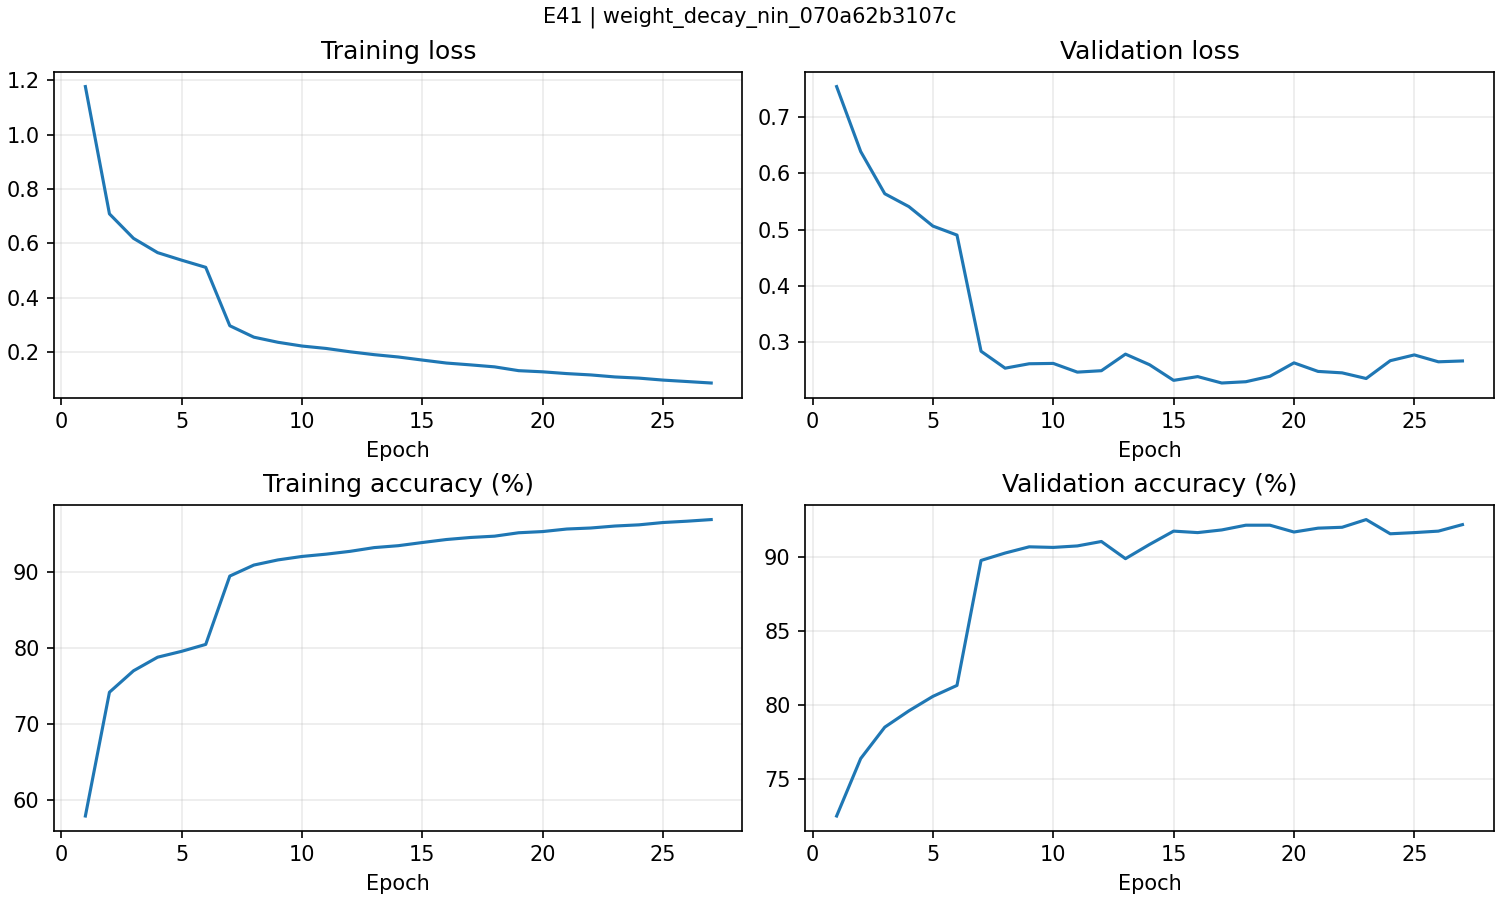

In [92]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_nin_070a62b3107c.png')))

## E42: weight_decay_nin_d7f669f668a6

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/7jml8gei

In [93]:
print((BASE / 'weight_decay_nin_d7f669f668a6' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 7jml8gei
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_nin_d7f669f668a6/wandb/run-20261104_035124-7jml8gei
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-51-24
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/7jml8gei
wandb: updating run metadata
wandb: uploading history steps 14-14, summary, console lines 86-87
wandb: 
wandb: Run history:
wandb:     

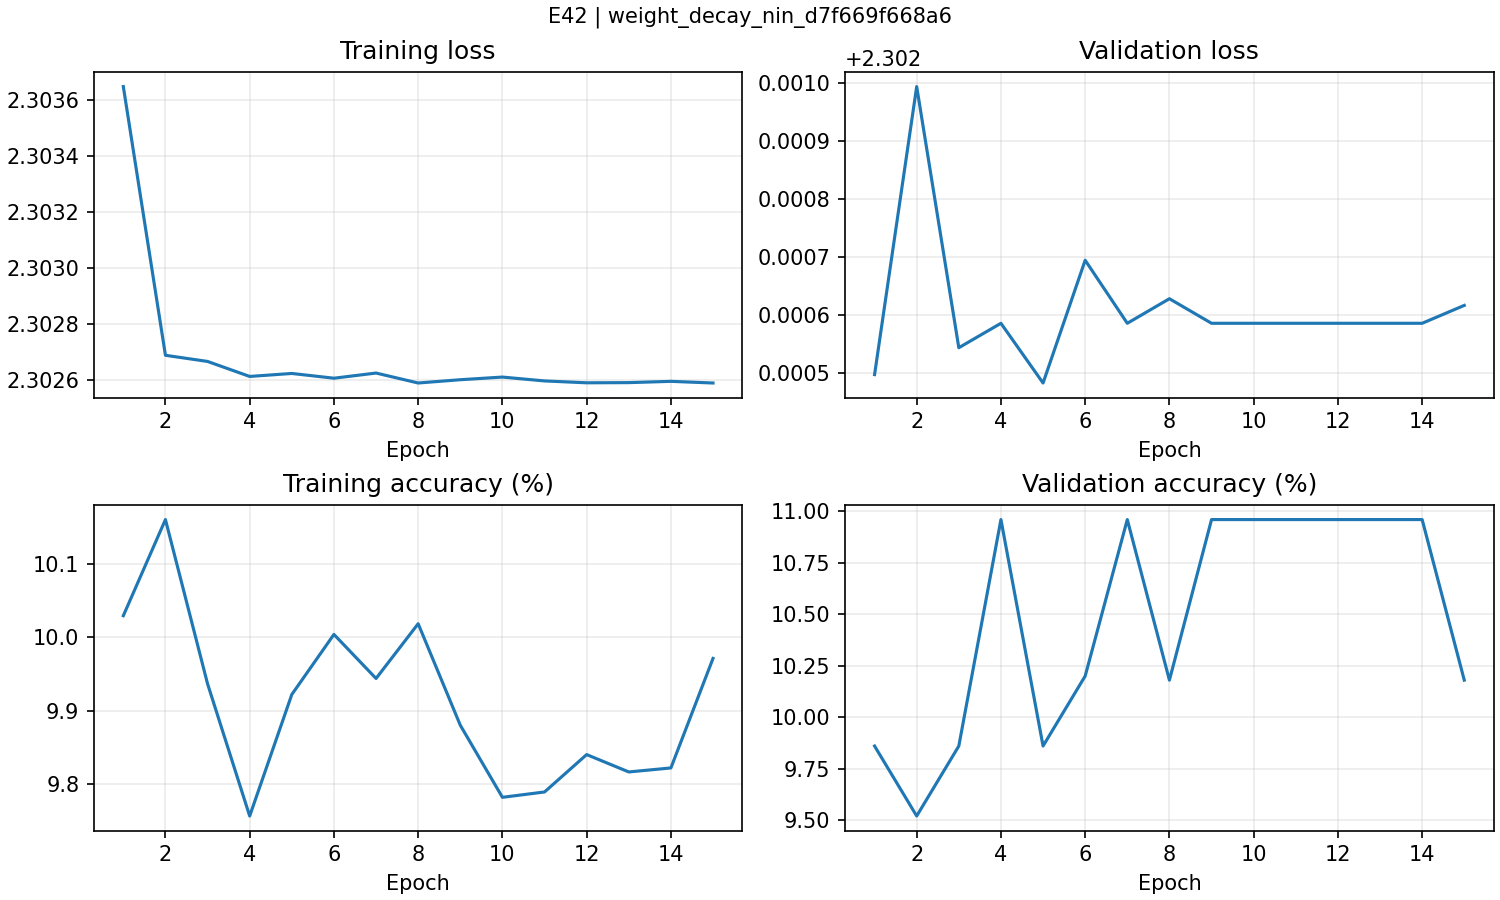

In [94]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_nin_d7f669f668a6.png')))

## E43: weight_decay_nin_6ab096323058

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/lpnug33f

In [95]:
print((BASE / 'weight_decay_nin_6ab096323058' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run lpnug33f
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_nin_6ab096323058/wandb/run-20261104_040053-lpnug33f
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_04-00-53
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/lpnug33f
wandb: updating run metadata
wandb: uploading history steps 10-10, summary, console lines 82-83
wandb: 
wandb: Run history:
wandb:     

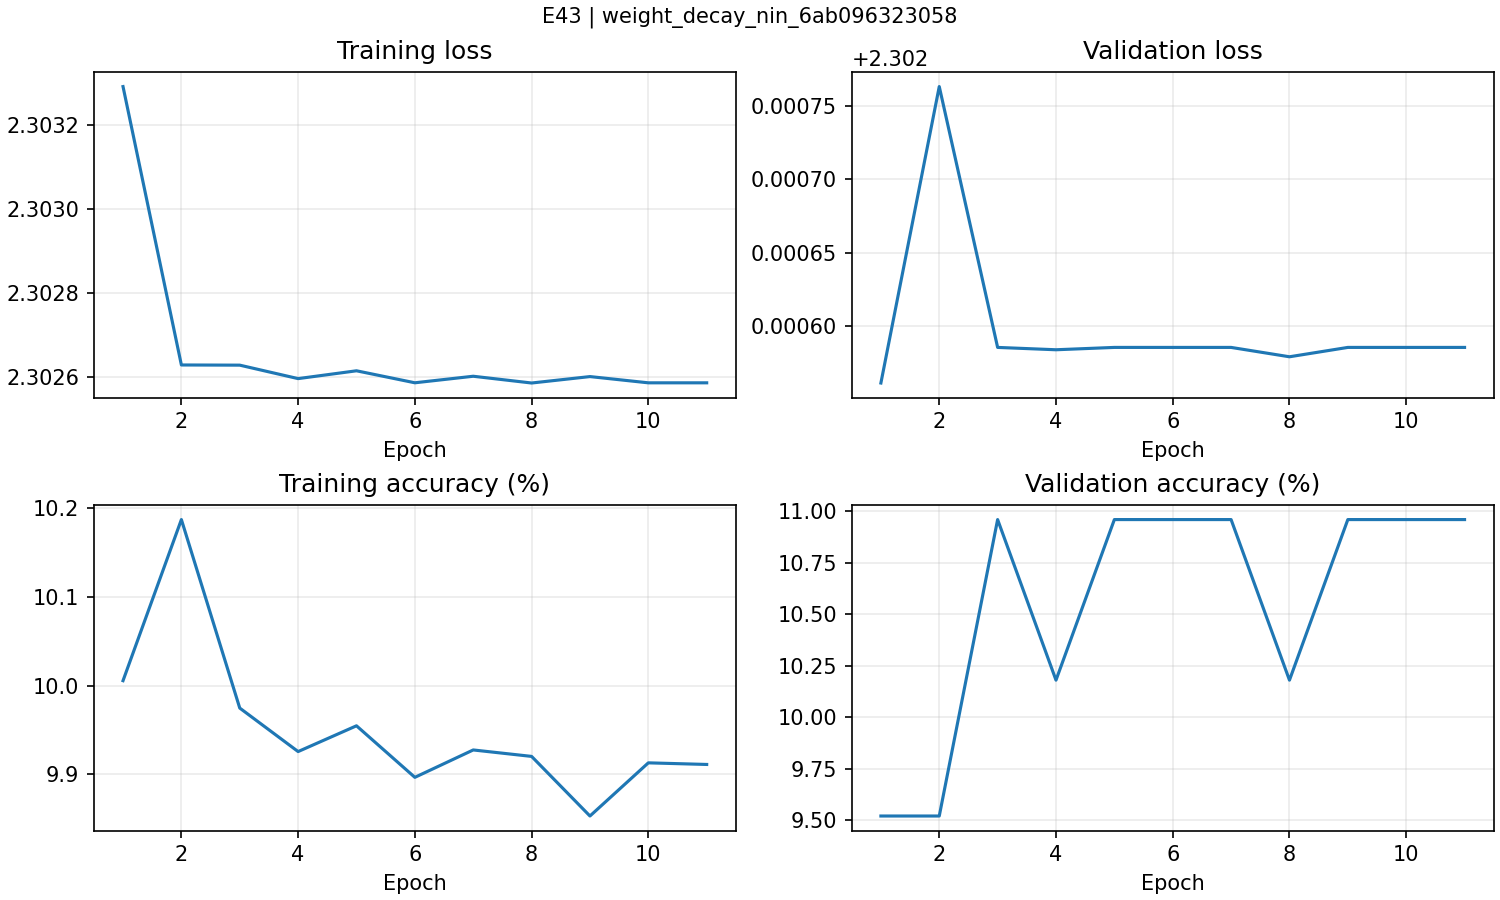

In [96]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_nin_6ab096323058.png')))

## E44: weight_decay_nin_d0b2f1b6f058

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/dj3gviey

In [97]:
print((BASE / 'weight_decay_nin_d0b2f1b6f058' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run dj3gviey
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_nin_d0b2f1b6f058/wandb/run-20261104_035425-dj3gviey
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run nin_bn0_drop1_aug0_norm1_seed42_2026-11-04_03-54-24
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/dj3gviey
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.003, validation_intervals=1, early_stop_patience=1

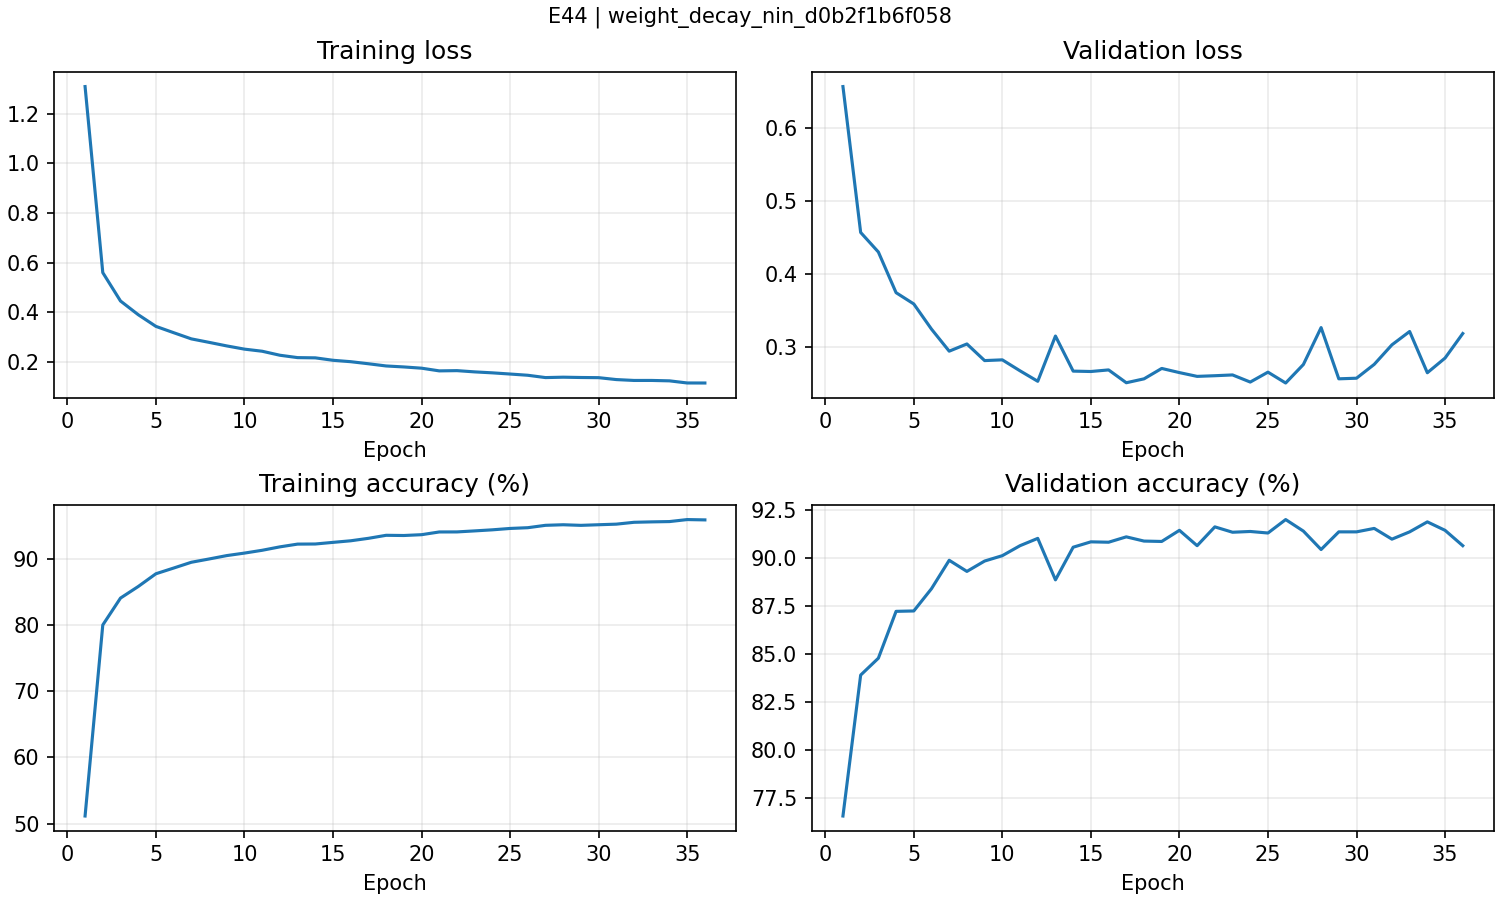

In [98]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_nin_d0b2f1b6f058.png')))

## E45: weight_decay_vgg_4f259f8f8440

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bj9a9a1s

In [99]:
print((BASE / 'weight_decay_vgg_4f259f8f8440' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run bj9a9a1s
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_vgg_4f259f8f8440/wandb/run-20261104_024400-bj9a9a1s
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-44-00
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/bj9a9a1s
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.0003, validation_intervals=1, early_stop_patience=

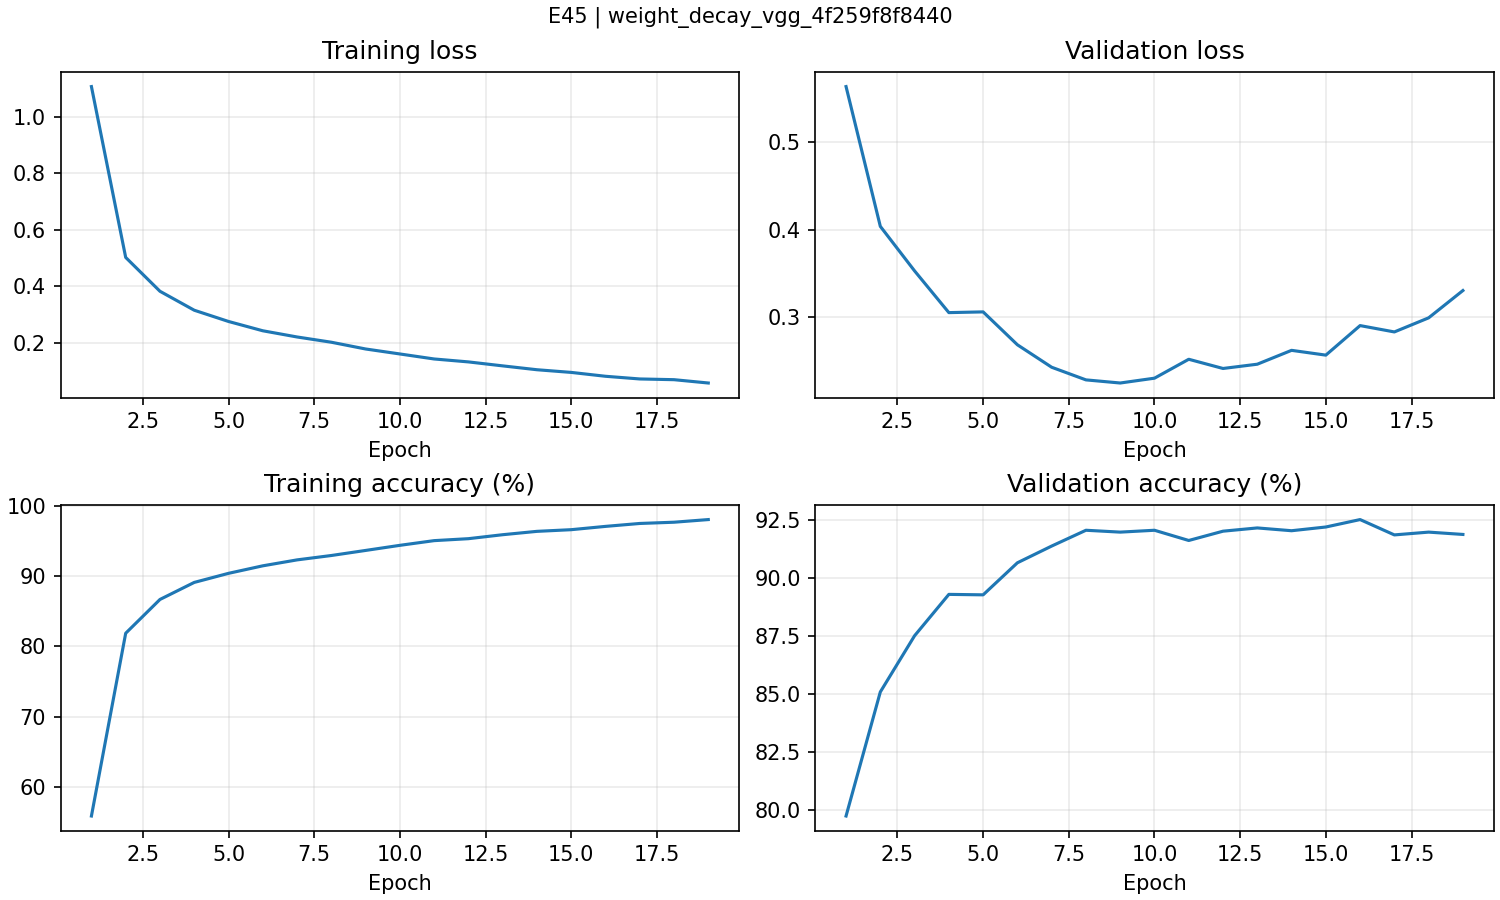

In [100]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_vgg_4f259f8f8440.png')))

## E46: weight_decay_vgg_83db9ea76375

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/nip6h25w

In [101]:
print((BASE / 'weight_decay_vgg_83db9ea76375' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_vgg_83db9ea76375/wandb/run-20261104_024658-nip6h25w
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-46-58
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/nip6h25w
wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:                      

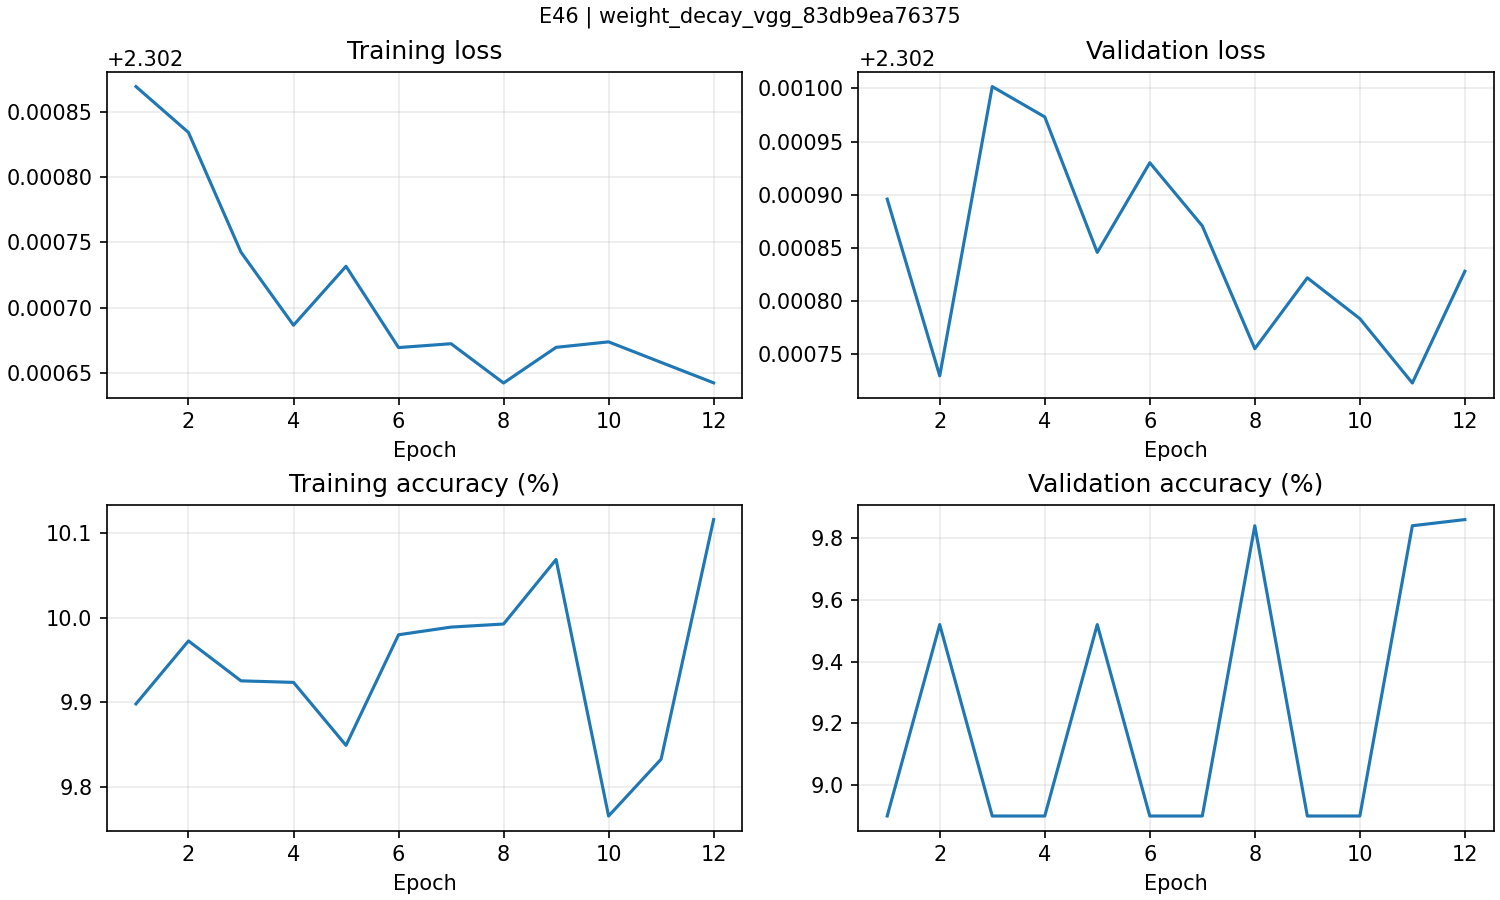

In [102]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_vgg_83db9ea76375.png')))

## E47: weight_decay_vgg_7fe0697cb5f1

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/zxgw1pkw

In [103]:
print((BASE / 'weight_decay_vgg_7fe0697cb5f1' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run zxgw1pkw
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_vgg_7fe0697cb5f1/wandb/run-20261104_023857-zxgw1pkw
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-38-57
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/zxgw1pkw
/home/link/link_dl
Namespace(wandb=True, batch_size=256, epochs=100, learning_rate=0.001, validation_intervals=1, early_stop_patience=1

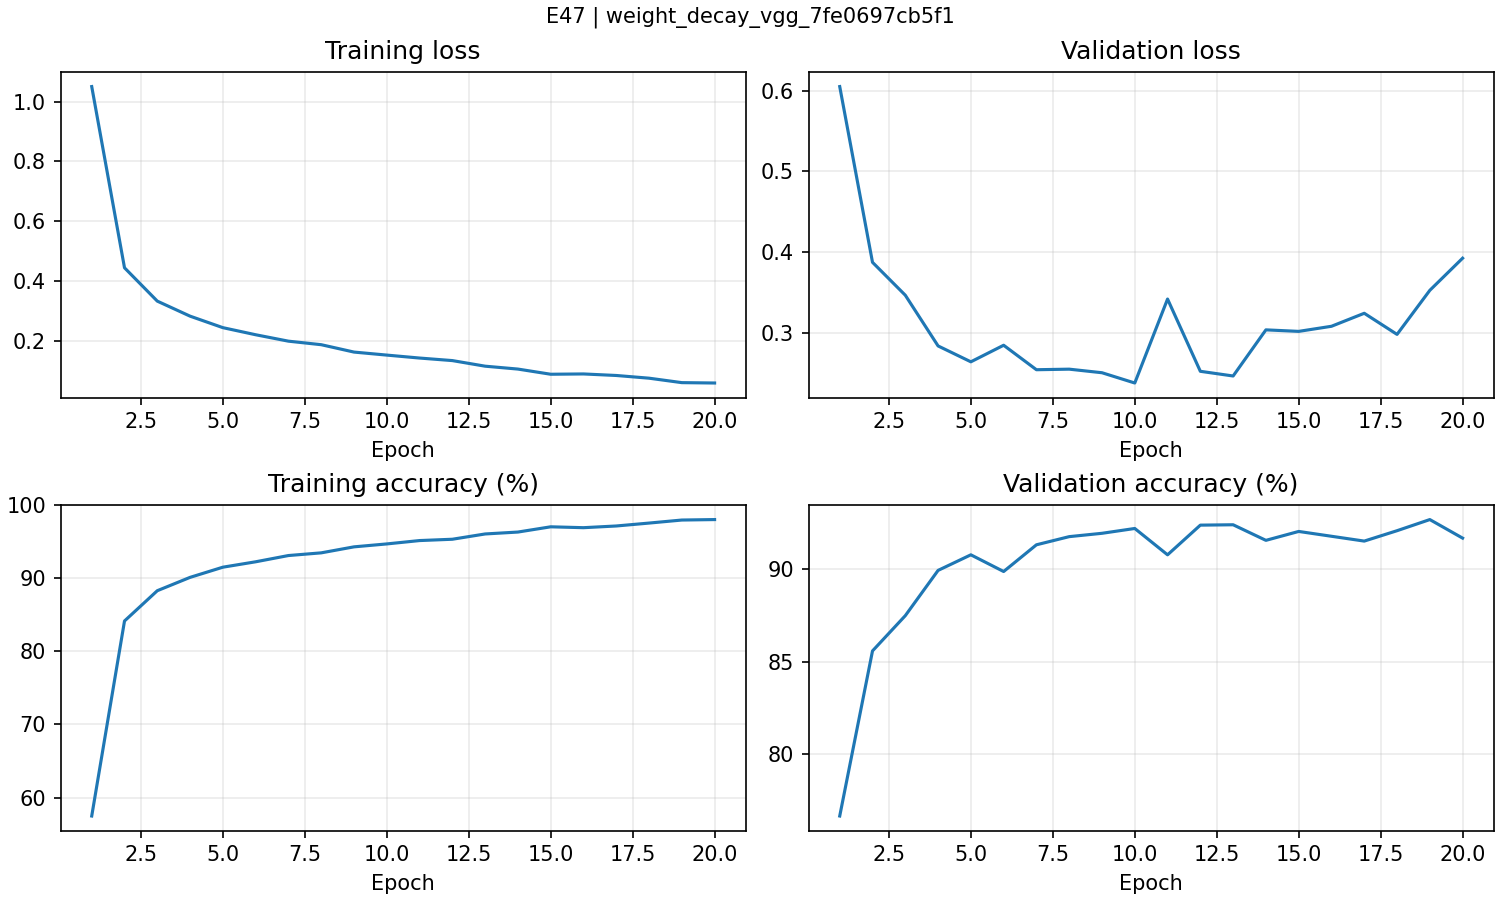

In [104]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_vgg_7fe0697cb5f1.png')))

## E48: weight_decay_vgg_80f26eb88014

W&B: https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/i1m8oj5h

In [105]:
print((BASE / 'weight_decay_vgg_80f26eb88014' / "train.log").read_text())

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/link/.netrc.
wandb: Currently logged in as: existenceone (existenceone-korea-university-of-technology-and-education) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /home/link/link_dl/_03_homeworks/homework_3/experiments/weight_decay_vgg_80f26eb88014/wandb/run-20261104_024203-i1m8oj5h
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run vgg_bn0_drop1_aug0_norm1_seed42_2026-11-04_02-42-03
wandb: ⭐️ View project at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist
wandb: 🚀 View run at https://wandb.ai/existenceone-korea-university-of-technology-and-education/cnn_fashion_mnist/runs/i1m8oj5h
wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 11-11, summary, console l

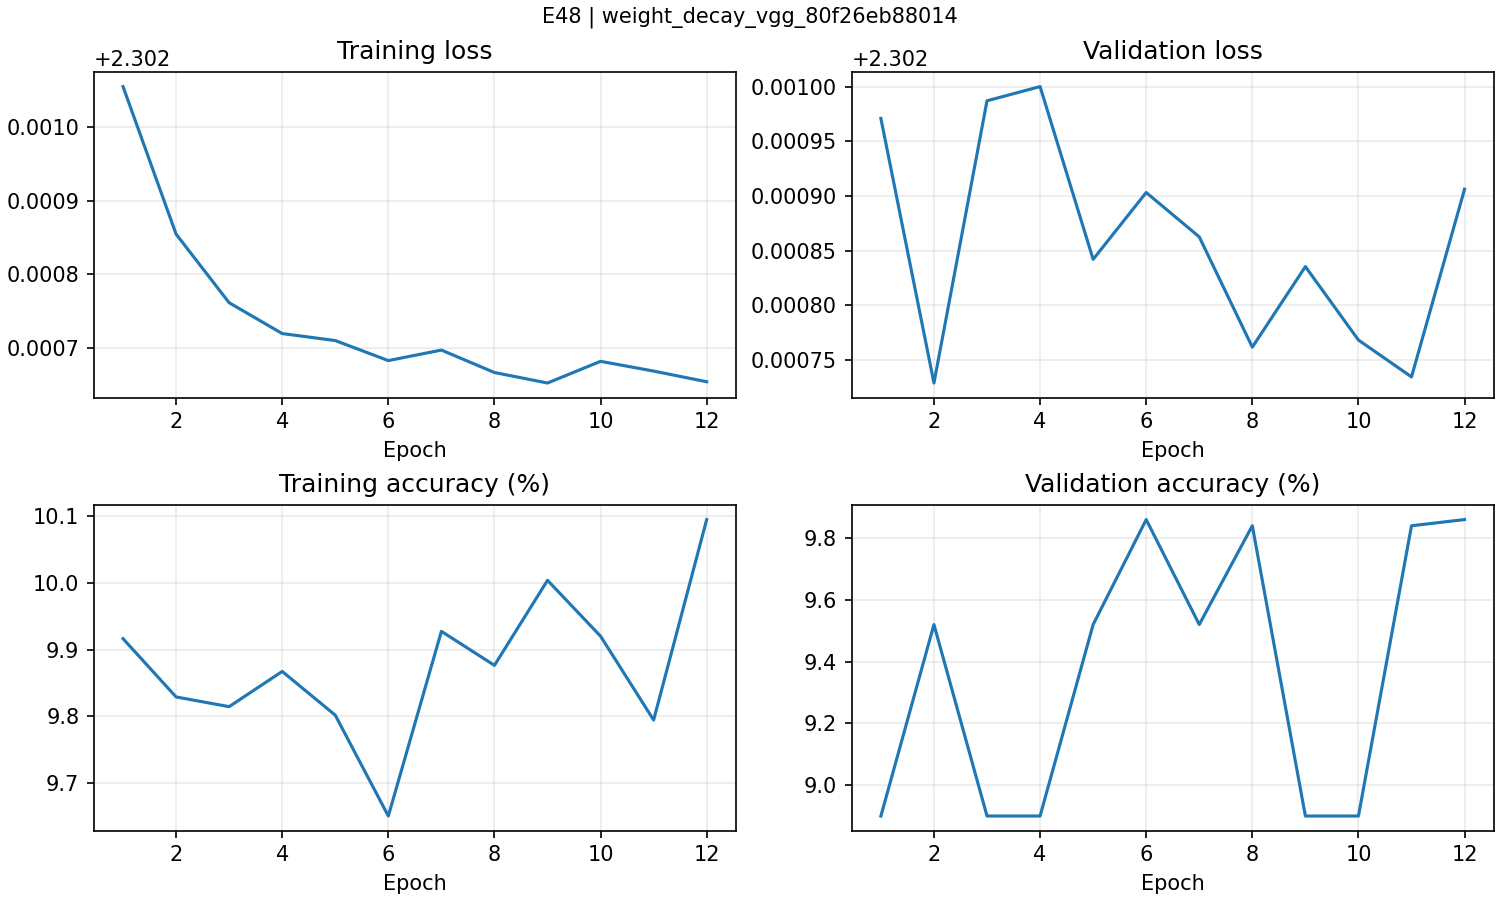

In [106]:
from IPython.display import Image, display
display(Image(filename=str(BASE / "figures" / 'weight_decay_vgg_80f26eb88014.png')))

## 실행 코드

기존 학습 코드와 원본 Trainer를 사용했으며, 별도 실행 스크립트가 GPU 픽셀 캐시와 로그 수집을 담당했다.

In [107]:
print(Path('/home/link/link_dl/_03_homeworks/homework_3/b_fashion_mnist_train.py').read_text())

import argparse
from datetime import datetime
import math
import os
from pathlib import Path
import sys

import torch
from torch import nn, optim
from torchvision import transforms
import wandb

BASE_PATH = str(Path(__file__).resolve().parent.parent.parent)
sys.path.append(BASE_PATH)

CURRENT_FILE_PATH = os.path.dirname(os.path.abspath(__file__))
CHECKPOINT_FILE_PATH = os.path.join(CURRENT_FILE_PATH, "checkpoints")

from _01_code._09_fcn_best_practice.c_trainer import ClassificationTrainer
from _01_code._14_normalization.a_cifar10_train_cnn_with_normalization import (
  get_cnn_model_with_dropout_and_batch_normalization,
)
from _01_code._15_data_augmentation.a_arg_parser import get_parser as get_base_parser
from _01_code._16_modern_cnns._01_vgg.a_cifar10_train_vgg import get_vgg_model
from _01_code._16_modern_cnns._02_nin.a_cifar10_train_nin import get_nin_model
from _01_code._16_modern_cnns._03_google_net.a_cifar10_train_google_net import get_google_net_model
from _01_code._16_modern_

In [108]:
print(Path('/home/link/link_dl/scripts/fashion_mnist_experiment.py').read_text())

"""Run one recorded Fashion MNIST experiment without changing the teaching code."""
import argparse
import hashlib
import importlib
import json
import os
from pathlib import Path
import sys
import time
from unittest.mock import patch

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))


def write_json(path, value):
    temporary = path.with_suffix('.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    temporary.replace(path)


def run_experiment(directory):
    import torch
    from torch.utils.data import TensorDataset
    import wandb

    directory = directory.resolve()
    configuration = json.loads((directory / 'config.json').read_text())
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA is required for these experiments')
    if int(os.environ.get('TRAIN_MAX_BATCHES', '0')):
        raise RuntimeError('TRAIN_MAX_BATCHES must be zero: full datasets are required')
    torch.set_num_threads(4

In [109]:
print(Path('/home/link/link_dl/scripts/fashion_mnist_study.py').read_text())

"""Sequential, resumable model-selection/tuning study. Never reads test data."""
import argparse
import hashlib
import itertools
import json
from pathlib import Path
import subprocess
import sys
import time

ROOT = Path(__file__).resolve().parents[1]
BASE = ROOT / '_03_homeworks/homework_3/experiments'


def write(path, value):
    temporary = path.with_suffix('.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False))
    temporary.replace(path)


def change(arguments, **changes):
    arguments = list(arguments)
    flags = {'batch_size': '-b', 'learning_rate': '-r', 'weight_decay': '-w',
             'seed': '--seed', 'normalization': '-n', 'dropout_rate': '--dropout_rate'}
    for name, value in changes.items():
        if name in ('augment', 'dropout'):
            arguments = [a for a in arguments if a not in ('--' + name, '--no-' + name)]
            arguments.append('--' + name if value else '--no-' + name)
        else:
            flag = flags[name]
     

In [110]:
print(Path('/home/link/link_dl/_03_homeworks/homework_3/c_fashion_mnist_test.py').read_text())

"""Evaluate a validation-selected Fashion MNIST checkpoint (HW problems 3 and 4)."""
import argparse
import csv
from datetime import datetime
import hashlib
import json
import math
from pathlib import Path
import sys
import textwrap
import time
from types import SimpleNamespace

import matplotlib
matplotlib.use('Agg')
from matplotlib import pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import torch
from torch import nn
from torchvision import transforms
import wandb

BASE_PATH = Path(__file__).resolve().parents[2]
sys.path.append(str(BASE_PATH))
CURRENT_PATH = Path(__file__).resolve().parent

from _03_homeworks.homework_3.a_fashion_mnist_data import (
  get_fashion_mnist_data, get_fashion_mnist_test_data,
)
from _03_homeworks.homework_3.b_fashion_mnist_train import get_fashion_mnist_model

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


def ge